# Python Pandas: The Complete Practical Session
## Hands-On Workbook with Real Datasets and Line-by-Line Explanations

**Kajola Gbenga**
**Data Scientist & AI Engineer**

---

This notebook is the **practical companion** to the textbook *"Python Pandas - The Complete Practical Guide"*. It follows the same **27 sections, in the same order**, so that every concept you read about can be **executed, changed and broken** here on realistic Nigerian business data.

### What makes this session different

* **16 ready-made datasets** in CSV, Excel, JSON, Parquet, SQLite and HTML, deliberately **messy** (missing values, duplicates, wrong types, inconsistent text) so that every cleaning technique has something real to clean.
* **Every line of code has a comment** explaining exactly what it does.
* Every section ends with **"Your turn"** challenges, and the notebook finishes with a **capstone business analysis** and **solutions to exercises**.
* Works on **pandas 2.2 or newer, including pandas 3.x**. Where behaviour changed between versions you will see a **Version note**.

### The datasets (all inside the `DATA` folder)

| File | Format | Rows (approx.) | Used for |
|------|--------|----------------|----------|
| `employees.csv` | CSV | 632 | Selecting, cleaning, strings, groupby, MultiIndex (messy on purpose) |
| `customers.csv` | CSV | 900 | Merging with orders |
| `orders.csv` | CSV | 3,206 | The end-to-end retail worked example and capstone |
| `daily_sales.csv` | CSV | 1,638 | Time series, resampling, rolling windows |
| `web_traffic_hourly.csv` | CSV | 336 | Time zones (UTC to Africa/Lagos) |
| `salary_history.csv` | CSV | 1,352 | Merge with a **different key name** and one-to-many joins |
| `regional_sales.csv` | CSV | 96 | `pivot_table` and `crosstab` (long format) |
| `regional_sales_wide.csv` | CSV | 6 | `melt` (wide format) |
| `student_scores_wide.csv` | CSV | 40 | `wide_to_long` |
| `transactions_large.csv` | CSV | 150,000 | Chunked reading, performance |
| `transactions.parquet` | Parquet | 150,000 | Parquet vs CSV, dtype preservation |
| `report.xlsx` | Excel | 4 quarter sheets + summary | `read_excel`, `skiprows`, `sheet_name=None` |
| `departments.xlsx` | Excel | 8 | Merging employees with department data |
| `products.json` | JSON | 24 | `read_json(orient="records")` |
| `company.db` | SQLite | 3 tables | `read_sql` with SQLAlchemy |
| `nigerian_states.html` | HTML | 2 tables | `read_html` |

> **How to use:** run cells from top to bottom with `Shift + Enter`. Later cells reuse variables created earlier. If you ever break something, re-run from the top, or from the nearest "Reset point" cell.

---
# SECTION 1: Introduction to Pandas

**Pandas** is the standard Python library for tabular data. Its two core structures are:

| Structure | Dimensions | Think of it as |
|-----------|------------|----------------|
| `Series` | 1-D | one labelled column |
| `DataFrame` | 2-D | a table made of Series that share the same row index |

Why pandas matters in practice:

1. It replaces slow manual loops with fast **vectorised** operations.
2. Rows and columns have **labels**, so you do not track raw positions.
3. It handles **missing values, mixed types and messy text** gracefully.
4. One-line methods exist for filtering, grouping, merging, reshaping and resampling.
5. It reads and writes **CSV, Excel, JSON, SQL, Parquet and HTML**.

In this session you will do all of these, on data that looks like what you meet at work.

---
# SECTION 2: Setting Up the Environment

### 2.1 Installing pandas and its helpers

Run the following **once** in a terminal (or in a notebook cell by putting `!` in front):

```bash
pip install pandas numpy openpyxl xlrd pyarrow sqlalchemy lxml matplotlib
```

| Package | Why we need it |
|---------|----------------|
| `pandas` | the library itself |
| `numpy` | arrays, `np.nan`, `np.where`, `np.select` |
| `openpyxl` | read and write modern `.xlsx` files |
| `xlrd` | read legacy `.xls` files |
| `pyarrow` | Parquet files and Arrow-backed types |
| `sqlalchemy` | connect pandas to databases |
| `lxml` | lets `read_html` parse HTML tables |
| `matplotlib` | the plotting engine behind `df.plot()` |

In [307]:
import pandas as pd                          # import pandas under its conventional alias pd
import numpy as np                           # import numpy under its conventional alias np
import os                                    # os lets us work with files and folders
import time                                  # time lets us measure how long operations take
import warnings                              # warnings lets us catch and display pandas warnings on purpose

pd.set_option("display.max_columns", None)   # never hide columns when a wide table is printed
pd.set_option("display.max_rows", 100)       # show at most 100 rows when a long table is printed
pd.set_option("display.width", 120)          # wrap printed tables at 120 characters
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")   # show floats with thousands separators and 2 decimals

DATA = "DATA"                     # folder that holds all the practice datasets
OUT_DIR = "pandas_outputs"                   # folder where our exported results will be written
os.makedirs(OUT_DIR, exist_ok=True)          # create the output folder if it does not already exist

print("pandas version:", pd.__version__)     # show the pandas version (this notebook needs 2.2 or newer)
print("numpy  version:", np.__version__)     # show the numpy version

pandas version: 2.3.1
numpy  version: 2.5.2


### 2.2 Why the pandas version matters

Pandas changed noticeably between versions. The most important changes you will meet in this notebook:

| Topic | Older pandas (1.x / 2.0) | Current pandas (2.2+ and 3.x) |
|-------|--------------------------|-------------------------------|
| Fill forward | `df.fillna(method="ffill")` | `df.ffill()` (the `method=` argument was **removed** in 3.0) |
| Month-end resampling | `resample("M")` | `resample("ME")` (`"M"`, `"Q"`, `"H"` aliases deprecated, then removed) |
| Cell-wise function | `df.applymap(f)` | `df.map(f)` |
| Text columns | `object` dtype | dedicated `str` dtype (default in 3.0) |
| Chained assignment | sometimes worked, with `SettingWithCopyWarning` | **never** modifies the original (Copy-on-Write) |

**Version note:** if your guide shows the old spelling, use the new spelling here. The behaviour is the same.

### 2.3 Verify that all practice datasets are present

In [308]:
expected_files = [                           # the list of files this notebook depends on
    "employees.csv", "customers.csv", "orders.csv", "daily_sales.csv", "web_traffic_hourly.csv",
    "salary_history.csv", "regional_sales.csv", "regional_sales_wide.csv", "student_scores_wide.csv",
    "transactions_large.csv", "transactions.parquet", "report.xlsx", "departments.xlsx",
    "products.json", "company.db", "nigerian_states.html",
]

present = sorted(os.listdir(DATA))           # list the files that really exist in the data folder
missing = [f for f in expected_files if f not in present]   # list comprehension: expected files that are absent

for f in expected_files:                     # loop over every expected file
    size_kb = os.path.getsize(os.path.join(DATA, f)) / 1024 if f in present else float("nan")   # size in KB or NaN
    print(f"{f:28s} {size_kb:10,.1f} KB")    # print the name and size, aligned in columns

assert not missing, f"Missing files: {missing}. Run generate_datasets.py first."   # stop with a clear message if any file is absent
print("\nAll datasets found. You are ready to go.")   # confirmation message

employees.csv                     122.8 KB
customers.csv                      38.7 KB
orders.csv                        249.0 KB
daily_sales.csv                    58.9 KB
web_traffic_hourly.csv              7.9 KB
salary_history.csv                 23.3 KB
regional_sales.csv                  3.2 KB
regional_sales_wide.csv             0.3 KB
student_scores_wide.csv             1.5 KB
transactions_large.csv          9,703.8 KB
transactions.parquet            3,333.3 KB
report.xlsx                        10.1 KB
departments.xlsx                    5.5 KB
products.json                       3.3 KB
company.db                        156.0 KB
nigerian_states.html                4.1 KB

All datasets found. You are ready to go.


---
# SECTION 3: Core Data Structures: Series and DataFrame

### 3.1 The Series

A Series has three parts: the **values**, the **index** (labels) and an optional **name**.

In [309]:
s = pd.Series([10, 20, 30, 40], index=["a", "b", "c", "d"], name="scores")   # values, custom labels and a name
print(s)                                     # show the whole Series including its name and dtype
print("-" * 30)                              # a divider line
print("values :", s.values)                  # the underlying numpy array of values
print("index  :", s.index)                   # the Index object holding the labels
print("name   :", s.name)                    # the Series name
print("s['c'] :", s["c"])                    # access one value by its label
print("s[0]   :", s.iloc[0])                 # access one value by position (iloc is the explicit way)
print("s * 2  :\n", s * 2)                  # arithmetic is applied to every value at once (vectorised)

a    10
b    20
c    30
d    40
Name: scores, dtype: int64
------------------------------
values : [10 20 30 40]
index  : Index(['a', 'b', 'c', 'd'], dtype='object')
name   : scores
s['c'] : 30
s[0]   : 10
s * 2  :
 a    20
b    40
c    60
d    80
Name: scores, dtype: int64


### 3.2 The DataFrame

In [310]:
people = pd.DataFrame({                      # build a DataFrame from a dictionary of lists
    "name": ["Ada", "Grace", "Alan"],        # each key becomes a column name
    "age": [36, 85, 41],                     # each list becomes that column's values
    "field": ["Mathematics", "Computer Science", "Computer Science"],   # all lists must have the same length
})
print(people)                                # print the table
print(type(people["age"]))                   # selecting one column returns a Series, proving a DataFrame is built from Series

    name  age             field
0    Ada   36       Mathematics
1  Grace   85  Computer Science
2   Alan   41  Computer Science
<class 'pandas.core.series.Series'>


### 3.3 Key attributes

We will now load our first real dataset, `employees.csv`, and look at its attributes.

In [311]:
emp = pd.read_csv(f"{DATA}/employees.csv")   # load the raw employee file exactly as it is (no cleaning yet)

print("shape  :", emp.shape)                 # (number of rows, number of columns)
print("ndim   :", emp.ndim)                  # 2 because a DataFrame has rows and columns
print("size   :", emp.size)                  # rows multiplied by columns
print("columns:", list(emp.columns))         # the column names in order
print("index  :", emp.index)                 # a RangeIndex 0..n-1 by default
print("values type:", type(emp.values))      # .values gives a plain numpy array without labels
print()                                      # blank line
print(emp.dtypes)                            # the data type of every column

shape  : (632, 17)
ndim   : 2
size   : 10744
columns: ['id', 'name', 'department', 'salary', 'hire_date', 'email', 'phone', 'age', 'city', 'is_manager', 't_shirt_size', 'skills', 'status', 'q1', 'q2', 'q3', 'q4']
index  : RangeIndex(start=0, stop=632, step=1)
values type: <class 'numpy.ndarray'>

id                int64
name             object
department       object
salary           object
hire_date        object
email            object
phone            object
age             float64
city             object
is_manager         bool
t_shirt_size     object
skills           object
status           object
q1              float64
q2              float64
q3              float64
q4              float64
dtype: object


**Observe carefully.** `id` was read as an integer, so the leading zeros (`00001`) are gone. `salary` is text because some cells contain words such as `confidential`. We will fix both problems in later sections. This is exactly why you always inspect before you analyse.

### Your turn (Section 3)
1. Create a Series of the five largest Nigerian cities with their populations of your choice, using a dictionary.
2. From `emp`, print the number of **elements** (`size`) and the number of **dimensions** (`ndim`).

---
# SECTION 4: Creating Series and DataFrames

### 4.1 Creating a Series from different sources

In [312]:
s1 = pd.Series([1, 2, 3])                              # from a list: default integer index 0, 1, 2
s2 = pd.Series({"a": 1, "b": 2, "c": 3})               # from a dict: keys become the index labels
s3 = pd.Series(5, index=["x", "y", "z"])               # from a scalar: 5 is repeated for every label
s4 = pd.Series(np.arange(5))                           # from a numpy array: arange(5) gives 0..4
s5 = pd.Series(pd.date_range("2026-01-01", periods=3)) # from a date range: a Series of Timestamps

for label, series in [("list", s1), ("dict", s2), ("scalar", s3), ("numpy", s4), ("dates", s5)]:   # loop to print them all
    print(f"--- from {label}")                          # a heading for each Series
    print(series.to_string())                           # to_string prints without the footer, saving space

--- from list
0    1
1    2
2    3
--- from dict
a    1
b    2
c    3
--- from scalar
x    5
y    5
z    5
--- from numpy
0    0
1    1
2    2
3    3
4    4
--- from dates
0   2026-01-01
1   2026-01-02
2   2026-01-03


### 4.2 Creating a DataFrame from different sources

In [313]:
df1 = pd.DataFrame({"a": [1, 2], "b": [3, 4]})                       # column oriented: dict of lists
df2 = pd.DataFrame([[1, 3], [2, 4]], columns=["a", "b"])             # row oriented: list of lists plus column names
df3 = pd.DataFrame([{"a": 1, "b": 3}, {"a": 2, "b": 4}])             # list of dicts: typical shape of JSON API records
rng = np.random.default_rng(42)                                       # reproducible random number generator
df4 = pd.DataFrame(rng.integers(0, 100, (5, 3)), columns=["x", "y", "z"])   # from a numpy array of random integers
df5 = pd.DataFrame({"a": pd.Series([1, 2, 3]), "b": pd.Series([9, 8], index=[0, 1])})   # dict of Series: aligned on index

print(df1.equals(df2), df2.equals(df3))      # all three of the first creations produce identical tables: True True
print(df4)                                   # the random table
print(df5)                                   # b is NaN at index 2 because that label was missing in the second Series

True True
    x   y   z
0   8  77  65
1  43  43  85
2   8  69  20
3   9  52  97
4  73  76  71
   a    b
0  1 9.00
1  2 8.00
2  3  NaN


### 4.3 Empty and placeholder DataFrames

In [314]:
df_empty = pd.DataFrame(columns=["id", "name", "value"])   # defined columns but zero rows (a template)
df_nan = pd.DataFrame(np.nan, index=range(3), columns=["a", "b"])   # fixed shape pre-filled with NaN

print(df_empty.shape, list(df_empty.columns))   # (0, 3) and the three column names
print(df_nan)                                   # a 3 x 2 table of NaN, ready to be filled in progressively

df_nan.loc[0, "a"] = 10                         # fill one cell using label based assignment
df_nan.loc[1, :] = [20, 30]                     # fill an entire row with a list of values
print(df_nan)                                   # the partially filled table

(0, 3) ['id', 'name', 'value']
    a   b
0 NaN NaN
1 NaN NaN
2 NaN NaN
      a     b
0 10.00   NaN
1 20.00 30.00
2   NaN   NaN


### 4.4 Creating DataFrames from the real data sources

The same `DataFrame` object can come from many sources. Here is a quick tour; each is studied in depth in Section 5.

In [315]:
from_csv = pd.read_csv(f"{DATA}/customers.csv")        # CSV file to DataFrame
from_json = pd.read_json(f"{DATA}/products.json")      # JSON file to DataFrame
from_excel = pd.read_excel(f"{DATA}/departments.xlsx") # Excel file to DataFrame

for name, frame in [("customers.csv", from_csv), ("products.json", from_json), ("departments.xlsx", from_excel)]:   # loop
    print(f"{name:18s} shape = {frame.shape}")         # print the name and shape of each loaded table

print(from_json.head(3))                               # preview the first three products

customers.csv      shape = (900, 5)
products.json      shape = (24, 6)
departments.xlsx   shape = (8, 4)
  product_id        name     category   price  rating  stock
0       P001  Smartphone  Electronics  185000    4.40     52
1       P002      Laptop  Electronics  650000    3.70     89
2       P003     Earbuds  Electronics   28000    4.20    294


### Your turn (Section 4)
1. Create a DataFrame of 4 Nigerian banks with columns `bank`, `founded` and `hq_city` using **three different methods** (dict of lists, list of lists, list of dicts) and confirm they are equal with `.equals()`.
2. Create an empty DataFrame with columns `date`, `store`, `sales` and fill two rows into it with `.loc`.

---
# SECTION 5: Loading Data From Files

### 5.1 Reading CSV files with options

`read_csv` has dozens of options. The cell below uses the ones from the guide on `orders.csv`.

In [316]:
orders_preview = pd.read_csv(                          # read the orders file using several control options
    f"{DATA}/orders.csv",                              # path to the file
    sep=",",                                           # delimiter between values (comma is the default)
    header=0,                                          # the first row (index 0) holds the column names
    usecols=["order_id", "order_date", "customer_id", "product_category", "unit_price", "quantity", "region"],   # load only these columns
    parse_dates=["order_date"],                        # convert order_date from text into real datetimes while reading
    dtype={"customer_id": str},                        # force customer_id to stay as text
    na_values=["NA", "N/A", "null", "unknown"],        # extra strings that must be treated as missing
    nrows=1000,                                        # read only the first 1000 rows (a quick preview)
)

print(orders_preview.shape)                            # (1000, 7): only 7 columns and 1000 rows were loaded
print(orders_preview.dtypes)                           # order_date is datetime64, customer_id is text, unit_price is numeric
print(orders_preview.head(3))                          # preview three rows

(1000, 7)
order_id                    object
order_date          datetime64[ns]
customer_id                 object
product_category            object
unit_price                 float64
quantity                     int64
region                      object
dtype: object
     order_id order_date customer_id product_category  unit_price  quantity  region
0  ORD-000001 2026-06-14       C0327   Home & Kitchen  115,600.00         5  Ibadan
1  ORD-000001 2026-06-14       C0327   Home & Kitchen   45,700.00         1  Ibadan
2  ORD-000002 2026-02-10       C0567        Groceries   55,300.00         1   Lagos


**Why `dtype={"id": str}` matters.** Let us prove what happens to the employee ids when we do **not** protect them:

In [317]:
no_protection = pd.read_csv(f"{DATA}/employees.csv", usecols=["id", "name"], nrows=3)                  # default reading
with_protection = pd.read_csv(f"{DATA}/employees.csv", usecols=["id", "name"], nrows=3, dtype={"id": str})   # id kept as text

print(no_protection)                                   # ids look like 565, 489, 98 so the leading zeros are lost
print(with_protection)                                 # ids look like 00565, 00489, 00098 as they should

    id           name
0  565   Ngozi Chukwu
1  489    bisi nwosu 
2   98  Aisha Akinola
      id           name
0  00565   Ngozi Chukwu
1  00489    bisi nwosu 
2  00098  Aisha Akinola


**Why we did not use `parse_dates` on `employees.csv`:** the `hire_date` column contains the text `not available` in a few rows, which cannot be parsed. Instead we load it as text and convert it safely later with `pd.to_datetime(..., errors="coerce")` in Section 11. Choosing the right moment to convert is part of the craft.

Now we load the employee table the way we will use it for the rest of the session:

In [318]:
emp = pd.read_csv(                                     # load the employee file for the main analysis
    f"{DATA}/employees.csv",                           # path to the file
    dtype={"id": str},                                 # keep ids as text so leading zeros survive
    na_values=["NA", "N/A", "null"],                   # treat these strings as missing values
)
emp = emp.rename(columns={"id": "employee_id"})        # rename id to employee_id, the name used in the guide
print(emp.shape)                                       # (632, 17)
emp.head()                                             # preview the first five rows

(632, 17)


,employee_id,name,department,salary,hire_date,email,phone,age,city,is_manager,t_shirt_size,skills,status,q1,q2,q3,q4
0,00565,Ngozi Chukwu,Engineering,108200.0,2024-07-06,ngozi.chukwu@outlook.com,+234 908 536 0565,35.00,Enugu,False,Small,cloud|sql,active,NaN,64.14,80.49,55.35
1,00489,bisi nwosu,Engineering,110500.0,2021-08-29,bisi.nwosu@gmail.com,+234 814 768 7188,32.00,Port Harcourt,False,Small,statistics,active,71.41,NaN,55.88,57.05
2,00098,Aisha Akinola,Marketing,115700.0,2022-05-13,NaN,0805-191-0136,38.00,Abuja,False,Large,cloud,active,60.72,74.74,62.57,72.46
3,00454,Nneka Nnamdi,Support,106400.0,2017-01-05,nneka.nnamdi@yahoo.com,+234 805 180 1091,38.00,Lagos,True,Large,python|sql,inactive,87.21,74.06,64.99,78.66
4,00431,Zainab Olawale,Sales,79300.0,2019-02-10,zainab.olawale@gmail.com,(0805) 1102234,34.00,Port Harcourt,False,Large,statistics,active,79.97,76.45,82.14,100.00


### 5.2 Reading Excel files

In [319]:
q3 = pd.read_excel(f"{DATA}/report.xlsx", sheet_name="Q3", skiprows=2, engine="openpyxl")   # one sheet, skipping 2 title rows
print(q3.head())                                       # the header row was found correctly because we skipped the titles

wrong = pd.read_excel(f"{DATA}/report.xlsx", sheet_name="Q3")   # forgetting skiprows to see the problem
print(wrong.head(3))                                   # the title text became the header and the real header became data

all_sheets = pd.read_excel(f"{DATA}/report.xlsx", sheet_name=None, skiprows=2)   # None means read EVERY sheet into a dict
print(type(all_sheets), list(all_sheets.keys()))       # a dict whose keys are the sheet names

for sheet_name, sheet_df in all_sheets.items():        # loop over the dictionary
    print(sheet_name, sheet_df.shape)                  # the shape of each sheet (the Summary sheet had no title rows)

  region    product_line    sales  units   target
0  Lagos     Electronics  6554999    134  3400000
1  Lagos         Fashion  6439999    875  4600000
2  Lagos       Groceries  3564999    332  1300000
3  Lagos  Home & Kitchen  3679999    494  1900000
4  Abuja     Electronics  3564999    325  4000000
     Prodigy Mart Regional Sales Report    Unnamed: 1 Unnamed: 2 Unnamed: 3 Unnamed: 4
0  Quarter 3, 2026 (all figures in NGN)           NaN        NaN        NaN        NaN
1                                region  product_line      sales      units     target
2                                 Lagos   Electronics    6554999        134    3400000
<class 'dict'> ['Q1', 'Q2', 'Q3', 'Q4', 'Summary']
Q1 (24, 5)
Q2 (24, 5)
Q3 (24, 5)
Q4 (24, 5)
Summary (0, 2)


**Version note:** reading legacy `.xls` files needs `engine="xlrd"`; modern `.xlsx` files use `engine="openpyxl"` (the default).

### 5.3 Reading JSON, SQL, Parquet and HTML

In [320]:
df_json = pd.read_json(f"{DATA}/products.json", orient="records")   # JSON stored as a list of row-like dictionaries
print(df_json.head(3))                                 # preview the JSON products

df_parquet = pd.read_parquet(f"{DATA}/transactions.parquet", engine="pyarrow")   # fast columnar format
print(df_parquet.shape)                                # 150,000 rows
print(df_parquet.dtypes)                               # dtypes (category, datetime, int32) are preserved exactly

df_html = pd.read_html(f"{DATA}/nigerian_states.html")   # returns a LIST with one DataFrame per HTML table on the page
print(len(df_html), "tables found")                    # the page has two tables
print(df_html[0].head(3))                              # [0] selects the first table (states and capitals)
print(df_html[1])                                      # the second table (states per zone)

  product_id        name     category   price  rating  stock
0       P001  Smartphone  Electronics  185000    4.40     52
1       P002      Laptop  Electronics  650000    3.70     89
2       P003     Earbuds  Electronics   28000    4.20    294
(150000, 7)
txn_id                int32
timestamp    datetime64[us]
channel            category
store              category
amount              float64
currency             object
status             category
dtype: object
2 tables found
   State  Capital Geopolitical Zone
0  Benue  Makurdi     North Central
1   Kogi   Lokoja     North Central
2  Kwara   Ilorin     North Central
  Geopolitical Zone  Number of States
0     North Central                 7
1        North East                 6
2        North West                 7
3        South East                 5
4       South South                 6
5        South West                 6


In [321]:
from sqlalchemy import create_engine                   # SQLAlchemy builds the connection to a database

engine = create_engine(f"sqlite:///{DATA}/company.db") # open a connection to the SQLite file database
df_sql = pd.read_sql("SELECT * FROM employees WHERE active = 1", con=engine)   # run SQL and load the result as a DataFrame
print(df_sql.shape)                                    # only active employees were returned
print(df_sql.head(3))                                  # preview the SQL result

tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con=engine)   # ask SQLite which tables exist
print(tables["name"].tolist())                         # ['employees', 'departments', 'orders']

dept_budget = pd.read_sql("SELECT department, SUM(salary) AS payroll FROM employees GROUP BY department", con=engine)   # SQL aggregation
print(dept_budget)                                     # let the database do the heavy lifting, pandas receives the summary

(265, 6)
      id           name department     salary   hire_date  active
0  00001     Emeka Igwe  Marketing  96,600.00  2014-10-29       1
1  00002  Amaka Ibrahim    Finance 137,100.00  2025-07-15       1
2  00003    Aisha Bello  Marketing 140,600.00  2020-07-03       1
['employees', 'departments', 'orders']
    department      payroll
0  Engineering 6,669,300.00
1      Finance 5,303,000.00
2           HR 2,730,300.00
3    Marketing 3,766,200.00
4   Operations 4,784,300.00
5        Sales 5,472,400.00
6      Support 3,364,500.00


### 5.4 Chunked reading for large files

`transactions_large.csv` has 150,000 rows. Imagine it had 150 million. Reading in **chunks** keeps memory use small.

In [322]:
chunks = []                                            # list that will collect the filtered pieces
rows_seen = 0                                          # counter for the total rows scanned

for chunk in pd.read_csv(f"{DATA}/transactions_large.csv", chunksize=40_000):   # iterator yielding 40,000 rows at a time
    rows_seen += len(chunk)                            # count the rows in this chunk
    processed = chunk[(chunk["amount"] > 0) & (chunk["status"] == "success")]   # keep only positive, successful payments
    chunks.append(processed)                           # store the small filtered chunk instead of the full one

big = pd.concat(chunks, ignore_index=True)             # stitch the chunks together, building a fresh continuous index
print("rows scanned :", rows_seen)                     # 150000
print("rows kept    :", len(big))                      # fewer rows because of the filter
print(big.head(3))                                     # preview the result

rows scanned : 150000
rows kept    : 135267
   txn_id            timestamp channel              store    amount currency   status
0  126046  2026-01-01 00:01:11     Web        Lagos-Ikeja 10,405.64      NGN  success
1  132976  2026-01-01 00:05:09     POS        Lagos-Ikeja 23,068.15      NGN  success
2   35184  2026-01-01 00:06:36    USSD  Port Harcourt-GRA 46,852.15      NGN  success


### Your turn (Section 5)
1. Read only the columns `store`, `amount` and `channel` from `transactions_large.csv`, using `usecols`, and the first 5,000 rows.
2. Read the `Q1` sheet of `report.xlsx` and print the total of the `sales` column.
3. Use `read_sql` to count how many orders exist in the `orders` table of `company.db`.

---
# SECTION 6: Initial Data Inspection

**Golden rule:** never clean or analyse data you have not first inspected. These commands are the first thing to run on any new file.

### 6.1 Shape and preview

In [323]:
print(emp.shape)                                       # rows and columns
display(emp.head(10))                                  # the first 10 rows (default is 5)
display(emp.tail(5))                                   # the last 5 rows: good for spotting footer or total rows
display(emp.sample(5, random_state=1))                 # 5 random rows; random_state makes the sample repeatable

(632, 17)


,employee_id,name,department,salary,hire_date,email,phone,age,city,is_manager,t_shirt_size,skills,status,q1,q2,q3,q4
0,00565,Ngozi Chukwu,Engineering,108200.0,2024-07-06,ngozi.chukwu@outlook.com,+234 908 536 0565,35.00,Enugu,False,Small,cloud|sql,active,NaN,64.14,80.49,55.35
1,00489,bisi nwosu,Engineering,110500.0,2021-08-29,bisi.nwosu@gmail.com,+234 814 768 7188,32.00,Port Harcourt,False,Small,statistics,active,71.41,NaN,55.88,57.05
2,00098,Aisha Akinola,Marketing,115700.0,2022-05-13,NaN,0805-191-0136,38.00,Abuja,False,Large,cloud,active,60.72,74.74,62.57,72.46
3,00454,Nneka Nnamdi,Support,106400.0,2017-01-05,nneka.nnamdi@yahoo.com,+234 805 180 1091,38.00,Lagos,True,Large,python|sql,inactive,87.21,74.06,64.99,78.66
4,00431,Zainab Olawale,Sales,79300.0,2019-02-10,zainab.olawale@gmail.com,(0805) 1102234,34.00,Port Harcourt,False,Large,statistics,active,79.97,76.45,82.14,100.00
5,00305,Hauwa Bello,Engineering,154800.0,2021-05-24,hauwa.bello@prodigy.ng,+234 806 680 1497,29.00,Ibadan,False,Large,excel|power bi|tableau,active,54.43,74.23,60.43,81.39
6,00145,Amaka Yusuf,Support,confidential,2019-02-08,amaka.yusuf@gmail.com,+234 810 685 9058,41.00,Enugu,False,Medium,power bi,active,74.46,73.61,NaN,74.07
7,00061,Nneka Salami,Marketing,141500.0,2022-12-10,nneka.salami@prodigy.ng,0908-572-9744,34.00,Lagos,True,Medium,cloud|tableau|python,active,62.98,78.00,79.63,81.81
8,00330,Kunle Nnamdi,Marketing,134900.0,2014-09-10,kunle.nnamdi@yahoo.com,0810-797-0657,43.00,Lagos,True,Large,power bi,active,92.82,44.94,67.19,85.33
9,00570,sadiq mohammed,Support,100200.0,2025-05-22,sadiq.mohammed@gmail.com,+234 805 233 8692,38.00,Kano,True,Large,sql,active,61.82,62.87,83.47,76.00


,employee_id,name,department,salary,hire_date,email,phone,age,city,is_manager,t_shirt_size,skills,status,q1,q2,q3,q4
627,00481,gift adebayo,Operations,107100.0,2017-01-10,gift.adebayo@prodigy.ng,09038591361,21.00,Lagos,False,Small,r|statistics,active,91.49,59.29,82.17,62.39
628,00423,Tobi Mohammed,Sales,80500.0,2019-04-25,tobi.mohammed@gmail.com,+234 810 542 6363,29.00,Lagos,False,Small,tableau|power bi|statistics,active,79.61,NaN,81.86,68.77
629,00120,Gift Okafor,Engineering,190000.0,2024-12-27,gift.okafor@prodigy.ng,+234 803 509 7806,34.00,Lagos,True,Medium,statistics|python|r,inactive,67.49,49.75,79.73,78.28
630,00257,Ebere Ogunleye,Operations,68200.0,2024-11-05,ebere.ogunleye@prodigy.ng,+234 908 698 9708,39.00,Abuja,False,Medium,python|cloud|tableau,active,62.36,58.86,70.10,58.42
631,00250,Tunde Balogun,Engineering,174800.0,2015-07-21,tunde.balogun@gmail.com,08038419776,34.00,Port Harcourt,False,Large,cloud|r,active,64.36,86.45,45.69,79.94


,employee_id,name,department,salary,hire_date,email,phone,age,city,is_manager,t_shirt_size,skills,status,q1,q2,q3,q4
101,00387,Amaka Ogunleye,Engineering,136500.0,2023-04-11,amaka.ogunleye@outlook.com,+234 803 832 5482,29.00,Lagos,False,Medium,python|tableau,active,78.63,59.87,81.94,63.88
575,00608,SEGUN IGWE,Sales,89400.0,2023-10-25,segun.igwe@gmail.com,08147668078,32.00,Kano,False,Medium,statistics,active,64.47,68.42,57.86,56.46
407,00376,amaka okeke,Sales,84600.0,2017-08-04,amaka.okeke@prodigy.ng,09088816309,27.00,Kano,False,Large,power bi|sql|cloud,active,66.08,59.48,44.11,45.07
441,00030,lanre olawale,Sales,81400.0,2023-12-23,lanre.olawale@yahoo.com,+234 814 804 8293,24.00,Kano,False,Medium,excel|python|power bi,active,93.76,67.11,74.96,70.99
223,00187,Mariam Mohammed,HR,64200.0,2020-10-22,mariam.mohammed@outlook.com,+234 806 653 0442,37.00,Lagos,False,Small,python|statistics,active,85.59,84.67,50.17,78.52


### 6.2 Structural summary

In [324]:
emp.info()                                             # columns, non-null counts, dtypes and memory in one view
print("-" * 60)                                        # divider
emp.info(memory_usage="deep")                          # deep memory usage inspects the text columns for an accurate figure

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 632 entries, 0 to 631
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   employee_id   632 non-null    object 
 1   name          632 non-null    object 
 2   department    614 non-null    object 
 3   salary        595 non-null    object 
 4   hire_date     626 non-null    object 
 5   email         611 non-null    object 
 6   phone         632 non-null    object 
 7   age           615 non-null    float64
 8   city          632 non-null    object 
 9   is_manager    632 non-null    bool   
 10  t_shirt_size  632 non-null    object 
 11  skills        632 non-null    object 
 12  status        632 non-null    object 
 13  q1            603 non-null    float64
 14  q2            605 non-null    float64
 15  q3            604 non-null    float64
 16  q4            603 non-null    float64
dtypes: bool(1), float64(5), object(11)
memory usage: 79.7+ KB
---------------

**Read the `info()` output like a detective.**

* Columns with fewer non-null values than the row count (632) have missing data.
* `salary` is stored as text (`str`) even though it should be numeric. Something non-numeric is hiding in it.
* `hire_date` is text, not a date.

### 6.3 Descriptive statistics

In [325]:
display(emp.describe())                                # count, mean, std, min, quartiles and max for numeric columns
display(emp.describe(include="all"))                   # also summarise text columns (unique, top, freq)
display(emp.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))   # custom percentiles including the 10th and 90th

,age,q1,q2,q3,q4
count,615.00,603.00,605.00,604.00,603.00
mean,34.18,72.09,71.67,71.41,72.83
std,7.01,11.88,11.58,11.84,11.49
min,21.00,40.82,43.78,39.86,37.17
25%,29.00,63.48,62.57,63.46,64.88
50%,34.00,72.78,71.99,71.51,73.53
75%,39.00,80.27,79.39,79.75,80.57
max,53.00,100.00,100.00,100.00,100.00


,employee_id,name,department,salary,hire_date,email,phone,age,city,is_manager,t_shirt_size,skills,status,q1,q2,q3,q4
count,632,632,614,595,626,611,632,615.00,632,632,632,632,632,603.00,605.00,604.00,603.00
unique,612,612,7,419,542,580,600,NaN,6,2,3,238,2,NaN,NaN,NaN,NaN
top,00063,Lanre Obi,Sales,190000.0,not available,chika.abubakar@outlook.com,(0908) 7565668,NaN,Lagos,False,Medium,r,active,NaN,NaN,NaN,NaN
freq,2,2,119,14,10,2,2,NaN,232,530,294,30,556,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34.18,NaN,NaN,NaN,NaN,NaN,72.09,71.67,71.41,72.83
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.01,NaN,NaN,NaN,NaN,NaN,11.88,11.58,11.84,11.49
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.00,NaN,NaN,NaN,NaN,NaN,40.82,43.78,39.86,37.17
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.00,NaN,NaN,NaN,NaN,NaN,63.48,62.57,63.46,64.88
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34.00,NaN,NaN,NaN,NaN,NaN,72.78,71.99,71.51,73.53
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39.00,NaN,NaN,NaN,NaN,NaN,80.27,79.39,79.75,80.57


,age,q1,q2,q3,q4
count,615.00,603.00,605.00,604.00,603.00
mean,34.18,72.09,71.67,71.41,72.83
std,7.01,11.88,11.58,11.84,11.49
min,21.00,40.82,43.78,39.86,37.17
10%,25.00,55.82,56.18,56.25,57.21
25%,29.00,63.48,62.57,63.46,64.88
50%,34.00,72.78,71.99,71.51,73.53
75%,39.00,80.27,79.39,79.75,80.57
90%,43.00,87.23,86.35,87.59,87.06
max,53.00,100.00,100.00,100.00,100.00


### 6.4 Unique values and value counts

In [326]:
print(emp["department"].unique())                      # every distinct value in order of first appearance (NaN included)
print(emp["department"].nunique())                     # number of distinct values (NaN is ignored by default)
print(emp["department"].nunique(dropna=False))         # include NaN as its own category
print(emp["department"].value_counts())                # how many rows per department, most frequent first
print(emp["department"].value_counts(dropna=False, normalize=True).round(3))   # proportions, with NaN counted
print(emp.nunique())                                   # distinct counts for EVERY column: spot IDs and near-constant columns

['Engineering' 'Marketing' 'Support' 'Sales' 'Finance' 'HR' 'Operations'
 nan]
7
8
department
Sales          119
Engineering    115
Operations      96
Support         87
Finance         77
Marketing       66
HR              54
Name: count, dtype: int64
department
Sales         0.19
Engineering   0.18
Operations    0.15
Support       0.14
Finance       0.12
Marketing     0.10
HR            0.09
NaN           0.03
Name: proportion, dtype: float64
employee_id     612
name            612
department        7
salary          419
hire_date       542
email           580
phone           600
age              33
city              6
is_manager        2
t_shirt_size      3
skills          238
status            2
q1              572
q2              569
q3              572
q4              569
dtype: int64


### 6.5 Finding what is hiding inside a text column

`salary` should be numeric. Let us find the offending values **before** we decide how to fix them.

In [327]:
as_number = pd.to_numeric(emp["salary"], errors="coerce")   # try to convert; failures become NaN
text_garbage = emp.loc[as_number.isna() & emp["salary"].notna(), "salary"]   # rows that were NOT empty but could not be converted
print(text_garbage.value_counts())                     # which non-numeric words are present and how often

print(emp["hire_date"].str.len().value_counts().head())   # most dates have length 10, odd lengths are suspicious
print(emp.loc[emp["hire_date"].str.len() != 10, "hire_date"].value_counts(dropna=False))   # show the odd values

salary
confidential    10
Name: count, dtype: int64
hire_date
10.00    616
13.00     10
Name: count, dtype: int64
hire_date
not available    10
NaN               6
Name: count, dtype: int64


We found two different problems: the word `confidential` in `salary` and the phrase `not available` in `hire_date`.

For Sections 7 and 8 we need `salary` to be numeric so that comparisons work. We apply the safe conversion now and study the technique properly in Section 11.

In [328]:
emp["salary"] = pd.to_numeric(emp["salary"], errors="coerce")   # convert to numbers; non-numeric words become NaN
print(emp["salary"].dtype)                             # float64 now
print(emp["salary"].describe())                        # note the huge max: there are outliers we will treat in Section 9

float64
count         585.00
mean      139,279.15
std       509,691.49
min        49,900.00
25%        81,900.00
50%       105,000.00
75%       126,000.00
max     9,500,000.00
Name: salary, dtype: float64


### Your turn (Section 6)
1. Run `info()`, `describe(include="all")` and `isnull().sum()` on `orders.csv` and write three observations about its quality.
2. Which `payment_method` is the most common in `orders.csv`? Which `region` spellings look inconsistent?

---
# SECTION 7: Selecting and Indexing Data

### 7.1 Selecting columns

In [329]:
print(emp["salary"].head(3))                           # square brackets with one name return a Series
print(emp.salary.head(3))                              # attribute (dot) access returns the same Series
print(emp[["name", "salary"]].head(3))                 # a LIST of names inside brackets returns a DataFrame
print(type(emp[["name"]]), type(emp["name"]))          # DataFrame versus Series, even for a single column

print(type(emp.count))                                 # df.count is a METHOD, so df.count does NOT give a column
print(type(emp["status"]))                             # emp["status"] works for any column name, so prefer brackets

0   108,200.00
1   110,500.00
2   115,700.00
Name: salary, dtype: float64
0   108,200.00
1   110,500.00
2   115,700.00
Name: salary, dtype: float64
            name     salary
0   Ngozi Chukwu 108,200.00
1    bisi nwosu  110,500.00
2  Aisha Akinola 115,700.00
<class 'pandas.core.frame.DataFrame'> <class 'pandas.core.series.Series'>
<class 'method'>
<class 'pandas.core.series.Series'>


### 7.2 `loc`: label-based selection

In [330]:
print(emp.loc[0])                                      # the row labelled 0, returned as a Series
print(emp.loc[0:4])                                    # rows labelled 0 to 4 INCLUSIVE (5 rows)
print(emp.loc[0:4, "name"])                            # rows 0 to 4 but only the name column
print(emp.loc[0:4, ["name", "salary"]])                # rows 0 to 4 and two chosen columns
print(emp.loc[emp["salary"] > 150000, ["name", "department"]].head())   # filter rows by condition AND choose columns at once

employee_id                        00565
name                        Ngozi Chukwu
department                   Engineering
salary                        108,200.00
hire_date                     2024-07-06
email           ngozi.chukwu@outlook.com
phone                  +234 908 536 0565
age                                35.00
city                               Enugu
is_manager                         False
t_shirt_size                       Small
skills                         cloud|sql
status                            active
q1                                   NaN
q2                                 64.14
q3                                 80.49
q4                                 55.35
Name: 0, dtype: object
  employee_id            name   department     salary   hire_date                     email              phone   age  \
0       00565    Ngozi Chukwu  Engineering 108,200.00  2024-07-06  ngozi.chukwu@outlook.com  +234 908 536 0565 35.00   
1       00489     bisi nwosu   Engineeri

### 7.3 `iloc`: position-based selection

In [331]:
print(emp.iloc[0])                                     # the first physical row, whatever its label is
print(emp.iloc[0:5])                                   # positions 0 to 4: the endpoint 5 is EXCLUDED (unlike loc)
print(emp.iloc[0:5, 0:2])                              # first 5 rows and first 2 columns
print(emp.iloc[-1])                                    # the last row using negative indexing
print(emp.iloc[[0, 2, 4]])                             # non-contiguous rows chosen by a list of positions

employee_id                        00565
name                        Ngozi Chukwu
department                   Engineering
salary                        108,200.00
hire_date                     2024-07-06
email           ngozi.chukwu@outlook.com
phone                  +234 908 536 0565
age                                35.00
city                               Enugu
is_manager                         False
t_shirt_size                       Small
skills                         cloud|sql
status                            active
q1                                   NaN
q2                                 64.14
q3                                 80.49
q4                                 55.35
Name: 0, dtype: object
  employee_id            name   department     salary   hire_date                     email              phone   age  \
0       00565    Ngozi Chukwu  Engineering 108,200.00  2024-07-06  ngozi.chukwu@outlook.com  +234 908 536 0565 35.00   
1       00489     bisi nwosu   Engineeri

### 7.4 `at` and `iat`: fast scalar access

In [332]:
print(emp.at[3, "salary"])                             # one value by LABEL (row label 3, column "salary")
print(emp.iat[3, 3])                                   # one value by POSITION (row 3, column 3)
emp.at[3, "salary"] = emp.at[3, "salary"]              # setting a single value works the same way (here with no change)

loops = 20000                                          # number of repetitions for the timing test
start = time.perf_counter()                            # start timer
for _ in range(loops):                                 # repeat the access many times
    emp.loc[3, "salary"]                               # general purpose accessor
t_loc = time.perf_counter() - start                    # elapsed time for loc
start = time.perf_counter()                            # restart timer
for _ in range(loops):                                 # repeat again
    emp.at[3, "salary"]                                # specialised scalar accessor
t_at = time.perf_counter() - start                     # elapsed time for at
print(f"loc: {t_loc:.3f}s | at: {t_at:.3f}s | at is about {t_loc / t_at:.1f}x faster")   # compare the two

106400.0
106400.0
loc: 1.641s | at: 0.655s | at is about 2.5x faster


### 7.5 Setting values with `loc`

In [333]:
emp.loc[emp["department"] == "Sales", "bonus_eligible"] = True    # rows in Sales get True; the new column is created
print(emp["bonus_eligible"].value_counts(dropna=False))           # True for Sales, NaN for everyone else

emp["bonus_eligible"] = emp["bonus_eligible"].eq(True)                   # True only where the value IS True, so NaN becomes False: a real boolean column
print(emp["bonus_eligible"].value_counts())                       # now only True and False remain

demo = emp.copy()                                      # work on a COPY so the real data stays untouched
demo.loc[5, "city"] = "Abuja"                          # overwrite one cell: row label 5, column city
print(demo.loc[5, ["name", "city"]])                   # confirm the change
print(emp.loc[5, "city"], "(unchanged original)")      # the original DataFrame still has its old value

bonus_eligible
NaN     513
True    119
Name: count, dtype: int64
bonus_eligible
False    513
True     119
Name: count, dtype: int64
name    Hauwa Bello
city          Abuja
Name: 5, dtype: object
Ibadan (unchanged original)


**Warning (chained indexing).** Always assign with a single `.loc[rows, column]`. Writing `df[df["x"] > 0]["y"] = 1` first creates a temporary copy, so the assignment is lost. In pandas 3 this **never** works and raises a warning. We prove it in Section 25.

### 7.6 Setting and resetting the index

In [334]:
by_id = emp.set_index("employee_id")                   # make employee_id the row index (returns a NEW DataFrame)
print(by_id.loc["00005", ["name", "department"]])      # now we can look people up by their ID
print(by_id.index.is_unique)                           # True means the labels are unique, important for safe lookups
print(by_id.reset_index().columns[:3].tolist())        # reset_index moves the index back into a column

name            bayo igwe 
department              HR
Name: 00005, dtype: object
False
['employee_id', 'name', 'department']


### Your turn (Section 7)
1. Select the `name`, `city` and `salary` of the employees at positions 10 to 14 using `iloc`.
2. Use `loc` to set `status` to `"inactive"` for every employee who is older than 55 (create a copy of `emp` first so you do not disturb it).
3. Use `at` to read the department of the employee labelled 20.

---
# SECTION 8: Filtering and Boolean Indexing

### 8.1 Basic boolean filtering

In [335]:
mask = emp["salary"] > 70000                           # a boolean Series: True where the salary exceeds 70,000
print(mask.head())                                     # one True/False per row
print(mask.sum(), "employees earn more than 70,000")   # True counts as 1, so sum counts the True values

print(emp[mask].shape)                                 # keeping only the True rows
print(emp[emp["department"] == "Engineering"].shape)   # filter on text equality
print(emp[emp["salary"].between(50000, 90000)].shape)  # between() is inclusive of both ends by default
print(emp[emp["salary"].between(50000, 90000, inclusive="left")].shape)   # inclusive="left" excludes the upper end

0    True
1    True
2    True
3    True
4    True
Name: salary, dtype: bool
531 employees earn more than 70,000
(531, 18)
(115, 18)
(203, 18)
(203, 18)


### 8.2 Combining several conditions

In [336]:
eng_high = emp[(emp["salary"] > 70000) & (emp["department"] == "Engineering")]            # AND: both conditions
sales_or_mkt = emp[(emp["department"] == "Sales") | (emp["department"] == "Marketing")]   # OR: either condition
not_sales = emp[~(emp["department"] == "Sales")]                                          # NOT: invert a condition

print(len(eng_high), len(sales_or_mkt), len(not_sales))   # counts for each filter
print(len(emp), "=", len(emp[emp["department"] == "Sales"]), "+", len(not_sales))   # Sales plus not-Sales equals the total

try:                                                   # show what happens if you use the Python word "and" instead of &
    emp[(emp["salary"] > 70000) and (emp["department"] == "Engineering")]   # this is wrong on purpose
except ValueError as error:                            # pandas refuses because "and" cannot compare whole columns
    print("ValueError:", str(error)[:90], "...")       # show the start of the message

110 185 513
632 = 119 + 513
ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.al ...


### 8.3 `isin()` for membership

In [337]:
support_group = ["Sales", "Marketing", "Support"]      # the list of departments we care about
print(len(emp[emp["department"].isin(support_group)]))      # rows whose department is in the list
print(len(emp[~emp["department"].isin(support_group)]))     # the opposite: not in the list (NaN rows are included here)
print(emp["city"].isin(["Lagos", "Abuja"]).mean().round(3)) # share of employees based in Lagos or Abuja

272
360
0.578


### 8.4 `query()` for readable filters

In [338]:
print(len(emp.query('salary > 70000 and department == "Engineering"')))   # same as the bracket version but easier to read

min_salary = 60000                                     # a normal Python variable
print(len(emp.query("salary > @min_salary")))          # @ reads the Python variable inside the query string

cities = ["Lagos", "Ibadan"]                           # a list variable
print(len(emp.query("city in @cities and is_manager")))     # query also supports in, and boolean columns directly

110
569
55


### 8.5 Filtering missing values, text and outliers

In [339]:
print(len(emp[emp["salary"].isna()]), "rows with missing salary")        # isna() finds missing values
print(len(emp[emp["email"].notna()]), "rows with an email address")      # notna() is the opposite
print(len(emp[emp["name"].str.contains("ade", case=False, na=False)]), "names containing 'ade'")   # text filter
print(emp.loc[emp["salary"] > 1_000_000, ["employee_id", "name", "salary"]])   # salary outliers: obvious typing mistakes

q1, q3 = emp["salary"].quantile([0.25, 0.75])          # first and third quartile of salary
iqr = q3 - q1                                          # interquartile range
upper_fence = q3 + 1.5 * iqr                           # the standard upper outlier boundary
print("upper fence:", round(upper_fence), "| outliers above it:", (emp["salary"] > upper_fence).sum())   # how many exceed it

47 rows with missing salary
611 rows with an email address
54 names containing 'ade'
    employee_id              name       salary
247       00136  Ifeanyi Suleiman 9,500,000.00
357       00254   Ifeanyi Anyanwu 1,200,000.00
413       00397     Abdul Akinola 8,000,000.00
upper fence: 192150 | outliers above it: 3


The three salaries above 1,000,000 are almost certainly typing errors (monthly salaries in this company stay below 200,000). We will treat them in Section 9.

### Your turn (Section 8)
1. Find all **managers in Lagos** who earn more than 120,000.
2. Using `query`, list employees aged 25 to 30 inclusive who are **not** in Engineering.
3. Find all orders in `orders.csv` where `quantity >= 4` and the region is Lagos (watch out for the messy spelling!).

---
# SECTION 9: Handling Missing Data

Missing data is the most common data quality problem. The strategy is always: **detect, understand, decide, act, verify**.

### 9.1 Detecting missing values

In [340]:
print(emp.isnull().sum())                              # number of missing values in every column
print((emp.isnull().mean() * 100).round(1).sort_values(ascending=False).head(8))   # percentage missing, worst columns first
print(emp[emp["salary"].isnull()][["employee_id", "name", "department", "salary"]].head())   # inspect the incomplete rows
print(emp.notnull().sum().head())                      # the opposite view: how many values are PRESENT per column
print("rows with at least one missing value:", emp.isnull().any(axis=1).sum())   # axis=1 checks across each row
print("rows that are completely filled     :", emp.notnull().all(axis=1).sum())  # rows with nothing missing

employee_id        0
name               0
department        18
salary            47
hire_date          6
email             21
phone              0
age               17
city               0
is_manager         0
t_shirt_size       0
skills             0
status             0
q1                29
q2                27
q3                28
q4                29
bonus_eligible     0
dtype: int64
salary       7.40
q1           4.60
q4           4.60
q3           4.40
q2           4.30
email        3.30
department   2.80
age          2.70
dtype: float64
   employee_id          name   department  salary
6        00145   Amaka Yusuf      Support     NaN
30       00112  Abdul Nnamdi   Operations     NaN
45       00102    Femi Yusuf  Engineering     NaN
51       00273  Rotimi Obi        Support     NaN
70       00311   Hauwa Okeke          NaN     NaN
employee_id    632
name           632
department     614
salary         585
hire_date      626
dtype: int64
rows with at least one missing value: 195


### 9.2 Dropping missing values

Dropping is quick but **throws away information**. Always check how many rows you would lose first.

In [341]:
print("original              :", emp.shape)                                          # starting size
print("dropna()              :", emp.dropna().shape)                                # any missing value kills the row: huge loss
print("subset salary, hire   :", emp.dropna(subset=["salary", "hire_date"]).shape)  # only these columns matter
print("how='all'             :", emp.dropna(how="all").shape)                       # drop only rows that are entirely empty
print("columns with >=80% data:", emp.dropna(axis=1, thresh=int(0.8 * len(emp))).shape)   # keep columns with enough values

original              : (632, 18)
dropna()              : (437, 18)
subset salary, hire   : (579, 18)
how='all'             : (632, 18)
columns with >=80% data: (632, 18)


### 9.3 Filling missing values

We first **treat the salary typing errors** (above 1,000,000) by turning them into missing values, then compare different filling strategies on **copies**.

In [342]:
emp.loc[emp["salary"] > 1_000_000, "salary"] = np.nan          # mark impossible salaries as missing so they can be re-estimated
print("missing salaries now:", emp["salary"].isna().sum())     # the count has grown by the outliers we just marked

demo = emp.copy()                                              # experiment on a copy
demo["salary"] = demo["salary"].fillna(demo["salary"].median())   # strategy 1: one global median for everybody
demo["department"] = demo["department"].fillna("Unassigned")   # strategy 2: placeholder text for missing categories
print(demo["department"].value_counts().tail(3))               # the placeholder group is visible in the counts

missing salaries now: 50
department
Marketing     66
HR            54
Unassigned    18
Name: count, dtype: int64


In [343]:
demo = emp.copy()                                              # fresh copy for strategy 3
demo["department"] = demo["department"].fillna("Unassigned")   # group keys must not be missing, so fill them first
demo["salary"] = demo.groupby("department")["salary"].transform(lambda x: x.fillna(x.median()))   # fill with EACH department's median

print(demo.groupby("department")["salary"].median().round(0))  # the medians that were used, one per department
print(demo["salary"].isna().sum(), "salaries still missing")   # 0 or very close to it

department
Engineering   147,150.00
Finance       121,250.00
HR             90,900.00
Marketing      98,700.00
Operations     85,250.00
Sales         102,850.00
Support        71,300.00
Unassigned    112,100.00
Name: salary, dtype: float64
0 salaries still missing


**Why the group median is better.** A missing Engineering salary replaced by the company-wide median (about 90,000) would understate it, while a missing Support salary would be overstated. Using each department's own median gives a more realistic estimate.

#### Filling time-ordered data: `ffill`, `bfill` and `interpolate`

For a time series a missing value is best estimated from its neighbours. We use the Lagos store from `daily_sales.csv`.

In [344]:
ds = pd.read_csv(f"{DATA}/daily_sales.csv", parse_dates=["date"])   # load the daily sales table with real dates
lagos = ds[ds["store"] == "Lagos-Ikeja"].set_index("date")["sales"]   # select one store and keep sales as a time indexed Series
print("missing sales for Lagos:", lagos.isna().sum())            # a handful of days have no sales value

gap_dates = lagos[lagos.isna()].index[:3]                        # the first three dates with a missing value
window = lagos.loc[gap_dates[0] - pd.Timedelta(days=2): gap_dates[0] + pd.Timedelta(days=2)]   # five days around the first gap

compare = pd.DataFrame({                                         # show every strategy side by side
    "original": window,                                          # with the gap
    "ffill": window.ffill(),                                     # copy the previous valid value forward
    "bfill": window.bfill(),                                     # copy the next valid value backward
    "linear": window.interpolate(method="linear"),               # straight line between neighbours
})
print(compare)                                                   # compare the strategies on the gap

lagos_filled = lagos.interpolate(method="time")                  # time-aware interpolation for the whole series
print("missing after interpolation:", lagos_filled.isna().sum()) # 0

missing sales for Lagos: 15
               original        ffill        bfill       linear
date                                                          
2025-02-08 1,095,387.00 1,095,387.00 1,095,387.00 1,095,387.00
2025-02-09 1,008,965.00 1,008,965.00 1,008,965.00 1,008,965.00
2025-02-10          NaN 1,008,965.00   936,972.00   972,968.50
2025-02-11   936,972.00   936,972.00   936,972.00   936,972.00
2025-02-12   994,830.00   994,830.00   994,830.00   994,830.00
missing after interpolation: 0


C:\Users\user\AppData\Local\Temp\ipykernel_21072\896914712.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  window = lagos.loc[gap_dates[0] - pd.Timedelta(days=2): gap_dates[0] + pd.Timedelta(days=2)]   # five days around the first gap


**Version note:** the guide shows `df.fillna(method="ffill")`. In pandas 3 the `method=` argument no longer exists, so use `df.ffill()` and `df.bfill()` as shown above.

### 9.4 Flag the missingness, then fill for real

Creating a flag **before** imputation keeps the fact that the value was missing, which can itself be informative.

In [345]:
emp["salary_missing"] = emp["salary"].isna()                     # flag BEFORE filling so we remember which salaries were estimated
emp["department"] = emp["department"].fillna("Unassigned")       # missing departments become an explicit group
emp["salary"] = emp.groupby("department")["salary"].transform(lambda x: x.fillna(x.median()))   # fill salary with the department median
emp["salary"] = emp["salary"].fillna(emp["salary"].median())     # safety net: global median for any group that was entirely missing

emp["age"] = emp["age"].fillna(emp["age"].median())              # numeric column: median is robust to outliers
quarter_cols = ["q1", "q2", "q3", "q4"]                          # the four quarterly performance score columns
emp[quarter_cols] = emp[quarter_cols].fillna(emp[quarter_cols].mean())   # fill each quarter with that quarter's mean score
emp["email"] = emp["email"].fillna("not provided")               # text column: explicit placeholder

print(emp.isnull().sum()[lambda s: s > 0])                       # which columns still contain missing values
print("salary missing flag count:", emp["salary_missing"].sum()) # how many salaries were estimated rather than observed

hire_date    6
dtype: int64
salary missing flag count: 50


We deliberately left `hire_date` untouched: it is still text and some entries are `not available`. Section 11 converts it.

### Your turn (Section 9)
1. In `orders.csv`, how many rows have a missing `customer_id`? Why might dropping them be a bad idea?
2. Fill the missing `unit_price` values in `orders.csv` using the median price **per product** (not per category).
3. Interpolate the missing sales of the **Abuja-Wuse** store and plot (or print) three of the repaired days.

---
# SECTION 10: Handling Duplicate Records

Duplicates inflate totals, averages and counts. They come from double data entry, repeated exports or bad joins.

### 10.1 Detecting duplicates

In [346]:
print("exact duplicate rows      :", emp.duplicated().sum())                              # later copies of an identical row
dups = emp[emp.duplicated(keep=False)].sort_values("employee_id")                         # keep=False marks EVERY copy, including the first
print(dups[["employee_id", "name", "department", "salary"]].head(6))                      # inspect a few duplicate pairs
print("same id repeated          :", emp.duplicated(subset=["employee_id"]).sum())        # duplicates judged by the id column only
print("same name + hire date     :", emp.duplicated(subset=["name", "hire_date"]).sum())  # duplicates judged by a column combination

exact duplicate rows      : 20
    employee_id          name  department     salary
58        00033  Chioma Nwosu  Operations  77,100.00
512       00033  Chioma Nwosu  Operations  77,100.00
338       00051    Funke Igwe          HR 107,700.00
86        00051    Funke Igwe          HR 107,700.00
276       00056  Dayo Akinola       Sales 104,600.00
165       00056  Dayo Akinola       Sales 104,600.00
same id repeated          : 20
same name + hire date     : 20


### 10.2 Removing duplicates

In [347]:
before = len(emp)                                                  # row count before cleaning
emp = emp.drop_duplicates()                                        # drop exact duplicates, keeping the first occurrence
print(before, "->", len(emp), "rows | removed:", before - len(emp))   # how many were removed

demo = emp.drop_duplicates(subset=["employee_id"], keep="last")    # alternative: keep the LAST copy of each id
print("unique ids (any keep option):", demo.shape[0])              # the same count, different surviving copies

632 -> 612 rows | removed: 20
unique ids (any keep option): 612


### 10.3 Finding near-duplicates

Exact matching misses records that differ only by **capitalisation or stray spaces**, such as `Ada Lovelace` and `ADA LOVELACE `. We standardise a helper column first.

In [348]:
emp["name_clean"] = emp["name"].str.strip().str.lower()            # trim and lowercase to create a comparison key
near = emp[emp.duplicated(subset=["name_clean"], keep=False)].sort_values(["name_clean", "employee_id"])   # all members of each group
print(len(near), "rows belong to near-duplicate groups")           # number of rows involved
print(near[["employee_id", "name", "name_clean", "email"]].head(8))   # inspect the groups: different ids, same person

emp = emp.sort_values("employee_id").drop_duplicates(subset=["name_clean"], keep="first").reset_index(drop=True)   # keep the earliest id
print("rows after removing near duplicates:", len(emp))            # 600 genuine employees remain
assert emp["employee_id"].is_unique and emp["name_clean"].is_unique   # prove that ids and cleaned names are now unique

24 rows belong to near-duplicate groups
    employee_id            name     name_clean                      email
30        00112    Abdul Nnamdi   abdul nnamdi     abdul.nnamdi@gmail.com
221       00607   ABDUL NNAMDI    abdul nnamdi     abdul.nnamdi@gmail.com
548       00053     Abdul Okeke    abdul okeke      abdul.okeke@gmail.com
394       00605    ABDUL OKEKE     abdul okeke      abdul.okeke@gmail.com
354       00470   Adaeze Chukwu  adaeze chukwu  adaeze.chukwu@outlook.com
594       00611  ADAEZE CHUKWU   adaeze chukwu  adaeze.chukwu@outlook.com
559       00213     Bayo Chukwu    bayo chukwu      bayo.chukwu@gmail.com
61        00604    BAYO CHUKWU     bayo chukwu      bayo.chukwu@gmail.com
rows after removing near duplicates: 600


### Your turn (Section 10)
1. How many **exact duplicate order rows** are in `orders.csv`? What percentage is that?
2. Which `order_id` values appear on more than one row **legitimately** (multiple product lines) versus as true duplicates? How can you tell the difference?

---
# SECTION 11: Data Type Conversion

Wrong data types silently break calculations, sorting and memory use. Always check `df.dtypes` after loading.

### 11.1 Common conversions

In [349]:
print(emp["hire_date"].dtype)                                       # text at the moment
emp["hire_date"] = pd.to_datetime(emp["hire_date"], format="%Y-%m-%d", errors="coerce")   # explicit format, bad values become NaT
print(emp["hire_date"].dtype)                                       # datetime64
print("unparseable dates became NaT:", emp["hire_date"].isna().sum())   # the 'not available' and empty entries

emp["salary"] = pd.to_numeric(emp["salary"], errors="coerce")       # safe numeric conversion (already numeric, shown for completeness)
emp["employee_id"] = emp["employee_id"].astype(str)                 # make sure ids are text so they are never added or averaged

print(pd.to_datetime(["01/02/2026"], dayfirst=True)[0].date())      # 1 February: Nigerian style day first
print(pd.to_datetime(["01/02/2026"], dayfirst=False)[0].date())     # 2 January: US style month first (ambiguity!)

object
datetime64[ns]
unparseable dates became NaT: 16
2026-02-01
2026-01-02


**Always supply `format=`** (or `dayfirst=`) when converting ambiguous dates, as shown above. It also makes parsing much faster.

#### The `astype(bool)` trap

In [350]:
text_flags = pd.Series(["True", "False", "yes", "no", ""])         # booleans that arrived as text
print(text_flags.astype(bool).tolist())                             # [True, True, True, True, False]: ANY non-empty text is True!

proper = text_flags.str.lower().map({"true": True, "yes": True, "false": False, "no": False})   # explicit mapping is safe
print(proper.tolist())                                              # [True, False, True, False, nan]: empty text stays unknown

emp["is_manager"] = emp["is_manager"].astype(bool)                  # our column is already boolean, so astype is safe here
print(emp["is_manager"].dtype, emp["is_manager"].sum(), "managers") # bool and the count of managers

[True, True, True, True, False]
[True, False, True, False, nan]
bool 95 managers


#### Category dtype and nullable integers

In [351]:
emp["department_cat"] = emp["department"].astype("category")        # a categorical COPY (we keep plain text department for merges)
print(emp["department_cat"].cat.categories.tolist())                # the unique values stored once
print(emp["department_cat"].cat.codes.head(3).tolist())             # the small integers actually stored per row

raw_age = pd.read_csv(f"{DATA}/employees.csv", usecols=["age"])["age"]   # the original age column still has NaN
print(raw_age.dtype, "->", raw_age.astype("Int64").dtype)           # float64 becomes nullable Int64 (supports NA with integers)
print(raw_age.astype("Int64").head(3).tolist())                     # integers shown as 35, 32, <NA> style

emp["age"] = emp["age"].astype(int)                                 # ages are complete after filling, so plain int works
print(emp["age"].dtype)                                             # int64

['Engineering', 'Finance', 'HR', 'Marketing', 'Operations', 'Sales', 'Support', 'Unassigned']
[3, 1, 3]
float64 -> Int64
[35, 32, 38]
int64


### 11.2 Checking and converting many columns at once

In [352]:
print(emp.dtypes.value_counts())                                    # a summary of how many columns of each dtype we have
numeric_cols = emp.select_dtypes(include="number").columns          # names of all numeric columns, found automatically
print(list(numeric_cols))                                           # employee_id is NOT here because we made it text
text_cols = emp.select_dtypes(include=["object", "string"]).columns # text columns (object in old pandas, str in pandas 3)
print(list(text_cols))                                              # the text column names

emp[numeric_cols] = emp[numeric_cols].apply(pd.to_numeric, errors="coerce")   # apply the safe conversion to every numeric column at once
emp[quarter_cols] = emp[quarter_cols].round(1)                      # score columns rounded to one decimal place
print(emp[quarter_cols].head(3))                                    # preview the rounded scores

object            10
float64            5
bool               3
datetime64[ns]     1
int64              1
category           1
Name: count, dtype: int64
['salary', 'age', 'q1', 'q2', 'q3', 'q4']
['employee_id', 'name', 'department', 'email', 'phone', 'city', 't_shirt_size', 'skills', 'status', 'name_clean']
     q1    q2    q3    q4
0 84.80 80.70 76.40 71.50
1 83.40 63.00 75.10 70.00
2 62.10 78.20 73.70 67.00


### 11.3 Downcasting to save memory

In [353]:
before = emp.memory_usage(deep=True).sum() / 1024                   # memory in KB before optimisation
emp["age"] = pd.to_numeric(emp["age"], downcast="integer")          # smallest integer type that fits ages (int8)
emp["salary"] = pd.to_numeric(emp["salary"], downcast="float")      # smallest float type (float32)
emp[quarter_cols] = emp[quarter_cols].astype("float32")             # scores do not need 64-bit precision
after = emp.memory_usage(deep=True).sum() / 1024                    # memory in KB after optimisation

print(emp[["age", "salary", "q1"]].dtypes)                          # the new, smaller dtypes
print(f"memory: {before:,.0f} KB -> {after:,.0f} KB")               # how much memory we saved
emp["salary"] = emp["salary"].astype("float64")                     # back to float64 for exact salary arithmetic later

age          int8
salary    float32
q1        float32
dtype: object
memory: 385 KB -> 369 KB


**Be careful:** `float32` keeps only about 7 significant digits. For money, prefer `float64` (or integers in the smallest currency unit) when exactness matters, as we do for `salary` above.

### Your turn (Section 11)
1. Convert `unit_price` in `orders.csv` to numeric with `errors="coerce"` and count how many values became NaN. Which text values caused it?
2. Convert `order_date` to datetime with an explicit `format` and report the first and last order date.
3. Convert `quantity` to the smallest integer dtype and compare the memory used.

---
# SECTION 12: String Operations

The `.str` accessor applies string methods to a whole column at once, with no loops.

### 12.1 The `.str` accessor

In [354]:
emp["name"] = emp["name"].str.strip()                               # remove leading and trailing spaces
emp["name"] = emp["name"].str.title()                               # 'ada lovelace' and 'ADA LOVELACE' both become 'Ada Lovelace'
emp["email"] = emp["email"].str.lower()                             # emails are case-insensitive, so standardise them
emp["email_domain"] = emp["email"].str.split("@").str[1]            # split on @ then take the second piece (position 1)
emp["is_gmail"] = emp["email"].str.contains("gmail.com", case=False, na=False, regex=False)   # True/False; missing values give False
emp["name_length"] = emp["name"].str.len()                          # number of characters in each name

print(emp[["name", "email", "email_domain", "is_gmail", "name_length"]].head())   # preview the new columns
print(emp["email_domain"].value_counts(dropna=False))               # 'not provided' has no @, so its domain is NaN

            name                    email email_domain  is_gmail  name_length
0     Emeka Igwe   emeka.igwe@outlook.com  outlook.com     False           10
1  Amaka Ibrahim  amaka.ibrahim@gmail.com    gmail.com      True           13
2    Aisha Bello    aisha.bello@gmail.com    gmail.com      True           11
3    Chinedu Eze  chinedu.eze@outlook.com  outlook.com     False           11
4      Bayo Igwe    bayo.igwe@outlook.com  outlook.com     False            9
email_domain
gmail.com      222
prodigy.ng     167
yahoo.com       99
outlook.com     92
NaN             20
Name: count, dtype: int64


### 12.2 Replacing and extracting text: cleaning phone numbers

The raw phone numbers come in four different styles. Let us see them, then standardise them.

In [355]:
print(emp["phone"].sample(6, random_state=3).tolist())              # a sample of the messy formats

emp["phone"] = emp["phone"].str.replace(r"[^0-9]", "", regex=True)  # regex: remove every character that is not a digit
emp["phone"] = emp["phone"].str.replace(r"^234", "0", regex=True)   # +234 803... becomes 0803...: replace the leading country code
print(emp["phone"].str.len().value_counts())                        # all numbers should now have 11 digits
print(emp["phone"].sample(6, random_state=3).tolist())              # the standardised formats

emp["network_prefix"] = emp["phone"].str.extract(r"^(0\d{3})", expand=False)   # capture group: the first 4 digits, e.g. 0803
print(emp["network_prefix"].value_counts())                         # employees per network prefix

['+234 903 171 5405', '(0806) 8900207', '0805-189-1831', '+234 903 589 0826', '+234 814 629 3270', '(0806) 2278857']
phone
11    600
Name: count, dtype: int64
['09031715405', '08068900207', '08051891831', '09035890826', '08146293270', '08062278857']
network_prefix
0814    95
0806    91
0810    86
0908    85
0803    85
0805    83
0903    75
Name: count, dtype: int64


In [356]:
parts = emp["name"].str.split(" ", n=1, expand=True)                # split on the FIRST space only, into separate columns
print(parts.head(3))                                                # columns 0 and 1 hold first and last names
emp[["first_name", "last_name"]] = parts                            # assign the two columns at once
print(emp[["name", "first_name", "last_name"]].head(3))             # confirm the result

emp["name_initials"] = emp["first_name"].str[0] + emp["last_name"].str[0]   # .str[0] takes the first character of each text
print(emp["name_initials"].head(3).tolist())                        # initials such as ['AO', 'CE', ...]

       0        1
0  Emeka     Igwe
1  Amaka  Ibrahim
2  Aisha    Bello
            name first_name last_name
0     Emeka Igwe      Emeka      Igwe
1  Amaka Ibrahim      Amaka   Ibrahim
2    Aisha Bello      Aisha     Bello
['EI', 'AI', 'AB']


### 12.3 More `.str` methods in action

In [357]:
s = pd.Series(["  Ada Lovelace ", "grace HOPPER", "00045", None])    # a small practice Series including a missing value
print(s.str.lower().tolist())                                       # lowercase every value (missing stays missing)
print(s.str.upper().tolist())                                       # uppercase every value
print(s.str.startswith("gr", na=False).tolist())                    # does each text start with 'gr'? (case sensitive)
print(s.str.endswith("er", na=False).tolist())                      # does each text end with 'er'?
print(pd.Series([45, 7, 123]).astype(str).str.zfill(5).tolist())    # pad with leading zeros: ['00045', '00007', '00123']
print(s.str.slice(2, 5).tolist())                                   # characters at positions 2 to 4
print(s.str.pad(14, side="left", fillchar=".").tolist())            # left-pad with dots up to width 14
print(pd.Series(["a", "b", "c"]).str.cat(sep=", "))                 # concatenate the whole Series into one text: 'a, b, c'
print(pd.Series(["Lagos", "Abuja"]).str.cat(pd.Series(["NG", "NG"]), sep="-"))   # element-wise concatenation of two Series
print(s.str.count("a").tolist())                                    # count how many times 'a' appears in each text
print(s.str.findall(r"[A-Z]").tolist())                             # list of all capital letters in each text

['  ada lovelace ', 'grace hopper', '00045', None]
['  ADA LOVELACE ', 'GRACE HOPPER', '00045', None]
[False, True, False, False]
[False, False, False, False]
['00045', '00007', '00123']
['Ada', 'ace', '045', None]
['  Ada Lovelace ', '..grace HOPPER', '.........00045', None]
a, b, c
0    Lagos-NG
1    Abuja-NG
dtype: object
[2.0, 1.0, 0.0, nan]
[['A', 'L'], ['H', 'O', 'P', 'P', 'E', 'R'], [], None]


In [358]:
skills_dummies = emp["skills"].str.get_dummies(sep="|")             # split on | and one-hot encode every distinct skill
print(skills_dummies.head())                                        # 1 means the employee has that skill
print(skills_dummies.sum().sort_values(ascending=False))            # how many employees list each skill

emp = pd.concat([emp, skills_dummies.add_prefix("skill_")], axis=1) # attach the dummy columns with a prefix to avoid clashes
print(emp.filter(like="skill_").columns.tolist())                   # filter(like=...) finds the new columns by name
print(emp.groupby("department")["skill_python"].mean().round(2).head())   # share of each department that knows Python

   cloud  excel  power bi  python  r  sql  statistics  tableau
0      0      0         1       1  0    1           0        0
1      0      0         0       0  1    0           0        0
2      0      1         0       0  1    0           0        1
3      1      0         0       1  0    0           1        0
4      0      0         0       0  0    0           1        0
cloud         162
tableau       158
statistics    158
r             158
sql           156
excel         155
python        154
power bi      153
dtype: int64
['skill_cloud', 'skill_excel', 'skill_power bi', 'skill_python', 'skill_r', 'skill_sql', 'skill_statistics', 'skill_tableau']
department
Engineering   0.20
Finance       0.28
HR            0.29
Marketing     0.30
Operations    0.24
Name: skill_python, dtype: float64


### Your turn (Section 12)
1. In `orders.csv`, standardise the `region` column (`strip` and `title`) and show the value counts **before and after**.
2. From `customers.csv`, extract the **first name** and **last name** into separate columns.
3. Find all employees whose email domain is **not** `gmail.com`, `yahoo.com` or `outlook.com` (their company email).

---
# SECTION 13: Applying Functions and Vectorisation

**Speed ranking (fastest to slowest):** vectorised operations, then `np.where`/`np.select`, then `map`, then `apply` on a Series, then `apply(axis=1)`, then plain Python loops.

### 13.1 Vectorised operations: always try these first

In [359]:
emp["bonus"] = emp["salary"] * 0.10                                 # 10 percent bonus for every employee in one line
emp["total_comp"] = emp["salary"] + emp["bonus"]                    # total monthly compensation
emp["salary_k"] = emp["salary"] / 1000                              # salary expressed in thousands of Naira
emp["annual_salary"] = emp["salary"] * 12                           # annualised salary

print(emp[["name", "salary", "bonus", "total_comp", "salary_k"]].head())   # preview the new columns
print(f"Total monthly payroll: NGN {emp['salary'].sum():,.0f}")            # sum a whole column

            name     salary     bonus  total_comp  salary_k
0     Emeka Igwe  96,600.00  9,660.00  106,260.00     96.60
1  Amaka Ibrahim 137,100.00 13,710.00  150,810.00    137.10
2    Aisha Bello 140,600.00 14,060.00  154,660.00    140.60
3    Chinedu Eze 109,400.00 10,940.00  120,340.00    109.40
4      Bayo Igwe  80,800.00  8,080.00   88,880.00     80.80
Total monthly payroll: NGN 64,448,300


### 13.2 `apply()` on a Series

In [360]:
emp["band_simple"] = emp["salary"].apply(lambda x: "High" if x > 90000 else "Standard")   # lambda: tiny one-off function

def classify(salary):                                               # a named function for more complex logic
    if salary > 90000:                                              # first rule
        return "High"                                               # top band
    elif salary > 60000:                                            # second rule
        return "Standard"                                           # middle band
    return "Entry"                                                  # everything else

emp["salary_band"] = emp["salary"].apply(classify)                  # pandas calls classify() once for every value
print(emp["salary_band"].value_counts())                            # distribution of bands

salary_band
High        391
Standard    196
Entry        13
Name: count, dtype: int64


### 13.3 `apply()` on a DataFrame, row-wise

In [361]:
emp["summary"] = emp.apply(lambda row: f"{row['name']} ({row['department']}) earns NGN {row['salary']:,.0f}", axis=1)   # one row at a time
print(emp["summary"].head(3).tolist())                              # text assembled from several columns of the same row

col_max = emp[quarter_cols].apply(max, axis=0)                      # axis=0: apply down each column, giving one result per column
row_best = emp[quarter_cols].apply(max, axis=1)                     # axis=1: apply across each row, giving one result per row
print(col_max.to_dict())                                            # the best score in each quarter
print(row_best.head(3).tolist())                                    # the best quarter score of the first three employees

['Emeka Igwe (Marketing) earns NGN 96,600', 'Amaka Ibrahim (Finance) earns NGN 137,100', 'Aisha Bello (Marketing) earns NGN 140,600']
{'q1': 100.0, 'q2': 100.0, 'q3': 100.0, 'q4': 100.0}
[84.80000305175781, 83.4000015258789, 78.19999694824219]


### 13.4 `np.where` and `np.select` for fast conditional logic

In [362]:
emp["band_where"] = np.where(emp["salary"] > 90000, "High", "Standard")      # vectorised if/else for every row at once

conditions = [emp["salary"] > 90000, emp["salary"] > 60000]                   # conditions tested in order, first True wins
choices = ["High", "Standard"]                                                # result for each matching condition
emp["band_select"] = np.select(conditions, choices, default="Entry")          # default is used when no condition matches

print((emp["band_select"] == emp["salary_band"]).all())                       # the vectorised result equals the apply() result
print(emp["band_select"].value_counts())                                      # same distribution

emp["performance"] = np.select(                                               # classify average quarterly performance
    [emp[quarter_cols].mean(axis=1) >= 80, emp[quarter_cols].mean(axis=1) >= 65],   # two thresholds
    ["Excellent", "Good"], default="Needs Improvement")                       # labels, with a default
print(emp["performance"].value_counts())                                      # distribution of performance classes

True
band_select
High        391
Standard    196
Entry        13
Name: count, dtype: int64
performance
Good                 483
Needs Improvement     64
Excellent             53
Name: count, dtype: int64


### 13.5 `map()` for value substitution

In [363]:
dept_codes = {"Engineering": "ENG", "Sales": "SAL", "Marketing": "MKT"}      # only three departments are in the dictionary
emp["dept_code"] = emp["department"].map(dept_codes)                          # values not found in the dictionary become NaN
print(emp["dept_code"].value_counts(dropna=False))                            # the other departments are NaN

emp["dept_code"] = emp["department"].map(dept_codes).fillna("OTH")            # give the unmapped departments a default code
print(emp["dept_code"].value_counts())                                        # now every row has a code

emp["tier"] = emp["is_manager"].map({True: "Manager", False: "Staff"})        # map works on booleans too
print(emp["tier"].value_counts())                                             # managers and staff counts

dept_code
NaN    316
SAL    113
ENG    111
MKT     60
Name: count, dtype: int64
dept_code
OTH    316
SAL    113
ENG    111
MKT     60
Name: count, dtype: int64
tier
Staff      505
Manager     95
Name: count, dtype: int64


### 13.6 `DataFrame.map()` for element-wise operations

In [364]:
rounded = emp[quarter_cols].map(lambda x: round(float(x), 0))                 # apply a function to EVERY cell of the selected columns
print(rounded.head(3))                                                        # whole-number scores
print(emp[["name", "city"]].map(str.upper).head(3))                           # a string method applied to every cell

     q1    q2    q3    q4
0 85.00 81.00 76.00 72.00
1 83.00 63.00 75.00 70.00
2 62.00 78.00 74.00 67.00
            name    city
0     EMEKA IGWE   LAGOS
1  AMAKA IBRAHIM    KANO
2    AISHA BELLO  IBADAN


**Version note:** before pandas 2.1 this was called `DataFrame.applymap()`. In pandas 3 `applymap` no longer exists.

### 13.7 Why vectorise? Measure the difference

In [365]:
big = pd.DataFrame({"salary": np.random.default_rng(1).integers(50_000, 190_000, 200_000)})   # 200,000 random salaries
small = big.head(30_000)                                                      # a smaller slice for the very slow row-wise test

t0 = time.perf_counter(); r1 = big["salary"] * 0.10; t_vec = time.perf_counter() - t0                      # vectorised
t0 = time.perf_counter(); r2 = np.where(big["salary"] > 90000, "High", "Standard"); t_where = time.perf_counter() - t0   # np.where
t0 = time.perf_counter(); r3 = big["salary"].apply(lambda x: x * 0.10); t_apply = time.perf_counter() - t0 # apply on a Series
t0 = time.perf_counter(); r4 = small.apply(lambda row: row["salary"] * 0.10, axis=1); t_row = time.perf_counter() - t0   # row-wise on 30k rows
t0 = time.perf_counter(); r5 = [x * 0.10 for x in big["salary"]]; t_loop = time.perf_counter() - t0        # plain python loop

print(f"vectorised            : {t_vec * 1000:8.2f} ms  (200,000 rows)")      # the fastest
print(f"np.where              : {t_where * 1000:8.2f} ms  (200,000 rows)")    # still very fast
print(f"Series.apply          : {t_apply * 1000:8.2f} ms  (200,000 rows)")    # slower: python function per value
print(f"python loop           : {t_loop * 1000:8.2f} ms  (200,000 rows)")     # similar to apply
print(f"apply(axis=1)         : {t_row * 1000:8.2f} ms  (only 30,000 rows!)") # by far the slowest per row

vectorised            :     1.90 ms  (200,000 rows)
np.where              :     6.67 ms  (200,000 rows)
Series.apply          :   180.77 ms  (200,000 rows)
python loop           :   145.21 ms  (200,000 rows)
apply(axis=1)         :  2327.91 ms  (only 30,000 rows!)


### Your turn (Section 13)
1. Create `revenue = unit_price * quantity * (1 - discount_pct / 100)` for the orders (after converting `unit_price` to numeric).
2. Use `np.select` to create an `order_size` column: `"Large"` if revenue above 300,000, `"Medium"` above 100,000, otherwise `"Small"`.
3. Use `map` to convert `payment_method` into short codes (CARD, TRF, COD, USSD).

---
# SECTION 14: Sorting and Ranking

### 14.1 Sorting by values

In [366]:
print(emp.sort_values("salary")[["name", "salary"]].head(3))                  # ascending by default: lowest salaries first
print(emp.sort_values("salary", ascending=False)[["name", "salary"]].head(3)) # descending: highest salaries first
multi = emp.sort_values(["department", "salary"], ascending=[True, False])    # department A to Z, then salary high to low inside each
print(multi[["department", "name", "salary"]].head(6))                        # the top earners of the first department
print(emp.sort_values("hire_date", na_position="first")[["name", "hire_date"]].head(3))   # missing dates (NaT) placed first

by_len = emp.sort_values("name", key=lambda col: col.str.len())[["name"]].head(3)   # key= sorts by a transformed version of the column
print(by_len)                                                                 # the shortest names

                name    salary
532       Ruth Yusuf 49,900.00
431    Emeka Olawale 54,000.00
340  Chinedu Anyanwu 54,100.00
             name     salary
562  Kemi Fashola 190,000.00
509  Ruth Adebayo 190,000.00
472    Ruth Lawal 190,000.00
      department            name     salary
11   Engineering    Rotimi Idowu 190,000.00
119  Engineering     Gift Okafor 190,000.00
188  Engineering      Dayo Nwosu 190,000.00
243  Engineering        Bayo Eze 190,000.00
268  Engineering  Segun Mohammed 190,000.00
383  Engineering       Dayo Umar 190,000.00
              name hire_date
8     Lanre Okafor       NaT
27   Ifeanyi Lawal       NaT
77  Damilola Lawal       NaT
         name
572  Ruth Obi
327  Tobi Eze
237  Bisi Eze


### 14.2 Sorting by index

In [367]:
shuffled = emp.sample(frac=1, random_state=4)                                 # shuffle the rows (the index gets shuffled with them)
print(shuffled.index[:6].tolist())                                            # scrambled index labels
print(shuffled.sort_index().index[:6].tolist())                               # sort_index restores 0, 1, 2, ...
print(shuffled.sort_index(ascending=False).index[:6].tolist())                # reverse order
print(emp.sort_index(axis=1).columns[:5].tolist())                            # axis=1 sorts the COLUMN names alphabetically

[405, 530, 306, 390, 146, 427]
[0, 1, 2, 3, 4, 5]
[599, 598, 597, 596, 595, 594]
['age', 'annual_salary', 'band_select', 'band_simple', 'band_where']


### 14.3 Ranking values

In [368]:
emp["salary_rank"] = emp["salary"].rank(ascending=False, method="dense")      # highest salary gets rank 1, ties share a rank, no gaps
print(emp.sort_values("salary_rank")[["name", "salary", "salary_rank"]].head(5))   # the five best paid employees

demo = pd.Series([90, 80, 80, 70], name="score")                              # a tiny example with a tie
ranks = pd.DataFrame({"score": demo})                                         # build a comparison table
for method in ["average", "min", "max", "first", "dense"]:                    # each method breaks ties differently
    ranks[method] = demo.rank(ascending=False, method=method)                 # rank the same data with each method
print(ranks)                                                                  # compare: average gives 2.5, min gives 2, dense continues at 3

emp["dept_salary_rank"] = emp.groupby("department")["salary"].rank(ascending=False, method="first")   # rank INSIDE each department
print(emp[emp["dept_salary_rank"] == 1][["department", "name", "salary"]].sort_values("department"))   # the top earner per department

              name     salary  salary_rank
11    Rotimi Idowu 190,000.00         1.00
383      Dayo Umar 190,000.00         1.00
562   Kemi Fashola 190,000.00         1.00
394  Kemi Ogundipe 190,000.00         1.00
472     Ruth Lawal 190,000.00         1.00
   score  average  min  max  first  dense
0     90     1.00 1.00 1.00   1.00   1.00
1     80     2.50 2.00 3.00   2.00   2.00
2     80     2.50 2.00 3.00   3.00   2.00
3     70     4.00 4.00 4.00   4.00   3.00
      department             name     salary
11   Engineering     Rotimi Idowu 190,000.00
520      Finance    Lanre Adeyemi 190,000.00
461           HR       Uche Idowu 144,800.00
52     Marketing      Abdul Okeke 145,100.00
194   Operations  Chioma Ogunleye 148,900.00
451        Sales    Gift Ogunleye 166,300.00
328      Support  Yetunde Danjuma 122,000.00
276   Unassigned    Ebere Danjuma 190,000.00


### 14.4 `nlargest` and `nsmallest`

In [369]:
print(emp.nlargest(5, "salary")[["name", "department", "salary"]])            # top 5 salaries without sorting every row
print(emp.nsmallest(3, "age")[["name", "age"]])                               # the 3 youngest employees
print(emp.nlargest(3, "salary", keep="all")[["name", "salary"]])             # keep="all" retains ties at the boundary
print(emp["salary"].nlargest(3).index.tolist())                               # on a Series, the result keeps the original row labels

               name   department     salary
11     Rotimi Idowu  Engineering 190,000.00
119     Gift Okafor  Engineering 190,000.00
188      Dayo Nwosu  Engineering 190,000.00
243        Bayo Eze  Engineering 190,000.00
268  Segun Mohammed  Engineering 190,000.00
              name  age
71       Bisi Umar   21
107   Ruth Ibrahim   21
138  Tunde Danjuma   21
               name     salary
11     Rotimi Idowu 190,000.00
119     Gift Okafor 190,000.00
188      Dayo Nwosu 190,000.00
243        Bayo Eze 190,000.00
268  Segun Mohammed 190,000.00
276   Ebere Danjuma 190,000.00
383       Dayo Umar 190,000.00
394   Kemi Ogundipe 190,000.00
472      Ruth Lawal 190,000.00
509    Ruth Adebayo 190,000.00
520   Lanre Adeyemi 190,000.00
562    Kemi Fashola 190,000.00
593  Hauwa Abubakar 190,000.00
594      Musa Ajayi 190,000.00
[11, 119, 188]


### Your turn (Section 14)
1. Sort employees by `city` ascending and `hire_date` descending; show the first 10.
2. Find the **three longest-serving** employees (earliest `hire_date`) in every department.
3. In `orders.csv` find the five most expensive single order lines (convert `unit_price` first).

---
# SECTION 15: Grouping and Aggregation (GroupBy)

### 15.1 The split-apply-combine pattern

`groupby()` works in three stages:

1. **Split** the data into groups by one or more keys.
2. **Apply** a function (sum, mean, custom...) independently inside every group.
3. **Combine** the results into one output.

### 15.2 Basic grouping and aggregation

In [370]:
print(emp.groupby("department")["salary"].mean().round(0))        # average salary per department
print(emp.groupby("department")["salary"].sum())                  # total monthly payroll per department
print(emp.groupby("department").size())                           # number of ROWS in each group
print(emp.groupby("department")["salary"].agg(["mean", "median", "std", "count"]).round(1))   # four statistics in one call

g = emp.groupby("department")                                     # building the grouping computes nothing yet
print(type(g))                                                    # a DataFrameGroupBy object (a recipe, not a result)
print(g.ngroups, "groups")                                        # how many groups were formed

department
Engineering   144,345.00
Finance       122,635.00
HR             90,071.00
Marketing     101,680.00
Operations     91,472.00
Sales         106,118.00
Support        76,521.00
Unassigned    111,194.00
Name: salary, dtype: float64
department
Engineering   16,022,250.00
Finance        9,320,250.00
HR             4,413,500.00
Marketing      6,100,800.00
Operations     8,323,950.00
Sales         11,991,350.00
Support        6,274,700.00
Unassigned     2,001,500.00
Name: salary, dtype: float64
department
Engineering    111
Finance         76
HR              49
Marketing       60
Operations      91
Sales          113
Support         82
Unassigned      18
dtype: int64
                  mean     median       std  count
department                                        
Engineering 144,344.60 147,150.00 27,325.80    111
Finance     122,634.90 121,250.00 25,552.40     76
HR           90,071.40  90,900.00 18,371.70     49
Marketing   101,680.00  98,700.00 21,748.00     60
Operations   9

#### `size()` versus `count()`

In [371]:
print(emp.groupby("is_manager").size())                           # rows per group, counting everything
print(emp.groupby("is_manager")["email_domain"].count())          # count() skips missing values, size() does not
print(emp.groupby("department", dropna=False).size().tail(3))     # dropna=False would keep a NaN group if one existed
print(emp.groupby("department", as_index=False)["salary"].mean().head(3))   # as_index=False returns a flat table with department as a column

is_manager
False    505
True      95
dtype: int64
is_manager
False    488
True      92
Name: email_domain, dtype: int64
department
Sales         113
Support        82
Unassigned     18
dtype: int64
    department     salary
0  Engineering 144,344.59
1      Finance 122,634.87
2           HR  90,071.43


### 15.3 Grouping by multiple keys

In [372]:
two_keys = emp.groupby(["department", "is_manager"])["salary"].mean()   # a Series with a two-level (hierarchical) index
print(two_keys.round(0).head(6))                                        # department then manager flag

flat = two_keys.reset_index()                                           # turn the index levels back into ordinary columns
print(flat.head(4))                                                     # easier to use downstream

wide_view = two_keys.unstack()                                          # move the inner level (is_manager) into columns
print(wide_view.round(0))                                               # a compact comparison table: managers versus staff

department   is_manager
Engineering  False        136,848.00
             True         183,078.00
Finance      False        115,803.00
             True         163,005.00
HR           False         85,259.00
             True         114,738.00
Name: salary, dtype: float64
    department  is_manager     salary
0  Engineering       False 136,847.85
1  Engineering        True 183,077.78
2      Finance       False 115,803.08
3      Finance        True 163,004.55
is_manager       False      True 
department                       
Engineering 136,848.00 183,078.00
Finance     115,803.00 163,005.00
HR           85,259.00 114,738.00
Marketing    93,839.00 136,609.00
Operations   87,764.00 125,256.00
Sales        98,930.00 141,682.00
Support      69,906.00 106,067.00
Unassigned  102,821.00 140,500.00


### 15.4 Custom aggregations with named aggregation

In [373]:
dept_summary = emp.groupby("department").agg(                           # named aggregation: new_name=(column, function)
    avg_salary=("salary", "mean"),                                      # average salary
    max_salary=("salary", "max"),                                       # highest salary
    headcount=("employee_id", "nunique"),                               # distinct employees (safe against repeated rows)
    managers=("is_manager", "sum"),                                     # True counts as 1, so sum counts managers
    avg_age=("age", "mean"),                                            # average age
    salary_range=("salary", lambda s: s.max() - s.min()),               # a custom function for the spread
    p90_salary=("salary", lambda s: s.quantile(0.9)),                   # 90th percentile salary
    top_city=("city", lambda s: s.mode().iloc[0]),                      # most common city (mode) in each department
).round(1)
display(dept_summary.sort_values("avg_salary", ascending=False))        # ranked summary table

multi_stats = emp.groupby("city").agg({"salary": ["mean", "max"], "age": "mean"})   # dict style: several functions per column
print(multi_stats.round(0).head(3))                                     # columns now have two levels
multi_stats.columns = ["_".join(c) for c in multi_stats.columns]        # flatten the two-level column names with an underscore
print(multi_stats.columns.tolist())                                     # ['salary_mean', 'salary_max', 'age_mean']

,avg_salary,max_salary,headcount,managers,avg_age,salary_range,p90_salary,top_city
department,,,,,,,,
Engineering,"144,344.60","190,000.00",111,18,33.60,"88,200.00","190,000.00",Lagos
Finance,"122,634.90","190,000.00",76,11,33.60,"109,400.00","154,250.00",Lagos
Unassigned,"111,194.40","190,000.00",18,4,35.80,"122,200.00","150,590.00",Lagos
Sales,"106,118.10","166,300.00",113,19,34.40,"96,100.00","137,200.00",Lagos
Marketing,"101,680.00","145,100.00",60,11,34.40,"81,100.00","135,560.00",Lagos
Operations,"91,472.00","148,900.00",91,9,34.10,"82,800.00","114,000.00",Lagos
HR,"90,071.40","144,800.00",49,8,32.90,"80,600.00","112,220.00",Lagos
Support,"76,520.70","122,000.00",82,15,35.30,"72,100.00","106,080.00",Lagos


           salary              age
             mean        max  mean
city                              
Abuja  111,407.00 190,000.00 34.00
Enugu  106,126.00 190,000.00 34.00
Ibadan 106,602.00 190,000.00 35.00
['salary_mean', 'salary_max', 'age_mean']


### 15.5 `transform()` versus `apply()`

In [374]:
emp["dept_avg_salary"] = emp.groupby("department")["salary"].transform("mean")      # group mean broadcast to EVERY row of the group
emp["salary_vs_dept_avg"] = emp["salary"] - emp["dept_avg_salary"]                  # how far each person is from their own department average
emp["pct_of_dept_payroll"] = emp["salary"] / emp.groupby("department")["salary"].transform("sum") * 100   # share of the department payroll
emp["salary_zscore"] = emp.groupby("department")["salary"].transform(lambda s: (s - s.mean()) / s.std())   # standardised within department

print(emp[["name", "department", "salary", "dept_avg_salary", "salary_vs_dept_avg"]].head())   # compare each row to its group
print(len(emp.groupby("department")["salary"].mean()), "rows from agg versus", len(emp["dept_avg_salary"]), "rows from transform")   # shapes differ
print(emp.groupby("department")["pct_of_dept_payroll"].sum().round(1).head(3))      # percentages inside each department add up to 100

            name department     salary  dept_avg_salary  salary_vs_dept_avg
0     Emeka Igwe  Marketing  96,600.00       101,680.00           -5,080.00
1  Amaka Ibrahim    Finance 137,100.00       122,634.87           14,465.13
2    Aisha Bello  Marketing 140,600.00       101,680.00           38,920.00
3    Chinedu Eze      Sales 109,400.00       106,118.14            3,281.86
4      Bayo Igwe         HR  80,800.00        90,071.43           -9,271.43
8 rows from agg versus 600 rows from transform
department
Engineering   100.00
Finance       100.00
HR            100.00
Name: pct_of_dept_payroll, dtype: float64


### 15.6 Filtering groups

In [375]:
big_depts = emp.groupby("department").filter(lambda g: len(g) >= 50)   # keep whole groups that have at least 50 employees
print(emp["department"].nunique(), "departments ->", big_depts["department"].nunique(), "kept")   # smaller departments disappeared
print(big_depts.groupby("department").size())                           # sizes of the departments that survived

well_paid = emp.groupby("department").filter(lambda g: g["salary"].mean() > 90000)   # keep departments by a statistic of the group
print(sorted(well_paid["department"].unique()))                         # the departments with an average salary above 90,000

8 departments -> 6 kept
department
Engineering    111
Finance         76
Marketing       60
Operations      91
Sales          113
Support         82
dtype: int64
['Engineering', 'Finance', 'HR', 'Marketing', 'Operations', 'Sales', 'Unassigned']


### 15.7 More GroupBy tools

In [376]:
for dept_name, group in list(emp.groupby("department"))[:2]:            # iterate over groups: each step gives (key, sub-DataFrame)
    print(dept_name, group.shape, "avg age", round(group["age"].mean(), 1))   # work with each group separately

print(emp.groupby("department").get_group("Finance")[["name", "salary"]].head(3))   # pull out one group by its key
print(emp.groupby("department")["salary"].describe().round(0))          # a full statistical profile for every group
print(emp.sort_values("hire_date").groupby("department").head(1)[["department", "name", "hire_date"]])   # earliest hire per department
print(emp.groupby("department").cumcount().head(5).tolist())            # running counter inside each group: 0, 1, 2, ...

age_bins = pd.cut(emp["age"], bins=[20, 30, 40, 50, 60], labels=["21-30", "31-40", "41-50", "51-60"])   # numeric column into bands
print(emp.groupby(age_bins, observed=True)["salary"].agg(["count", "mean"]).round(0))   # group directly by the bands

print(emp.groupby("department_cat", observed=True)["salary"].mean().round(0).head(3))   # grouping a category column: observed=True is explicit

Engineering (111, 54) avg age 33.6
Finance (76, 54) avg age 33.6
             name     salary
1   Amaka Ibrahim 137,100.00
13     Adaeze Eze 109,300.00
20  Yetunde Sanni 113,100.00
             count       mean       std        min        25%        50%        75%        max
department                                                                                    
Engineering 111.00 144,345.00 27,326.00 101,800.00 118,900.00 147,150.00 165,300.00 190,000.00
Finance      76.00 122,635.00 25,552.00  80,600.00 102,950.00 121,250.00 131,825.00 190,000.00
HR           49.00  90,071.00 18,372.00  64,200.00  73,500.00  90,900.00 100,100.00 144,800.00
Marketing    60.00 101,680.00 21,748.00  64,000.00  82,300.00  98,700.00 115,950.00 145,100.00
Operations   91.00  91,472.00 18,645.00  66,100.00  77,400.00  85,250.00 104,150.00 148,900.00
Sales       113.00 106,118.00 22,646.00  70,200.00  86,300.00 102,850.00 120,500.00 166,300.00
Support      82.00  76,521.00 17,930.00  49,900.00  61,650.

### Your turn (Section 15)
1. For each **city**, compute the number of employees, the average salary and the share of managers.
2. Add a column with each employee's salary as a **percentage of the highest salary in their city**.
3. Which department has the highest **average of the four quarterly scores**? Use `groupby` on the columns `q1` to `q4`.
4. Keep only the cities where at least 20 employees hold a skill of `python`.

---
# SECTION 16: Merging, Joining and Concatenating

### 16.1 `merge()`: SQL-style joins

First the small example from the guide, so you can see exactly how every `how=` option behaves.

In [377]:
employees = pd.DataFrame({"emp_id": [1, 2, 3], "name": ["Ada", "Grace", "Alan"]})       # three employees
salaries = pd.DataFrame({"emp_id": [1, 2, 4], "salary": [95000, 88000, 71000]})         # salaries for 1, 2 and a stranger (4)

print(pd.merge(employees, salaries, on="emp_id", how="inner"))                           # only ids in BOTH tables: 1 and 2
print(pd.merge(employees, salaries, on="emp_id", how="left"))                            # all employees; id 3 gets NaN salary
print(pd.merge(employees, salaries, on="emp_id", how="right"))                           # all salaries; id 4 gets NaN name
print(pd.merge(employees, salaries, on="emp_id", how="outer", indicator=True))           # everything, with an audit column _merge

   emp_id   name  salary
0       1    Ada   95000
1       2  Grace   88000
   emp_id   name    salary
0       1    Ada 95,000.00
1       2  Grace 88,000.00
2       3   Alan       NaN
   emp_id   name  salary
0       1    Ada   95000
1       2  Grace   88000
2       4    NaN   71000
   emp_id   name    salary      _merge
0       1    Ada 95,000.00        both
1       2  Grace 88,000.00        both
2       3   Alan       NaN   left_only
3       4    NaN 71,000.00  right_only


Now the real thing: join our employees to the department table stored in Excel.

In [378]:
depts = pd.read_excel(f"{DATA}/departments.xlsx")                        # department heads, budgets and locations from Excel
print(depts)                                                             # 7 departments in use plus 'Legal' that nobody belongs to

merged = pd.merge(emp, depts, on="department", how="left", indicator=True)   # left join keeps all 600 employees
print(len(emp), "->", len(merged))                                       # a left join with a unique right key must NOT change the row count
print(merged["_merge"].value_counts())                                   # 'left_only' = employees whose department has no match (Unassigned)
print(merged[["name", "department", "head_of_department", "annual_budget_ngn"]].head(3))   # the new columns

audit = pd.merge(emp[["department"]].drop_duplicates(), depts, on="department", how="outer", indicator=True)   # compare the two key lists
print(audit.sort_values("_merge")[["department", "_merge"]])             # Unassigned only in employees, Legal only in departments

    department head_of_department  annual_budget_ngn       location
0  Engineering      Tunde Balogun          215000000          Lagos
1        Sales       Ngozi Okafor          135000000          Lagos
2    Marketing         Kemi Lawal           85000000          Abuja
3      Support         Musa Bello          100000000         Ibadan
4      Finance      Funke Adeyemi          125000000          Lagos
5           HR         Aisha Umar           90000000          Abuja
6   Operations          Segun Ojo           98000000  Port Harcourt
7        Legal       Bisi Afolabi           75000000          Abuja
600 -> 600
_merge
both          582
left_only      18
right_only      0
Name: count, dtype: int64
            name department head_of_department  annual_budget_ngn
0     Emeka Igwe  Marketing         Kemi Lawal      85,000,000.00
1  Amaka Ibrahim    Finance      Funke Adeyemi     125,000,000.00
2    Aisha Bello  Marketing         Kemi Lawal      85,000,000.00
    department      _merge

#### Different key names and one-to-many joins

`salary_history.csv` calls the key `emp_id` while our table calls it `employee_id`. Each person has **three rows** (2024, 2025, 2026).

In [379]:
sh = pd.read_csv(f"{DATA}/salary_history.csv", dtype={"emp_id": str})    # salary history: several rows per employee
print(sh.shape, "| distinct employees:", sh["emp_id"].nunique())          # about 450 employees x 3 years, plus 2 strangers

joined = pd.merge(emp[["employee_id", "name", "department"]], sh, left_on="employee_id", right_on="emp_id", how="inner")   # different names on each side
print(joined.head(4))                                                    # one row per employee-year
print(len(joined), "rows, which is about 3 x the number of matched employees")   # one-to-many multiplies rows

anti = pd.merge(sh, emp[["employee_id"]], left_on="emp_id", right_on="employee_id", how="left", indicator=True)   # find the strangers
print(anti[anti["_merge"] == "left_only"]["emp_id"].unique())            # ids in salary history that do not exist in employees

(1352, 3) | distinct employees: 452
  employee_id           name department emp_id  year  monthly_salary
0       00001     Emeka Igwe  Marketing  00001  2024          118800
1       00001     Emeka Igwe  Marketing  00001  2025          127100
2       00001     Emeka Igwe  Marketing  00001  2026          136000
3       00002  Amaka Ibrahim    Finance  00002  2024          122700
1350 rows, which is about 3 x the number of matched employees
['00999' '01000']


#### Protecting yourself from a merge explosion

In [380]:
latest = sh.sort_values("year").groupby("emp_id").tail(1)                # reduce the history to ONE row per employee (the latest year)
print(latest["emp_id"].is_unique)                                        # True: now the join key is unique on the right side

safe = pd.merge(emp, latest, left_on="employee_id", right_on="emp_id", how="left", validate="one_to_one")   # validate raises an error if the assumption is false
print(len(emp), "->", len(safe))                                         # row count unchanged

try:                                                                     # what does validate do when we pass the unreduced history?
    pd.merge(emp, sh, left_on="employee_id", right_on="emp_id", how="left", validate="one_to_one")   # wrong assumption on purpose
except Exception as error:                                               # pandas stops us from silently multiplying rows
    print(type(error).__name__, ":", str(error)[:80], "...")

safe = safe.rename(columns={"monthly_salary": "latest_monthly_salary", "year": "latest_salary_year"}).drop(columns="emp_id")   # tidy names
print(safe[["name", "salary", "latest_monthly_salary", "latest_salary_year"]].dropna().head(3))   # estimated salary versus history

True
600 -> 600
MergeError : Merge keys are not unique in right dataset; not a one-to-one merge ...
            name     salary  latest_monthly_salary  latest_salary_year
0     Emeka Igwe  96,600.00             136,000.00            2,026.00
1  Amaka Ibrahim 137,100.00             140,400.00            2,026.00
3    Chinedu Eze 109,400.00              78,300.00            2,026.00


In [381]:
a = pd.DataFrame({"key": [1, 2], "value": ["A1", "A2"]})                 # left table
b = pd.DataFrame({"key": [1, 2], "value": ["B1", "B2"]})                 # right table with a clashing column name
print(pd.merge(a, b, on="key"))                                          # clashing names get _x and _y suffixes automatically
print(pd.merge(a, b, on="key", suffixes=("_left", "_right")))            # choose meaningful suffixes yourself

multi = pd.merge(emp[["city", "department", "salary"]].groupby(["city", "department"]).mean().reset_index(),   # average salary per city and department
                 emp.groupby(["city", "department"]).size().reset_index(name="headcount"),                      # headcount per city and department
                 on=["city", "department"])                              # merge on TWO key columns at once
print(multi.head(3))                                                     # a combined table with both measures

   key value_x value_y
0    1      A1      B1
1    2      A2      B2
   key value_left value_right
0    1         A1          B1
1    2         A2          B2
    city   department     salary  headcount
0  Abuja  Engineering 146,851.72         29
1  Abuja      Finance 131,226.92         13
2  Abuja           HR  95,725.00         12


### 16.2 Joining on the index

In [382]:
emp_idx = employees.set_index("emp_id")                                  # make emp_id the index of the first table
sal_idx = salaries.set_index("emp_id")                                   # and of the second table
print(emp_idx.join(sal_idx, how="left"))                                 # join() matches on the index by default
print(emp_idx.join(sal_idx, how="outer"))                                # outer keeps ids from both sides
print(emp_idx.join(sal_idx, how="inner"))                                # inner keeps only the ids found in both

         name    salary
emp_id                 
1         Ada 95,000.00
2       Grace 88,000.00
3        Alan       NaN
         name    salary
emp_id                 
1         Ada 95,000.00
2       Grace 88,000.00
3        Alan       NaN
4         NaN 71,000.00
         name  salary
emp_id               
1         Ada   95000
2       Grace   88000


### 16.3 `concat()`: stacking DataFrames

In [383]:
q1 = pd.DataFrame({"month": ["Jan"], "sales": [1000]})                   # one row of January data
q2 = pd.DataFrame({"month": ["Apr"], "sales": [1200]})                   # one row of April data
print(pd.concat([q1, q2]))                                               # stacking keeps the old index labels, so we get 0 and 0
print(pd.concat([q1, q2], ignore_index=True))                            # ignore_index builds a fresh continuous index
print(pd.concat([employees, salaries], axis=1))                          # axis=1 places tables side by side, aligned by index POSITION label

  month  sales
0   Jan   1000
0   Apr   1200
  month  sales
0   Jan   1000
1   Apr   1200
   emp_id   name  emp_id  salary
0       1    Ada       1   95000
1       2  Grace       2   88000
2       3   Alan       4   71000


In [384]:
sheets = pd.read_excel(f"{DATA}/report.xlsx", sheet_name=["Q1", "Q2", "Q3", "Q4"], skiprows=2)   # four sheets as a dict of DataFrames
year = pd.concat(sheets, names=["quarter", "row"])                       # concat a dict: the keys become an outer index level
print(year.head(3))                                                      # hierarchical index (quarter, row)
year = year.reset_index(level="quarter").reset_index(drop=True)          # turn the quarter level into a column and drop the old row numbers
print(year.groupby("quarter")["sales"].sum())                            # a yearly dataset built from four sheets, ready to analyse

only_common = pd.concat([emp[["name", "salary"]].head(2), depts.head(2)], join="inner")   # join="inner" keeps only columns found in all tables
print(only_common.shape)                                                 # no common columns here, so the result has zero columns

            region product_line    sales  units   target
quarter row                                             
Q1      0    Lagos  Electronics  3570000    650  4600000
        1    Lagos      Fashion  3360000    789  5300000
        2    Lagos    Groceries  3990000    724  5200000
quarter
Q1    90195000
Q2    82830000
Q3    97634990
Q4    98400000
Name: sales, dtype: int64
(4, 0)


**`merge()` versus `concat()`:** `merge` combines tables by **matching key values** (like a SQL JOIN). `concat` simply **stacks** tables that already share the same structure (like appending a new month of data).

### Your turn (Section 16)
1. Merge `orders.csv` with `customers.csv` (left join). Use `validate="many_to_one"`. Report how many orders have no matching customer.
2. From `salary_history.csv`, compute each employee's **salary growth** between 2024 and 2026 (hint: pivot first, then merge).
3. Concatenate the `customers.csv` rows for Lagos and Abuja only, with `keys=["Lagos", "Abuja"]`.

---
# SECTION 17: Reshaping Data (Pivot, Melt, Stack/Unstack)

Data comes in two shapes: **long** (one row per observation, the tidy shape) and **wide** (one column per category, the spreadsheet shape). Reshaping converts between them.

### 17.1 `pivot_table()`: long to wide

In [385]:
rs = pd.read_csv(f"{DATA}/regional_sales.csv")                           # long format: one row per region, quarter and product line
print(rs.head(4))                                                        # the long layout

pivot = pd.pivot_table(                                                  # build a spreadsheet-style summary
    rs,                                                                  # source table
    values="sales",                                                      # the numbers that fill the cells
    index="region",                                                      # unique regions become the row labels
    columns="quarter",                                                   # unique quarters become the column headers
    aggfunc="sum",                                                       # combine rows that share a region and quarter by adding them
    fill_value=0,                                                        # replace empty cells with 0 instead of NaN
    margins=True,                                                        # add an "All" row and column with grand totals
)
display(pivot)                                                           # the pivot table with totals

display(rs.pivot_table(values=["sales", "units"], index="region", columns="product_line", aggfunc="mean").round(0))   # several values and a different layout
display(rs.pivot_table(values="sales", index=["region", "product_line"], columns="quarter", aggfunc=["sum", "max"]).head(4))   # several aggregations

  region quarter    product_line    sales  units
0  Lagos      Q1     Electronics  3600000    156
1  Lagos      Q1         Fashion  4600000    300
2  Lagos      Q1       Groceries  5200000    599
3  Lagos      Q1  Home & Kitchen  3000000    242


quarter,Q1,Q2,Q3,Q4,All
region,,,,,
Abuja,10100000,12800000,15400000,7000000,45300000
Enugu,10900000,13700000,15700000,7700000,48000000
Ibadan,11600000,12200000,7600000,14300000,45700000
Kano,12000000,10400000,11900000,15900000,50200000
Lagos,16400000,19700000,15700000,12300000,64100000
Port Harcourt,13400000,12900000,13600000,15500000,55400000
All,74400000,81700000,79900000,72700000,308700000


sales                                                units                                 
product_line   Electronics      Fashion    Groceries Home & Kitchen Electronics Fashion Groceries Home & Kitchen
region                                                                                                          
Abuja         3,425,000.00 3,100,000.00 2,625,000.00   2,175,000.00      339.00  334.00    187.00         488.00
Enugu         2,925,000.00 2,925,000.00 3,500,000.00   2,650,000.00      211.00  398.00    312.00         127.00
Ibadan        2,675,000.00 1,825,000.00 2,925,000.00   4,000,000.00      379.00  441.00    345.00         495.00
Kano          3,175,000.00 2,575,000.00 3,675,000.00   3,125,000.00      253.00  476.00    554.00         335.00
Lagos         3,925,000.00 4,150,000.00 4,600,000.00   3,350,000.00      353.00  442.00    448.00         376.00
Port Harcourt 3,975,000.00 3,025,000.00 3,200,000.00   3,650,000.00      356.00  351.00    436.00         299.00

sum                                 max                           
quarter                     Q1       Q2       Q3       Q4       Q1       Q2       Q3       Q4
region product_line                                                                          
Abuja  Electronics     5300000  1300000  4200000  2900000  5300000  1300000  4200000  2900000
       Fashion         2000000  5800000  2500000  2100000  2000000  5800000  2500000  2100000
       Groceries       1800000  4400000  3400000   900000  1800000  4400000  3400000   900000
       Home & Kitchen  1000000  1300000  5300000  1100000  1000000  1300000  5300000  1100000

`pivot()` (without the `_table`) only **reshapes** and fails if a combination repeats. `pivot_table()` also **aggregates**, so it is the one you use most.

In [386]:
unique_only = rs.pivot(index="region", columns=["quarter"], values="sales") if rs.duplicated(["region", "quarter"]).sum() == 0 else None   # pivot needs unique pairs
print("pivot() possible without aggregation?", unique_only is not None)    # False: each region/quarter pair repeats for four product lines

one_line = rs[rs["product_line"] == "Electronics"].pivot(index="region", columns="quarter", values="sales")   # filter first so pairs are unique
print(one_line)                                                            # now pivot works

pivot() possible without aggregation? False
quarter             Q1       Q2       Q3       Q4
region                                           
Abuja          5300000  1300000  4200000  2900000
Enugu          2500000  5300000  2100000  1800000
Ibadan         1600000  4000000  1600000  3500000
Kano           2200000  3800000  4200000  2500000
Lagos          3600000  3700000  4800000  3600000
Port Harcourt  4600000  2700000  3800000  4800000


### 17.2 `melt()`: wide to long

In [387]:
wide = pd.read_csv(f"{DATA}/regional_sales_wide.csv")                    # wide layout: one column per quarter
print(wide)                                                              # six regions, columns Q1 to Q4

long = pd.melt(                                                          # unpivot the quarter columns
    wide,                                                                # source table
    id_vars="region",                                                    # keep this column fixed and repeat it
    value_vars=["Q1", "Q2", "Q3", "Q4"],                                 # these columns are stacked into rows
    var_name="quarter",                                                  # name for the new column holding the old headers
    value_name="sales",                                                  # name for the new column holding the values
)
print(long.head(8))                                                      # tidy layout: one row per region and quarter
print(long.shape, "=", wide.shape[0], "regions x 4 quarters")            # 24 rows

print(long.groupby("quarter")["sales"].sum())                            # long data is ideal for grouping and plotting

          region        Q1        Q2        Q3        Q4
0          Abuja  10100000  12800000  15400000   7000000
1          Enugu  10900000  13700000  15700000   7700000
2         Ibadan  11600000  12200000   7600000  14300000
3           Kano  12000000  10400000  11900000  15900000
4          Lagos  16400000  19700000  15700000  12300000
5  Port Harcourt  13400000  12900000  13600000  15500000
          region quarter     sales
0          Abuja      Q1  10100000
1          Enugu      Q1  10900000
2         Ibadan      Q1  11600000
3           Kano      Q1  12000000
4          Lagos      Q1  16400000
5  Port Harcourt      Q1  13400000
6          Abuja      Q2  12800000
7          Enugu      Q2  13700000
(24, 3) = 6 regions x 4 quarters
quarter
Q1    74400000
Q2    81700000
Q3    79900000
Q4    72700000
Name: sales, dtype: int64


### 17.3 `stack()` and `unstack()`

In [388]:
stacked = wide.set_index("region").stack()                               # move the innermost column level into the row index
print(stacked.head(5))                                                   # a Series with a (region, quarter) MultiIndex
print(type(stacked), stacked.index.nlevels, "index levels")              # a Series with two index levels

unstacked = stacked.unstack()                                            # reverse: pivot the inner index level back to columns
print(unstacked.equals(wide.set_index("region")))                        # True: we are exactly back where we started
print(stacked.unstack(level=0).head(3))                                  # unstack a different level: regions become the columns

region    
Abuja   Q1    10100000
        Q2    12800000
        Q3    15400000
        Q4     7000000
Enugu   Q1    10900000
dtype: int64
<class 'pandas.core.series.Series'> 2 index levels
True
region     Abuja     Enugu    Ibadan      Kano     Lagos  Port Harcourt
Q1      10100000  10900000  11600000  12000000  16400000       13400000
Q2      12800000  13700000  12200000  10400000  19700000       12900000
Q3      15400000  15700000   7600000  11900000  15700000       13600000


### 17.4 `wide_to_long()` and `crosstab()`

`student_scores_wide.csv` has columns such as `score_t1`, `score_t2`, `attendance_t1`. `wide_to_long` melts **several families** of columns at once.

In [389]:
sc = pd.read_csv(f"{DATA}/student_scores_wide.csv")                      # one row per student, one column per term and measure
print(sc.head(2))                                                        # the wide layout

sc_long = pd.wide_to_long(                                               # reshape two column families together
    sc,                                                                  # source table
    stubnames=["score", "attendance"],                                   # the common column prefixes
    i=["student_id", "student_name"],                                    # columns that identify a student
    j="term",                                                            # name for the new column holding the suffix (1, 2, 3)
    sep="_t",                                                            # separator between the prefix and the suffix
).reset_index()
print(sc_long.head(6))                                                   # one row per student and term
print(sc_long.groupby("term")[["score", "attendance"]].mean().round(1))  # average score and attendance per term

  student_id   student_name  score_t1  score_t2  score_t3  attendance_t1  attendance_t2  attendance_t3
0       S001  Sadiq Ibrahim        89        81        44             80             72             80
1       S002  Ruth Ogunleye        37        72        54             64             61             75
  student_id   student_name  term  score  attendance
0       S001  Sadiq Ibrahim     1     89          80
1       S001  Sadiq Ibrahim     2     81          72
2       S001  Sadiq Ibrahim     3     44          80
3       S002  Ruth Ogunleye     1     37          64
4       S002  Ruth Ogunleye     2     72          61
5       S002  Ruth Ogunleye     3     54          75
      score  attendance
term                   
1     64.00       77.80
2     64.20       79.10
3     68.60       79.10


In [390]:
print(pd.crosstab(emp["department"], emp["is_manager"]))                 # frequency table of department by manager flag
print(pd.crosstab(emp["department"], emp["is_manager"], normalize="index").round(3))   # each ROW converted to proportions
print(pd.crosstab(emp["city"], emp["salary_band"], margins=True))        # margins=True adds row and column totals
print(pd.crosstab(emp["department"], emp["city"], values=emp["salary"], aggfunc="mean").round(0).head(3))   # crosstab can aggregate a third column

is_manager   False  True 
department               
Engineering     93     18
Finance         65     11
HR              41      8
Marketing       49     11
Operations      82      9
Sales           94     19
Support         67     15
Unassigned      14      4
is_manager   False  True 
department               
Engineering   0.84   0.16
Finance       0.85   0.14
HR            0.84   0.16
Marketing     0.82   0.18
Operations    0.90   0.10
Sales         0.83   0.17
Support       0.82   0.18
Unassigned    0.78   0.22
salary_band    Entry  High  Standard  All
city                                     
Abuja              1    86        39  126
Enugu              1    29        16   46
Ibadan             2    45        23   70
Kano               0    43        24   67
Lagos              7   139        73  219
Port Harcourt      2    49        21   72
All               13   391       196  600
city             Abuja      Enugu     Ibadan       Kano      Lagos  Port Harcourt
department          

### Your turn (Section 17)
1. Build a pivot table of **average salary** by `department` (rows) and `city` (columns) with totals.
2. Use `melt` to convert `emp[["employee_id", "q1", "q2", "q3", "q4"]]` into long format, then compute the average score per quarter with `groupby`.
3. Use `crosstab` with `normalize="columns"` to see what share of each salary band comes from each city.

---
# SECTION 18: MultiIndex (Hierarchical Indexing)

### 18.1 What a MultiIndex is

A **MultiIndex** lets rows (or columns) carry more than one level of labels, for example `department` and `employee_id`. It appears naturally after `groupby` with several keys, `pivot_table` and `set_index` with a list.

### 18.2 Creating a MultiIndex

In [391]:
emp_multi = emp.set_index(["department", "employee_id"]).sort_index()    # two-level index; sorting makes slicing fast and safe
print(emp_multi.index.names)                                             # ['department', 'employee_id']
print(emp_multi.index.nlevels, "levels")                                 # 2
print(emp_multi.index.get_level_values("department")[:3].tolist())       # the values of one named level
print(emp_multi[["name", "salary"]].head(4))                             # the department is shown only once per block

['department', 'employee_id']
2 levels
['Engineering', 'Engineering', 'Engineering']
                                  name     salary
department  employee_id                          
Engineering 00012         Rotimi Idowu 190,000.00
            00020        Kunle Ibrahim 111,100.00
            00039          Aisha Nwosu 118,400.00
            00044         Tobi Danjuma 150,100.00


### 18.3 Selecting data from a MultiIndex

In [392]:
print(emp_multi.loc["Engineering"][["name", "salary"]].head(3))          # all rows of the outer level (the level is dropped from the result)
first_id = emp_multi.loc["Engineering"].index[0]                         # the first employee id inside Engineering
print(emp_multi.loc[("Engineering", first_id), ["name", "salary"]])      # a tuple selects ONE row using every level
print(emp_multi.xs("Finance", level="department")[["name"]].head(3))     # cross-section: select by a named level, wherever it sits
print(emp_multi.xs("00001", level="employee_id")[["name"]])              # select by the INNER level instead

idx = pd.IndexSlice                                                      # helper that makes multi-level slices readable
print(emp_multi.loc[idx["Engineering":"Finance", "00001":"00050"], ["name"]].head(3))   # slice both levels (needs a sorted index)

                      name     salary
employee_id                          
00012         Rotimi Idowu 190,000.00
00020        Kunle Ibrahim 111,100.00
00039          Aisha Nwosu 118,400.00
name      Rotimi Idowu
salary      190,000.00
Name: (Engineering, 00012), dtype: object
                      name
employee_id               
00002        Amaka Ibrahim
00014           Adaeze Eze
00021        Yetunde Sanni
                  name
department            
Marketing   Emeka Igwe
                                  name
department  employee_id               
Engineering 00012         Rotimi Idowu
            00020        Kunle Ibrahim
            00039          Aisha Nwosu


### 18.4 Resetting, renaming and reshaping index levels

In [393]:
print(emp_multi.reset_index().columns[:3].tolist())                      # reset_index flattens every level back into columns
renamed = emp_multi.rename_axis(["dept", "emp_id"])                      # rename the LEVELS (the axis names), not the data
print(renamed.index.names)                                               # ['dept', 'emp_id']
print(emp_multi.reset_index(level="employee_id").head(2)[["employee_id", "name"]])   # reset only ONE level, keeping the other as index
print(emp_multi.swaplevel().sort_index().index[:2].tolist())             # swap the order of the levels: employee_id first
print(emp_multi.droplevel("employee_id").index[:2].tolist())             # drop a level completely

['department', 'employee_id', 'name']
['dept', 'emp_id']
            employee_id           name
department                            
Engineering       00012   Rotimi Idowu
Engineering       00020  Kunle Ibrahim
[('00001', 'Marketing'), ('00002', 'Finance')]
['Engineering', 'Engineering']


### 18.5 MultiIndex from grouping, and MultiIndex columns

In [394]:
city_dept = emp.groupby(["city", "department"])["salary"].agg(["mean", "count"]).round(0)   # groupby creates a MultiIndex on the rows
print(city_dept.head(4))                                                 # (city, department) index with two measures
print(city_dept.loc["Lagos"].head(3))                                    # all departments within Lagos
print(city_dept["mean"].unstack().round(0))                              # unstack the department level into columns: a city by department grid
print(city_dept.groupby(level="city")["count"].sum())                    # aggregate by one level of the index

cols = emp.groupby("department").agg({"salary": ["mean", "max"], "age": ["mean"]})   # columns are a MultiIndex too
print(cols.columns.tolist()[:3])                                         # tuples such as ('salary', 'mean')
print(cols["salary"].round(0).head(3))                                   # selecting the outer column level returns its sub-table

built = pd.MultiIndex.from_product([["Q1", "Q2"], ["Lagos", "Abuja"]], names=["quarter", "city"])   # build an index from every combination
print(pd.DataFrame({"target": [10, 12, 9, 11]}, index=built))            # a DataFrame using that MultiIndex

                        mean  count
city  department                   
Abuja Engineering 146,852.00     29
      Finance     131,227.00     13
      HR           95,725.00     12
      Marketing   107,264.00     11
                  mean  count
department                   
Engineering 148,007.00     35
Finance     120,673.00     31
HR           89,637.00     19
department     Engineering    Finance         HR  Marketing  Operations      Sales   Support  Unassigned
city                                                                                                    
Abuja           146,852.00 131,227.00  95,725.00 107,264.00   92,968.00  99,735.00 85,462.00   91,167.00
Enugu           138,422.00 137,040.00  88,167.00  88,600.00   90,033.00 129,100.00 78,683.00  119,100.00
Ibadan          149,150.00 126,160.00  84,180.00 109,888.00   90,245.00 109,861.00 67,833.00  120,500.00
Kano            146,656.00 116,225.00 116,500.00 105,578.00   91,817.00  99,530.00 77,764.00  104,700.00
Lago

### Your turn (Section 18)
1. Set `["city", "department"]` as a MultiIndex and select all **Support** staff in **Ibadan** using `xs` and then using a tuple.
2. Build `city_dept_salary = emp.groupby(["city", "department"])["salary"].mean()`, then use `unstack` and `idxmax(axis=1)` to find the best-paying department in each city.

---
# SECTION 19: Time Series Handling

Dates are special: they can be sliced by partial strings, resampled into new frequencies, shifted, and converted between time zones.

### 19.1 Creating and parsing datetime data

In [395]:
ds = pd.read_csv(f"{DATA}/daily_sales.csv")                              # reload daily sales with the date as plain TEXT first
print(ds["date"].dtype, "->", end=" ")                                   # show the dtype before conversion
ds["date"] = pd.to_datetime(ds["date"])                                  # convert the text column into pandas Timestamps
print(ds["date"].dtype)                                                  # datetime64

print(pd.date_range(start="2026-01-01", end="2026-01-10", freq="D").size, "daily dates")   # one per day
print(pd.date_range("2026-01-01", periods=4, freq="W")[:4].strftime("%a %d %b").tolist())   # weekly (Sundays) with a custom display format
print(pd.date_range("2026-01-01", periods=4, freq="MS").strftime("%d %b").tolist())         # MS = month START
print(pd.date_range("2026-01-01", periods=4, freq="ME").strftime("%d %b").tolist())         # ME = month END
print(pd.date_range("2026-01-01", periods=4, freq="QE").strftime("%d %b").tolist())         # QE = quarter end
print(pd.date_range("2026-01-01", periods=3, freq="h").strftime("%H:%M").tolist())          # h = hourly
print(pd.bdate_range("2026-03-02", periods=7).strftime("%a").tolist())                      # business days only: skips Saturday and Sunday

ds = ds.set_index("date").sort_index()                                   # make the date the index (required for resample and date slicing)
print(ds.index.min(), "to", ds.index.max())                              # the date range of the data
print(ds.head(3))                                                        # three stores share each date

object -> datetime64[ns]
10 daily dates
['Sun 04 Jan', 'Sun 11 Jan', 'Sun 18 Jan', 'Sun 25 Jan']
['01 Jan', '01 Feb', '01 Mar', '01 Apr']
['31 Jan', '28 Feb', '31 Mar', '30 Apr']
['31 Mar', '30 Jun', '30 Sep', '31 Dec']
['00:00', '01:00', '02:00']
['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Mon', 'Tue']
2025-01-01 00:00:00 to 2026-06-30 00:00:00
                        store      sales  transactions
date                                                  
2025-01-01         Abuja-Wuse 616,191.00            30
2025-01-01        Lagos-Ikeja 903,235.00            64
2025-01-01  Port Harcourt-GRA 442,021.00            25


**Version note:** the old aliases `"M"`, `"Q"` and `"H"` were renamed `"ME"`, `"QE"` and `"h"`. Using the old ones now raises an error in pandas 3.

### 19.2 Extracting date components

In [396]:
ds["year"] = ds.index.year                                               # numeric year
ds["month"] = ds.index.month                                             # numeric month 1..12
ds["month_name"] = ds.index.month_name()                                 # 'January', 'February', ...
ds["day_name"] = ds.index.day_name()                                     # 'Monday', ...
ds["quarter"] = ds.index.quarter                                         # 1..4
ds["is_month_end"] = ds.index.is_month_end                               # True on the last day of the month
ds["is_weekend"] = ds.index.dayofweek >= 5                               # Monday is 0, so 5 and 6 are Saturday and Sunday
print(ds[["store", "sales", "year", "month_name", "day_name", "quarter", "is_month_end"]].head(3))   # preview the components

print(ds.groupby("day_name")["sales"].mean().round(0).sort_values(ascending=False))   # which weekday sells best?
print(ds.groupby("is_weekend")["sales"].mean().round(0))                 # weekend versus weekday average
print(ds.groupby("is_month_end")["sales"].mean().round(0))               # month end uplift

                        store      sales  year month_name   day_name  quarter  is_month_end
date                                                                                       
2025-01-01         Abuja-Wuse 616,191.00  2025    January  Wednesday        1         False
2025-01-01        Lagos-Ikeja 903,235.00  2025    January  Wednesday        1         False
2025-01-01  Port Harcourt-GRA 442,021.00  2025    January  Wednesday        1         False
day_name
Saturday    940,385.00
Sunday      924,652.00
Tuesday     816,312.00
Friday      805,439.00
Thursday    804,984.00
Wednesday   804,328.00
Monday      801,559.00
Name: sales, dtype: float64
is_weekend
False   806,561.00
True    932,518.00
Name: sales, dtype: float64
is_month_end
False   838,379.00
True    971,006.00
Name: sales, dtype: float64


When the dates are in a **column** instead of the index, use the `.dt` accessor:

In [397]:
tmp = ds.reset_index()                                                   # move the date index back into a normal column
print(tmp["date"].dt.year.head(2).tolist(), tmp["date"].dt.day_name().head(2).tolist())   # .dt gives the same components for a column
print(tmp["date"].dt.to_period("M").head(2).tolist())                    # to_period converts a date to a month period (used in Section 24)
print((tmp["date"] - pd.Timestamp("2025-01-01")).dt.days.tail(2).tolist())   # date arithmetic: days since 1 Jan 2025
print(pd.Timestamp("2026-06-30") + pd.Timedelta(days=45))                # add a time span to a Timestamp
print(pd.Timestamp("2026-01-31") + pd.offsets.MonthEnd(1))               # offsets understand the calendar: next month end

[2025, 2025] ['Wednesday', 'Wednesday']
[Period('2025-01', 'M'), Period('2025-01', 'M')]
[545, 545]
2026-08-14 00:00:00
2026-02-28 00:00:00


C:\Users\user\AppData\Local\Temp\ipykernel_21072\2763451241.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  print(pd.Timestamp("2026-06-30") + pd.Timedelta(days=45))                # add a time span to a Timestamp


### 19.3 Date-based slicing

In [398]:
print(ds.loc["2026-01"].shape)                                           # partial string: every row in January 2026
print(ds.loc["2026-01-01":"2026-01-15"].shape)                           # a date range slice is inclusive of BOTH ends
print(ds.loc["2026"].shape)                                              # the whole year 2026 so far
print(ds.loc["2026-03":"2026-05"].groupby("store")["sales"].sum().round(0))   # spring quarter sales by store (slice dates first, then group)
print(ds[ds["month_name"] == "December"].groupby("year")["sales"].sum().round(0))   # filter by a date component instead

(93, 10)
(45, 10)
(543, 10)
store
Abuja-Wuse           77,230,573.00
Lagos-Ikeja         109,046,174.00
Port Harcourt-GRA    58,768,559.00
Name: sales, dtype: float64
year
2025   94,502,617.00
Name: sales, dtype: float64


### 19.4 Resampling (changing the time frequency)

In [399]:
all_stores = ds["sales"].resample("D").sum()                             # total sales of all stores per day
weekly = ds["sales"].resample("W").mean()                                # average sales per week (weeks end on Sunday)
monthly = ds["sales"].resample("ME").agg(["sum", "mean", "count"])       # three statistics per calendar month
print(all_stores.head(3))                                                # daily totals
print(weekly.head(3).round(0))                                           # weekly averages
print(monthly.round(0).head(4))                                          # monthly summary

by_store_month = ds.groupby("store")["sales"].resample("ME").sum().unstack(level=0)   # monthly sales for each store side by side
print(by_store_month.round(0).head(3))                                   # one column per store

quarterly = ds.groupby([pd.Grouper(freq="QE"), "store"])["sales"].sum().unstack()    # pd.Grouper does time bucketing inside groupby
print(quarterly.round(0))                                                # quarterly sales per store

print(ds["sales"].resample("W-MON").sum().head(2).round(0))              # weeks anchored on Monday instead of Sunday

date
2025-01-01   1,961,447.00
2025-01-02   2,080,851.00
2025-01-03   2,110,724.00
Freq: D, Name: sales, dtype: float64
date
2025-01-05   738,430.00
2025-01-12   706,500.00
2025-01-19   740,411.00
Freq: W-SUN, Name: sales, dtype: float64
                     sum       mean  count
date                                      
2025-01-31 66,800,514.00 726,093.00     92
2025-02-28 58,047,352.00 725,592.00     80
2025-03-31 68,664,666.00 746,355.00     92
2025-04-30 66,071,536.00 742,377.00     89
store         Abuja-Wuse   Lagos-Ikeja  Port Harcourt-GRA
date                                                     
2025-01-31 20,592,929.00 30,548,111.00      15,659,474.00
2025-02-28 19,153,137.00 24,699,269.00      14,194,946.00
2025-03-31 22,091,658.00 30,424,799.00      16,148,209.00
store         Abuja-Wuse    Lagos-Ikeja  Port Harcourt-GRA
date                                                      
2025-03-31 61,837,724.00  85,672,179.00      46,002,629.00
2025-06-30 65,656,702.00  87,199,620.

In [400]:
expected = pd.date_range(ds.index.min(), ds.index.max(), freq="D")       # every calendar day in the range
missing_days = expected.difference(ds.index.unique())                    # days that are absent from the data
print("days missing from the file:", len(missing_days))                  # 0 means the series is complete

lagos = ds.loc[ds["store"] == "Lagos-Ikeja", "sales"]                    # a single store series for the next examples
print("missing values:", lagos.isna().sum())                             # a few days have no sales value
print(lagos.asfreq("D").isna().sum())                                    # asfreq forces a regular frequency (adding NaN for absent days)
lagos = lagos.interpolate(method="time")                                 # repair the gaps (Section 9) so shifting and windows behave

days missing from the file: 0
missing values: 15
15


### 19.5 Shifting and differencing

In [401]:
tbl = pd.DataFrame({"sales": lagos})                                     # a small DataFrame for one store
tbl["sales_prev_day"] = tbl["sales"].shift(1)                            # yesterday's value on today's row
tbl["sales_change"] = tbl["sales"].diff()                                # today minus yesterday
tbl["sales_pct_change"] = tbl["sales"].pct_change() * 100                # percentage change from yesterday
tbl["same_day_last_week"] = tbl["sales"].shift(7)                        # the value 7 rows (days) earlier
tbl["wow_growth_pct"] = (tbl["sales"] / tbl["same_day_last_week"] - 1) * 100   # week over week growth
print(tbl.head(10).round(1))                                             # the first rows contain NaN because there is no earlier data

print(tbl["sales"].shift(-1).head(3).round(0).tolist())                  # negative shift looks FORWARD (tomorrow's value)
monthly_lagos = tbl["sales"].resample("ME").sum()                        # monthly totals for the store
print(monthly_lagos.pct_change().mul(100).round(1).head(5))              # month over month growth
print(monthly_lagos.pct_change(periods=12).mul(100).round(1).dropna())  # year over year: compare each month with 12 months earlier

                  sales  sales_prev_day  sales_change  sales_pct_change  same_day_last_week  wow_growth_pct
date                                                                                                       
2025-01-01   903,235.00             NaN           NaN               NaN                 NaN             NaN
2025-01-02   984,411.00      903,235.00     81,176.00              9.00                 NaN             NaN
2025-01-03   943,332.00      984,411.00    -41,079.00             -4.20                 NaN             NaN
2025-01-04 1,096,673.00      943,332.00    153,341.00             16.30                 NaN             NaN
2025-01-05   991,961.00    1,096,673.00   -104,712.00             -9.50                 NaN             NaN
2025-01-06   941,712.00      991,961.00    -50,249.00             -5.10                 NaN             NaN
2025-01-07 1,056,687.00      941,712.00    114,975.00             12.20                 NaN             NaN
2025-01-08   870,209.00    1

### 19.6 Time zones

`web_traffic_hourly.csv` stores timestamps in **UTC**. Nigerians live in **West Africa Time (UTC+1)**, so the busiest hour looks different once converted.

In [402]:
web = pd.read_csv(f"{DATA}/web_traffic_hourly.csv", parse_dates=["timestamp_utc"])   # hourly website visitors with UTC timestamps
web = web.set_index("timestamp_utc")                                     # time index
print(web.index.tz)                                                      # None: the timestamps are "naive" (no zone attached)

web.index = web.index.tz_localize("UTC")                                 # LABEL the timestamps as UTC without changing the clock time
print(web.index[0])                                                      # now shows +00:00
web_lagos = web.tz_convert("Africa/Lagos")                               # CONVERT to Lagos time, adjusting the clock by one hour
print(web_lagos.index[0])                                                # 01:00+01:00 for the same instant

peak_utc = web.groupby(web.index.hour)["visitors"].mean().idxmax()       # busiest hour of the day in UTC
peak_lagos = web_lagos.groupby(web_lagos.index.hour)["visitors"].mean().idxmax()   # busiest hour in Lagos time
print("peak hour UTC:", peak_utc, "| peak hour Lagos:", peak_lagos)      # differ by exactly one hour

print(web_lagos.between_time("09:00", "17:00")["visitors"].mean().round(1), "avg visitors in office hours (Lagos time)")   # filter by time of day
print(web_lagos["visitors"].resample("D").sum().head(3))                 # daily totals respect the Lagos calendar day
naive_again = web_lagos.tz_localize(None)                                # remove the zone information (keeps Lagos clock time)
print(naive_again.index.tz)                                              # None again

None
2026-03-01 00:00:00+00:00
2026-03-01 01:00:00+01:00
peak hour UTC: 13 | peak hour Lagos: 14
281.3 avg visitors in office hours (Lagos time)
timestamp_utc
2026-03-01 00:00:00+01:00    5561
2026-03-02 00:00:00+01:00    5734
2026-03-03 00:00:00+01:00    5677
Freq: D, Name: visitors, dtype: int64
None


### Your turn (Section 19)
1. Which **month** had the highest total sales across all stores? Which **weekday** has the highest average for Abuja-Wuse?
2. Compute the **7-day average of transactions** for each store and show the last five days.
3. In `orders.csv`, convert `order_date` and count orders per **month**. Which month had the most orders?
4. Convert the hourly web traffic to Lagos time and find the **quietest hour of the day**.

---
# SECTION 20: Window Functions (Rolling, Expanding, EWM)

A **window function** computes a statistic over a sliding or growing set of neighbouring rows. It is the foundation of smoothing, trend detection and technical indicators.

### 20.1 Rolling windows

In [403]:
w = pd.DataFrame({"sales": lagos})                                       # the repaired Lagos series as a DataFrame
w["avg_7d"] = w["sales"].rolling(window=7).mean()                        # moving average of the last 7 days
w["sum_7d"] = w["sales"].rolling(window=7).sum()                         # moving sum
w["std_7d"] = w["sales"].rolling(window=7, min_periods=1).std()          # min_periods=1 gives a value even before 7 days exist
w["centered_7d"] = w["sales"].rolling(window=7, center=True).mean()      # center=True puts the window around each point
w["avg_30d_time"] = w["sales"].rolling("30D").mean()                     # a TIME based window: the last 30 calendar days
print(w.head(9).round(0))                                                # the first 6 rows of avg_7d are NaN: the window is not full yet

print(w["sales"].rolling(7).agg(["min", "max", "mean"]).tail(3).round(0))   # several statistics at once
print(w["sales"].rolling(7).apply(lambda x: x.max() - x.min()).tail(2).round(0))   # any custom function through apply

                  sales     avg_7d       sum_7d    std_7d  centered_7d  avg_30d_time
date                                                                                
2025-01-01   903,235.00        NaN          NaN       NaN          NaN    903,235.00
2025-01-02   984,411.00        NaN          NaN 57,400.00          NaN    943,823.00
2025-01-03   943,332.00        NaN          NaN 40,589.00          NaN    943,659.00
2025-01-04 1,096,673.00        NaN          NaN 83,376.00   988,287.00    981,913.00
2025-01-05   991,961.00        NaN          NaN 72,346.00   983,569.00    983,922.00
2025-01-06   941,712.00        NaN          NaN 66,963.00   962,949.00    976,887.00
2025-01-07 1,056,687.00 988,287.00 6,918,011.00 68,165.00   968,689.00    988,287.00
2025-01-08   870,209.00 983,569.00 6,884,985.00 75,753.00   967,615.00    973,528.00
2025-01-09   840,069.00 962,949.00 6,740,643.00 93,137.00   976,359.00    958,699.00
                    min          max         mean
date           

**Use it to spot anomalies:** flag days when sales are more than two standard deviations away from the recent average.

In [404]:
w["mean_30"] = w["sales"].rolling(30).mean()                             # 30 day average
w["std_30"] = w["sales"].rolling(30).std()                               # 30 day standard deviation
w["anomaly"] = (w["sales"] - w["mean_30"]).abs() > 2 * w["std_30"]       # True when today is unusually far from the recent norm
print(w["anomaly"].sum(), "anomalous days out of", len(w))               # how many were flagged
print(w[w["anomaly"]][["sales", "mean_30"]].head(5).round(0))            # a few examples

corr = ds[ds["store"] == "Lagos-Ikeja"]["sales"].interpolate().rolling(30).corr(ds[ds["store"] == "Lagos-Ikeja"]["transactions"].astype(float))   # rolling correlation
print(corr.dropna().describe().round(2)[["mean", "min", "max"]])        # how tightly sales and transactions move together

19 anomalous days out of 546
                  sales      mean_30
date                                
2025-04-06 1,243,502.00   987,263.00
2025-05-25 1,284,635.00 1,033,582.00
2025-06-21 1,247,759.00 1,029,774.00
2025-08-24 1,253,796.00 1,063,769.00
2025-08-30 1,290,900.00 1,067,171.00
mean   0.79
min    0.60
max    0.92
dtype: float64


### 20.2 Expanding windows

In [405]:
w["cum_avg"] = w["sales"].expanding().mean()                             # average from the first day up to each day
w["running_total"] = w["sales"].expanding().sum()                        # running total from the start
w["best_so_far"] = w["sales"].expanding().max()                          # highest value seen up to each day
print(w[["sales", "cum_avg", "running_total", "best_so_far"]].iloc[[0, 1, 30, 200, -1]].round(0))   # sample rows across the series

                  sales      cum_avg  running_total  best_so_far
date                                                            
2025-01-01   903,235.00   903,235.00     903,235.00   903,235.00
2025-01-02   984,411.00   943,823.00   1,887,646.00   984,411.00
2025-01-31 1,004,109.00   985,423.00  30,548,111.00 1,272,488.00
2025-07-20 1,155,126.00 1,004,984.00 202,001,758.00 1,284,635.00
2026-06-30 1,299,753.00 1,127,093.00 615,392,648.00 1,759,639.00


### 20.3 Exponentially weighted windows

In [406]:
w["ewm_7"] = w["sales"].ewm(span=7).mean()                               # recent days weigh more than older days
w["ewm_slow"] = w["sales"].ewm(alpha=0.05).mean()                        # a small alpha means a smoother, slower line
print(w[["sales", "avg_7d", "ewm_7", "ewm_slow"]].iloc[100:104].round(0))   # compare the smoothers on the same days
print(w[["sales", "avg_7d", "ewm_7"]].diff().abs().mean().round(0))      # a lower number means a smoother line

                  sales       avg_7d        ewm_7     ewm_slow
date                                                          
2025-04-11   986,316.00 1,048,517.00 1,003,127.00   994,793.00
2025-04-12 1,139,480.00 1,046,723.00 1,037,215.00 1,002,066.00
2025-04-13   977,003.00 1,008,652.00 1,022,162.00 1,000,807.00
2025-04-14   966,403.00   988,938.00 1,008,222.00   999,078.00
sales    113,413.00
avg_7d    13,397.00
ewm_7     23,651.00
dtype: float64


### 20.4 Cumulative functions

                  sales       cumsum       cummax     cummin
date                                                        
2025-01-01   903,235.00   903,235.00   903,235.00 903,235.00
2025-01-02   984,411.00 1,887,646.00   984,411.00 903,235.00
2025-01-03   943,332.00 2,830,978.00   984,411.00 903,235.00
2025-01-04 1,096,673.00 3,927,651.00 1,096,673.00 903,235.00
1.439


Text(0, 0.5, 'NGN')

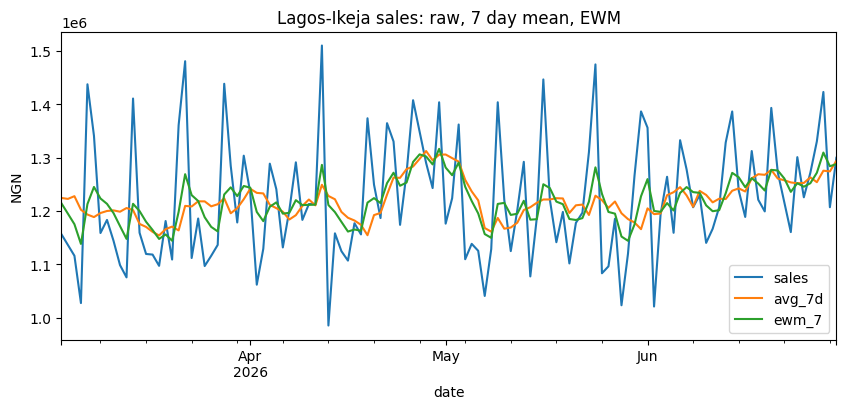

In [407]:
w["cumsum"] = w["sales"].cumsum()                                        # running total (same as expanding().sum())
w["cummax"] = w["sales"].cummax()                                        # running maximum
w["cummin"] = w["sales"].cummin()                                        # running minimum
w["growth_index"] = (1 + w["sales"].pct_change().fillna(0)).cumprod()    # compounded daily growth starting at 1.0
print(w[["sales", "cumsum", "cummax", "cummin"]].head(4).round(0))       # first rows
print(round(w["growth_index"].iloc[-1], 3))                              # compounded multiplier over the whole period

ax = w[["sales", "avg_7d", "ewm_7"]].tail(120).plot(figsize=(10, 4), title="Lagos-Ikeja sales: raw, 7 day mean, EWM")   # pandas plots straight from a DataFrame
ax.set_ylabel("NGN")                                                     # label the vertical axis

### Your turn (Section 20)
1. Compute a **14-day rolling average** for the Abuja-Wuse store and find the date when it peaked.
2. Create the **month-to-date cumulative sales** for Lagos (hint: `groupby` year and month, then `cumsum`).
3. Which is smoother, a 7-day rolling mean or `ewm(span=7)`? Justify with the `diff().abs().mean()` test.

---
# SECTION 21: Categorical Data and Memory Optimisation

### 21.1 Why use the category dtype

A text column with few distinct values (department, region, status) wastes memory because pandas stores a full string for every row. The `category` dtype stores each **unique value once** and keeps a small integer code per row, like a database lookup table.

### 21.2 Converting to category and measuring the savings

In [408]:
orders_raw = pd.read_csv(f"{DATA}/orders.csv")                           # reload the raw orders (text columns are plain str)
print(orders_raw.shape)                                                  # about 3,200 rows

for col in ["product_category", "region", "payment_method", "product"]: # the columns with repeating text
    before = orders_raw[col].memory_usage(deep=True)                     # bytes used as text
    after = orders_raw[col].astype("category").memory_usage(deep=True)   # bytes used as category
    print(f"{col:18s} {before:>9,} -> {after:>8,} bytes  ({1 - after / before:.0%} saved, {orders_raw[col].nunique()} unique)")   # compare

cat = orders_raw["product_category"].astype("category")                  # keep one categorical Series for the next lines
print(cat.cat.categories.tolist())                                       # the unique values stored once
print(cat.cat.codes.head(5).tolist())                                    # the integer code stored per row
print(cat.value_counts())                                                # value_counts works as usual

(3206, 10)
product_category     184,938 ->    3,856 bytes  (98% saved, 6 unique)
region               178,441 ->    5,240 bytes  (97% saved, 24 unique)
payment_method       182,590 ->    3,738 bytes  (98% saved, 4 unique)
product              189,819 ->    5,313 bytes  (97% saved, 24 unique)
['Beauty', 'Books', 'Electronics', 'Fashion', 'Groceries', 'Home & Kitchen']
[5, 5, 4, 3, 0]
product_category
Groceries         560
Books             544
Fashion           540
Home & Kitchen    535
Beauty            523
Electronics       504
Name: count, dtype: int64


### 21.3 Ordered categories

A plain text column sorts **alphabetically**. An ordered category sorts and compares by the **meaning** you define.

In [409]:
print(sorted(["Small", "Medium", "Large"]))                              # alphabetical order is wrong: Large, Medium, Small

sizes = pd.CategoricalDtype(categories=["Small", "Medium", "Large"], ordered=True)   # define the logical order
emp["t_shirt_size"] = emp["t_shirt_size"].astype(sizes)                  # apply the ordered type to the column

print(emp["t_shirt_size"].dtype)                                         # category with an order
print((emp["t_shirt_size"] > "Small").sum(), "employees wear Medium or Large")   # comparison operators now follow the defined order
print(emp.sort_values("t_shirt_size")["t_shirt_size"].head(3).tolist())  # sorted Small, then Medium, then Large
print(emp.groupby("t_shirt_size", observed=True)["salary"].mean().round(0))   # groups appear in the logical order, not alphabetical
print(emp["t_shirt_size"].min(), emp["t_shirt_size"].max())              # min and max respect the order too

['Large', 'Medium', 'Small']
category
414 employees wear Medium or Large
['Small', 'Small', 'Small']
t_shirt_size
Small    107,925.00
Medium   107,089.00
Large    107,381.00
Name: salary, dtype: float64
Small Large


In [410]:
rating = pd.Series(["Good", "Poor", "Good"], dtype="category")           # a small categorical Series
rating = rating.cat.add_categories(["Excellent"])                        # add a category that does not occur yet
print(rating.value_counts())                                             # unused categories are shown with a count of 0
rating = rating.cat.remove_unused_categories()                           # drop categories with no rows
rating = rating.cat.reorder_categories(["Poor", "Good"], ordered=True)   # set a new order explicitly
print(rating.cat.categories.tolist(), rating.cat.ordered)                # ['Poor', 'Good'] and True
print(rating.cat.rename_categories({"Poor": "P", "Good": "G"}).tolist()) # rename the labels without touching the data

Good         2
Poor         1
Excellent    0
Name: count, dtype: int64
['Poor', 'Good'] True
['G', 'P', 'G']


### 21.4 Other memory-saving techniques in one reusable function

In [411]:
def reduce_memory(frame, category_threshold=0.5, verbose=True):          # shrink a DataFrame automatically
    start = frame.memory_usage(deep=True).sum() / 1024                   # memory before, in KB
    frame = frame.copy()                                                 # never change the caller's DataFrame
    for col in frame.columns:                                            # inspect each column in turn
        series = frame[col]                                              # the column as a Series
        if pd.api.types.is_integer_dtype(series):                        # integer columns
            frame[col] = pd.to_numeric(series, downcast="integer")       # smallest integer type that fits
        elif pd.api.types.is_float_dtype(series):                        # float columns
            frame[col] = pd.to_numeric(series, downcast="float")         # float32 where possible
        elif pd.api.types.is_string_dtype(series) or series.dtype == object:   # text columns
            if series.nunique() / max(len(series), 1) < category_threshold:    # few distinct values relative to rows
                frame[col] = series.astype("category")                   # category is far cheaper
    end = frame.memory_usage(deep=True).sum() / 1024                     # memory after, in KB
    if verbose:                                                          # optional report
        print(f"memory: {start:,.0f} KB -> {end:,.0f} KB ({1 - end / start:.0%} smaller)")   # the saving
    return frame                                                         # return the optimised copy

orders_small = reduce_memory(orders_raw)                                 # apply the function to the raw orders
print(orders_small.dtypes.value_counts())                                # a mix of int8, float32 and category now

memory: 1,480 KB -> 426 KB (71% smaller)
object      1
category    1
category    1
category    1
category    1
category    1
int8        1
category    1
category    1
float32     1
Name: count, dtype: int64


In [412]:
only_needed = pd.read_csv(f"{DATA}/orders.csv", usecols=["order_id", "product_category", "quantity"],   # load only three columns
                          dtype={"product_category": "category", "quantity": "int8"})                  # and use compact dtypes from the start
print(only_needed.memory_usage(deep=True).sum() / 1024, "KB when loaded smartly")   # far less than the full file
print(only_needed.dtypes.to_dict())                                      # the compact dtypes were applied at read time

arrow_backed = pd.read_csv(f"{DATA}/orders.csv", dtype_backend="pyarrow")   # Arrow-backed dtypes: another memory efficient option
print(arrow_backed.dtypes.head(4).to_dict())                             # for example string[pyarrow] and int64[pyarrow]
only_needed.info(memory_usage="deep")                                  # df.info(memory_usage="deep") is the habit to keep

191.6171875 KB when loaded smartly
{'order_id': dtype('O'), 'product_category': CategoricalDtype(categories=['Beauty', 'Books', 'Electronics', 'Fashion', 'Groceries', 'Home & Kitchen'], ordered=False, categories_dtype=object), 'quantity': dtype('int8')}
{'order_id': string[pyarrow], 'order_date': string[pyarrow], 'customer_id': string[pyarrow], 'product_category': string[pyarrow]}
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3206 entries, 0 to 3205
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   order_id          3206 non-null   object  
 1   product_category  3206 non-null   category
 2   quantity          3206 non-null   int8    
dtypes: category(1), int8(1), object(1)
memory usage: 191.6 KB


### Your turn (Section 21)
1. Convert `city` and `status` in `emp` to category and measure the memory saved.
2. Create an ordered category for `salary_band` (`Entry` < `Standard` < `High`) and compute the average age for each band **in that order**.
3. Apply `reduce_memory` to `transactions_large.csv` (read with `nrows=100_000`) and report the saving.

---
# SECTION 22: Exporting Data

### 22.1 Writing to CSV

In [413]:
export_cols = ["employee_id", "name", "department", "city", "salary", "salary_band", "hire_date"]   # the columns to share
emp.to_csv(f"{OUT_DIR}/cleaned_employees.csv", index=False)                          # index=False stops the row numbers becoming a column
emp.to_csv(f"{OUT_DIR}/employees_short.csv", index=False, columns=export_cols)       # export only the listed columns, in this order
emp.to_csv(f"{OUT_DIR}/employees_dates.csv.gz", index=False, columns=export_cols, date_format="%d/%m/%Y", float_format="%.0f", compression="gzip")   # date style, rounding and compression

print(pd.read_csv(f"{OUT_DIR}/employees_short.csv", nrows=2))                        # read back to check the file
print(pd.read_csv(f"{OUT_DIR}/employees_dates.csv.gz", nrows=2))                     # pandas decompresses gzip automatically
print({f: f"{os.path.getsize(os.path.join(OUT_DIR, f)) / 1024:,.0f} KB" for f in os.listdir(OUT_DIR) if f.startswith("employees") or f.startswith("cleaned")})   # compare file sizes

   employee_id           name department   city     salary salary_band   hire_date
0            1     Emeka Igwe  Marketing  Lagos  96,600.00        High  2014-10-29
1            2  Amaka Ibrahim    Finance   Kano 137,100.00        High  2025-07-15
   employee_id           name department   city  salary salary_band   hire_date
0            1     Emeka Igwe  Marketing  Lagos   96600        High  29/10/2014
1            2  Amaka Ibrahim    Finance   Kano  137100        High  15/07/2025
{'cleaned_employees.csv': '258 KB', 'employees.json': '1 KB', 'employees.parquet': '115 KB', 'employees_dates.csv.gz': '9 KB', 'employees_report.xlsx': '8 KB', 'employees_short.csv': '36 KB'}


### 22.2 Writing to Excel

In [414]:
emp[export_cols].head(50).to_excel(f"{OUT_DIR}/employees_report.xlsx", sheet_name="Employees", index=False)   # a single sheet

dept_stats = emp.groupby("department").agg(headcount=("employee_id", "count"), avg_salary=("salary", "mean")).round(0).reset_index()   # summary table
city_stats = emp.groupby("city").agg(headcount=("employee_id", "count"), avg_salary=("salary", "mean")).round(0).reset_index()         # another summary

with pd.ExcelWriter(f"{OUT_DIR}/hr_workbook.xlsx", engine="openpyxl") as writer:                        # open ONE workbook for several sheets
    emp[export_cols].to_excel(writer, sheet_name="Employees", index=False)           # sheet 1: the detail
    dept_stats.to_excel(writer, sheet_name="By Department", index=False)             # sheet 2: department summary
    city_stats.to_excel(writer, sheet_name="By City", index=False, startrow=2)       # sheet 3: leave two blank rows for a title
    writer.sheets["By City"].cell(row=1, column=1, value="Headcount and average salary by city (NGN)")   # write a title into the free cell A1
    writer.sheets["Employees"].freeze_panes = "A2"                                   # freeze the header row so it stays visible

print(pd.ExcelFile(f"{OUT_DIR}/hr_workbook.xlsx").sheet_names)                       # confirm the three sheets exist

['Employees', 'By Department', 'By City']


### 22.3 Writing to JSON, Parquet and SQL

In [415]:
emp[export_cols].head(3).to_json(f"{OUT_DIR}/employees.json", orient="records", indent=2, date_format="iso")   # list of row objects with ISO dates
print(open(f"{OUT_DIR}/employees.json").read()[:230])                                # peek at the file

for orient in ["records", "columns", "index", "split"]:                              # the JSON shapes pandas supports
    text = emp[["name", "city"]].head(2).to_json(orient=orient)                      # same data, different layout
    print(f"{orient:8s}", text[:95])                                                 # compare the layouts

emp.to_parquet(f"{OUT_DIR}/employees.parquet", engine="pyarrow", index=False)        # compressed, typed, columnar storage
print(pd.read_parquet(f"{OUT_DIR}/employees.parquet").dtypes.head(4).to_dict())      # dtypes survive the trip

[
  {
    "employee_id":"00001",
    "name":"Emeka Igwe",
    "department":"Marketing",
    "city":"Lagos",
    "salary":96600.0,
    "salary_band":"High",
    "hire_date":"2014-10-29T00:00:00.000"
  },
  {
    "employee_id":"0000
records  [{"name":"Emeka Igwe","city":"Lagos"},{"name":"Amaka Ibrahim","city":"Kano"}]
columns  {"name":{"0":"Emeka Igwe","1":"Amaka Ibrahim"},"city":{"0":"Lagos","1":"Kano"}}
index    {"0":{"name":"Emeka Igwe","city":"Lagos"},"1":{"name":"Amaka Ibrahim","city":"Kano"}}
split    {"columns":["name","city"],"index":[0,1],"data":[["Emeka Igwe","Lagos"],["Amaka Ibrahim","Kano"
{'employee_id': dtype('O'), 'name': dtype('O'), 'department': dtype('O'), 'salary': dtype('float64')}


In [416]:
from sqlalchemy import create_engine                                                 # reuse the SQLAlchemy engine builder

out_engine = create_engine(f"sqlite:///{OUT_DIR}/analysis.db")                       # a NEW SQLite database for our results
emp[export_cols].to_sql("employees", con=out_engine, if_exists="replace", index=False)   # create (or recreate) the table
emp[export_cols].head(5).to_sql("employees", con=out_engine, if_exists="append", index=False)   # append five more rows to the same table
dept_stats.to_sql("dept_stats", con=out_engine, if_exists="replace", index=False)    # a second table

print(pd.read_sql("SELECT COUNT(*) AS n FROM employees", con=out_engine))            # 600 + 5 rows now
print(pd.read_sql("SELECT department, AVG(salary) AS avg_salary FROM employees GROUP BY department ORDER BY avg_salary DESC LIMIT 3", con=out_engine))   # query our own table

     n
0  605
    department  avg_salary
0  Engineering  144,344.59
1      Finance  122,822.73
2   Unassigned  111,194.44


### 22.4 Round-tripping data types

CSV is plain text, so types are lost. Parquet keeps them exactly. Watch what happens:

In [417]:
sample = emp[["employee_id", "hire_date", "department_cat", "is_manager", "salary"]].head(3)   # five columns with five different types
sample.to_csv(f"{OUT_DIR}/rt.csv", index=False)                                      # save as CSV
sample.to_parquet(f"{OUT_DIR}/rt.parquet", index=False)                              # save as Parquet

print(pd.DataFrame({"original": sample.dtypes.astype(str),                           # compare the three versions side by side
                    "from CSV": pd.read_csv(f"{OUT_DIR}/rt.csv").dtypes.astype(str),
                    "from Parquet": pd.read_parquet(f"{OUT_DIR}/rt.parquet").dtypes.astype(str)}))
print(pd.read_csv(f"{OUT_DIR}/rt.csv")["employee_id"].tolist())                      # the leading zeros are gone after the CSV round trip

                      original from CSV    from Parquet
employee_id             object    int64          object
hire_date       datetime64[ns]   object  datetime64[ns]
department_cat        category   object        category
is_manager                bool     bool            bool
salary                 float64  float64         float64
[1, 2, 3]


### Your turn (Section 22)
1. Export the pivot table from Section 17 to a sheet called `Pivot` and the long table to a sheet called `Long` in the same workbook.
2. Save `orders.csv` (after reading) to Parquet and compare the file sizes and read times of both formats.
3. Write the `by_store_month` table from Section 19 to SQLite and run a SQL query that returns the best month for each store.

---
# SECTION 23: Performance Tips and Best Practices

### 23.1 The golden rule: vectorise

In [418]:
test = pd.DataFrame({"price": np.random.default_rng(5).integers(1000, 90000, 20_000),     # 20,000 prices
                     "quantity": np.random.default_rng(6).integers(1, 9, 20_000)})        # and quantities

t0 = time.perf_counter()                                                 # start the clock
results = []                                                             # slow approach: python loop with iloc
for i in range(len(test)):                                               # visit every row by position
    results.append(test["price"].iloc[i] * test["quantity"].iloc[i])     # one tiny multiplication per iteration
test["revenue_loop"] = results                                           # store the results
t_loop = time.perf_counter() - t0                                        # time taken

t0 = time.perf_counter()                                                 # restart the clock
test["revenue_vec"] = test["price"] * test["quantity"]                   # fast approach: one vectorised operation
t_vec = time.perf_counter() - t0                                         # time taken

print(f"loop: {t_loop:.3f}s | vectorised: {t_vec * 1000:.2f} ms | speed-up: {t_loop / t_vec:,.0f}x")   # the difference is dramatic
print((test["revenue_loop"] == test["revenue_vec"]).all())               # identical answers

loop: 5.318s | vectorised: 1.78 ms | speed-up: 2,987x
True


### 23.2 Never grow a DataFrame row by row

In [419]:
records = [{"id": i, "value": i * 2} for i in range(1500)]               # 1,500 small records, as if arriving from an API

t0 = time.perf_counter()                                                 # slow way
slow = pd.DataFrame()                                                    # an empty DataFrame to grow
for record in records:                                                   # loop over the records
    slow = pd.concat([slow, pd.DataFrame([record])], ignore_index=True)  # every iteration COPIES the entire growing table
t_slow = time.perf_counter() - t0                                        # time taken

t0 = time.perf_counter()                                                 # fast way
fast = pd.DataFrame(records)                                             # build the DataFrame once from the list
t_fast = time.perf_counter() - t0                                        # time taken

print(f"concat in loop: {t_slow:.3f}s | build once: {t_fast * 1000:.2f} ms | {t_slow / t_fast:,.0f}x faster")   # compare
print(slow.equals(fast))                                                 # same final table

concat in loop: 4.787s | build once: 38.34 ms | 125x faster
True


### 23.3 Use efficient data types

In [420]:
df_types = pd.DataFrame({                                                # compare classic and modern nullable dtypes
    "classic_int": pd.Series([1, 2, None, 4]),                           # becomes float64 because NaN forces it
    "nullable_int": pd.Series([1, 2, None, 4], dtype="Int64"),           # stays integer and supports <NA>
    "nullable_float": pd.Series([1.5, None, 3.5, 4.0], dtype="Float64"), # nullable float
    "nullable_bool": pd.Series([True, None, False, True], dtype="boolean"),   # three-valued logic: True, False, <NA>
    "text": pd.Series(["a", None, "c", "d"], dtype="string"),            # dedicated string dtype
})
print(df_types.dtypes)                                                   # see the dtypes
print(df_types["nullable_int"].sum(), "| mean:", df_types["nullable_float"].mean())   # missing values are skipped automatically
print(df_types.convert_dtypes().dtypes.to_dict())                        # convert_dtypes() picks the best nullable dtype automatically

classic_int              float64
nullable_int               Int64
nullable_float           Float64
nullable_bool            boolean
text              string[python]
dtype: object
7 | mean: 3.0
{'classic_int': Int64Dtype(), 'nullable_int': Int64Dtype(), 'nullable_float': Float64Dtype(), 'nullable_bool': BooleanDtype, 'text': string[python]}


### 23.4 Filter early, filter often, and choose the right file format

We now use the 150,000-row transaction file to measure real differences.

In [421]:
t0 = time.perf_counter(); tx_csv = pd.read_csv(f"{DATA}/transactions_large.csv", parse_dates=["timestamp"]); t_csv = time.perf_counter() - t0   # read the CSV
t0 = time.perf_counter(); tx_pq = pd.read_parquet(f"{DATA}/transactions.parquet"); t_pq = time.perf_counter() - t0                              # read the Parquet
t0 = time.perf_counter(); tx_cols = pd.read_parquet(f"{DATA}/transactions.parquet", columns=["store", "amount"]); t_cols = time.perf_counter() - t0   # only two columns
t0 = time.perf_counter(); tx_filtered = pd.read_parquet(f"{DATA}/transactions.parquet", filters=[("status", "==", "success")]); t_filt = time.perf_counter() - t0   # filter at read

print(f"CSV                : {t_csv:.3f}s")                              # slowest
print(f"Parquet            : {t_pq:.3f}s")                               # faster, and typed
print(f"Parquet, 2 columns : {t_cols:.3f}s")                             # column pruning
print(f"Parquet, filtered  : {t_filt:.3f}s  ({len(tx_filtered):,} rows)")   # predicate pushdown
print(f"memory CSV {tx_csv.memory_usage(deep=True).sum() / 1e6:.1f} MB vs Parquet {tx_pq.memory_usage(deep=True).sum() / 1e6:.1f} MB")   # dtypes matter

CSV                : 6.686s
Parquet            : 0.218s
Parquet, 2 columns : 0.071s
Parquet, filtered  : 0.115s  (139,431 rows)
memory CSV 37.1 MB vs Parquet 11.3 MB


In [422]:
t0 = time.perf_counter()                                                 # approach A: group first, filter afterwards
a = tx_csv.groupby(["store", "channel"])["amount"].mean()                # aggregate all 150,000 rows
a = a.loc[a.index.get_level_values("store") == "Lagos-Ikeja"]            # then throw most of it away
t_a = time.perf_counter() - t0                                           # time for approach A

t0 = time.perf_counter()                                                 # approach B: filter first, group afterwards
b = tx_csv[tx_csv["store"] == "Lagos-Ikeja"].groupby("channel")["amount"].mean()   # aggregate only the needed rows
t_b = time.perf_counter() - t0                                           # time for approach B

print(f"group then filter: {t_a * 1000:.1f} ms | filter then group: {t_b * 1000:.1f} ms")   # B does less work
print(np.allclose(a.values, b.values))                                   # identical results

grp_text = tx_csv.assign(store=tx_csv["store"].astype(str))              # text keys
grp_cat = tx_csv.assign(store=tx_csv["store"].astype("category"))        # category keys
t0 = time.perf_counter(); grp_text.groupby("store")["amount"].sum(); t_text = time.perf_counter() - t0   # groupby on text
t0 = time.perf_counter(); grp_cat.groupby("store", observed=True)["amount"].sum(); t_cat = time.perf_counter() - t0   # groupby on category
print(f"groupby text: {t_text * 1000:.1f} ms | groupby category: {t_cat * 1000:.1f} ms")   # category is usually faster

group then filter: 156.5 ms | filter then group: 87.6 ms
True
groupby text: 48.6 ms | groupby category: 35.3 ms


### 23.5 Profiling and timing

In [423]:
%timeit tx_csv["amount"] * 1.1

2.42 ms ± 736 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [424]:
start = time.time()                                                      # plain python stopwatch: works everywhere, not only in notebooks
result = tx_csv.groupby("store")["amount"].mean()                        # the operation we want to time
print(f"Elapsed: {time.time() - start:.4f} seconds")                     # how long it took

mask_bool = (tx_csv["amount"] > 20000) & (tx_csv["status"] == "success") # classic boolean mask
mask_query = tx_csv.query("amount > 20000 and status == 'success'")      # query() is sometimes faster on large frames
print(mask_bool.sum() == len(mask_query))                                # same rows selected
print(tx_csv.eval("amount * 1.075").head(2).round(2).tolist())           # eval() evaluates an expression string efficiently
print(tx_csv.memory_usage(deep=True).round(0).head(4).to_dict())        # memory per column helps decide what to optimise

Elapsed: 0.0343 seconds
True
[11186.06, 48100.91]
{'Index': 132, 'txn_id': 1200000, 'timestamp': 1200000, 'channel': 8075647}


**Performance checklist**

1. Vectorise. Avoid Python loops, `iterrows` and row-wise `apply`.
2. Load only the columns and rows you need (`usecols`, `nrows`, `chunksize`, Parquet `columns` and `filters`).
3. Use compact dtypes (`category`, downcasted numbers, nullable types).
4. Filter **before** expensive operations (`groupby`, `merge`, `apply`).
5. Build DataFrames once from lists, never by repeated `concat` in a loop.
6. Prefer Parquet to CSV for intermediate files.
7. Measure before optimising: `%timeit`, `time.perf_counter`, `memory_usage(deep=True)`.

### Your turn (Section 23)
1. Time `iterrows` against a vectorised formula on 10,000 rows of `orders` and report the speed-up.
2. Use `read_csv` with `chunksize` to compute the **total successful amount per store** over `transactions_large.csv` without ever holding the whole file.
3. Find which column of `tx_csv` uses the most memory, and shrink it.

---
# SECTION 24: Full Worked Example (End-to-End)

One continuous scenario: **clean, transform and summarise the retail orders dataset** of *Prodigy Mart*, an online store selling across six Nigerian cities. Every technique from Sections 5 to 23 appears again here, in the order you would use it on the job.

### 24.1 Step 1: Imports and load

In [425]:
orders = pd.read_csv(                                                    # read the raw orders
    f"{DATA}/orders.csv",                                                # path
    parse_dates=["order_date"],                                          # order_date is clean text, so parse it while reading
    na_values=["NA", "N/A", "null", "unknown"],                          # text placeholders in unit_price become real NaN
)
print(orders.shape)                                                      # rows and columns
orders.head()                                                            # first five rows

(3206, 10)


,order_id,order_date,customer_id,product_category,product,unit_price,quantity,region,payment_method,discount_pct
0,ORD-000001,2026-06-14,C0327,Home & Kitchen,Gas Cooker,"115,600.00",5,Ibadan,Transfer,0.00
1,ORD-000001,2026-06-14,C0327,Home & Kitchen,Standing Fan,"45,700.00",1,Ibadan,Transfer,0.00
2,ORD-000002,2026-02-10,C0567,Groceries,Vegetable Oil 25L,"55,300.00",1,Lagos,Transfer,10.00
3,ORD-000003,2025-06-21,C0060,Fashion,Agbada Set,"93,000.00",1,Lagos,Card,5.00
4,ORD-000004,2025-07-02,C0677,Beauty,Hair Dryer,"18,100.00",4,enugu,Card,10.00


### 24.2 Step 2: Structural check (a data-quality snapshot)

In [426]:
orders.info()                                                            # dtypes and non-null counts
print(orders.isnull().sum().sort_values(ascending=False))                # which columns have missing data, worst first
print("duplicate rows:", orders.duplicated().sum())                      # fully duplicated rows
print(orders["region"].value_counts().head(12))                          # messy spellings are visible here (lagos, LAGOS, ' Lagos ')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3206 entries, 0 to 3205
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          3206 non-null   object        
 1   order_date        3200 non-null   datetime64[ns]
 2   customer_id       3181 non-null   object        
 3   product_category  3206 non-null   object        
 4   product           3206 non-null   object        
 5   unit_price        3115 non-null   float64       
 6   quantity          3206 non-null   int64         
 7   region            3206 non-null   object        
 8   payment_method    3206 non-null   object        
 9   discount_pct      3206 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(6)
memory usage: 250.6+ KB
unit_price          91
customer_id         25
order_date           6
order_id             0
product_category     0
product              0
quantity             0
r

### 24.3 Step 3: Cleaning

In [427]:
n0 = len(orders)                                                         # remember the starting row count
orders = orders.drop_duplicates()                                        # remove duplicates FIRST so they cannot inflate later sums
print("after duplicates:", n0, "->", len(orders))                        # rows removed

orders["unit_price"] = pd.to_numeric(orders["unit_price"], errors="coerce")   # make sure the price is numeric
price_before = orders["unit_price"].isna().sum()                         # missing prices before imputation
orders["unit_price"] = orders["unit_price"].fillna(orders.groupby("product")["unit_price"].transform("median"))   # a product always has a similar price: use its own median
orders["unit_price"] = orders["unit_price"].fillna(orders.groupby("product_category")["unit_price"].transform("median"))   # fallback: category median
print("missing prices:", price_before, "->", orders["unit_price"].isna().sum())   # all repaired

n1 = len(orders)                                                         # row count before dropping rows with no identifier
orders = orders.dropna(subset=["order_date", "customer_id"])             # rows missing a critical identifier cannot be analysed per customer
print("after dropping missing ids:", n1, "->", len(orders))              # rows removed

orders["region"] = orders["region"].str.strip().str.title()              # standardise region text
orders["product_category"] = orders["product_category"].astype("category")   # memory efficient category dtype
orders["payment_method"] = orders["payment_method"].astype("category")   # another low-cardinality column
orders = orders.reset_index(drop=True)                                   # tidy continuous index after dropping rows
print(orders["region"].value_counts())                                   # six clean regions

after duplicates: 3206 -> 3166
missing prices: 90 -> 0
after dropping missing ids: 3166 -> 3135
region
Ibadan           553
Port Harcourt    543
Kano             534
Enugu            533
Abuja            487
Lagos            485
Name: count, dtype: int64


### 24.4 Step 4: Feature engineering

In [428]:
orders["gross_revenue"] = orders["unit_price"] * orders["quantity"]      # revenue before discount: fully vectorised
orders["discount_amount"] = orders["gross_revenue"] * orders["discount_pct"] / 100   # money given away as discount
orders["net_revenue"] = orders["gross_revenue"] - orders["discount_amount"]          # revenue after discount
orders["order_month"] = orders["order_date"].dt.to_period("M")           # a month period such as 2026-03 for monthly aggregation
orders["order_quarter"] = orders["order_date"].dt.to_period("Q")         # a quarter period such as 2026Q1
orders["weekday"] = orders["order_date"].dt.day_name()                   # weekday name
orders["is_weekend"] = orders["order_date"].dt.dayofweek >= 5            # True for Saturday and Sunday
print(orders[["order_id", "unit_price", "quantity", "net_revenue", "order_month", "weekday", "is_weekend"]].head())   # preview

     order_id  unit_price  quantity  net_revenue order_month    weekday  is_weekend
0  ORD-000001  115,600.00         5   578,000.00     2026-06     Sunday        True
1  ORD-000001   45,700.00         1    45,700.00     2026-06     Sunday        True
2  ORD-000002   55,300.00         1    49,770.00     2026-02    Tuesday       False
3  ORD-000003   93,000.00         1    88,350.00     2025-06   Saturday        True
4  ORD-000004   18,100.00         4    65,160.00     2025-07  Wednesday       False


### 24.5 Step 5: GroupBy summary

In [429]:
monthly_summary = orders.groupby("order_month").agg(                     # named aggregation
    total_revenue=("net_revenue", "sum"),                                # revenue per month
    orders=("order_id", "nunique"),                                      # distinct orders (an order can have several lines)
    lines=("order_id", "size"),                                          # order lines
    units=("quantity", "sum"),                                           # items sold
    avg_line_value=("net_revenue", "mean"),                              # average value of an order LINE (what the guide calls avg order value)
)
order_totals = orders.groupby(["order_month", "order_id"])["net_revenue"].sum().groupby("order_month").mean()   # true average value per ORDER
monthly_summary["avg_order_value"] = order_totals                        # add the true average order value
monthly_summary["mom_growth_pct"] = monthly_summary["total_revenue"].pct_change() * 100   # month over month growth
display(monthly_summary.round(1))                                        # the monthly summary table

,total_revenue,orders,lines,units,avg_line_value,avg_order_value,mom_growth_pct
order_month,,,,,,,
2025-01,"53,036,565.00",130,184,832,"288,242.20","407,973.60",NaN
2025-02,"71,592,770.00",108,158,919,"453,118.80","662,896.00",35.00
2025-03,"61,352,960.00",144,192,919,"319,546.70","426,062.20",-14.30
2025-04,"58,982,770.00",118,156,749,"378,094.70","499,854.00",-3.90
2025-05,"56,317,355.00",117,154,815,"365,697.10","481,344.90",-4.50
2025-06,"70,664,160.00",111,151,863,"467,974.60","636,614.10",25.50
2025-07,"77,718,735.00",153,208,974,"373,647.80","507,965.60",10.00
2025-08,"60,675,710.00",118,177,896,"342,800.60","514,200.90",-21.90
2025-09,"68,333,355.00",134,177,821,"386,064.20","509,950.40",12.60


### 24.6 Step 6: Merge in customer data

In [430]:
customers = pd.read_csv(f"{DATA}/customers.csv", parse_dates=["signup_date"])   # customer reference table
print(customers["customer_id"].is_unique)                                # the key must be unique on the right side

n_before = len(orders)                                                   # rows before the merge
orders = pd.merge(orders, customers[["customer_id", "signup_date", "segment", "city"]].rename(columns={"city": "customer_city"}),   # rename to avoid clashing names
                  on="customer_id", how="left", validate="many_to_one")  # many orders map to one customer; validate proves it
assert len(orders) == n_before, "Merge changed the row count unexpectedly"   # the safety check from Section 25
print(n_before, "->", len(orders), "| orders without a customer record:", orders["segment"].isna().sum())   # sanity checks
print(orders[["order_id", "customer_id", "segment", "customer_city"]].head(3))   # preview the new columns

True
3135 -> 3135 | orders without a customer record: 0
     order_id customer_id segment  customer_city
0  ORD-000001       C0327  Retail  Port Harcourt
1  ORD-000001       C0327  Retail  Port Harcourt
2  ORD-000002       C0567  Retail          Enugu


### 24.7 Step 7: Reshape for reporting

In [431]:
pivot = pd.pivot_table(                                                  # a region by category revenue grid
    orders,                                                              # source
    values="net_revenue",                                                # what to add up
    index="region",                                                      # rows
    columns="product_category",                                          # columns
    aggfunc="sum",                                                       # add the revenue
    fill_value=0,                                                        # no empty cells
    margins=True,                                                        # totals
    observed=True,                                                       # only categories that occur
)
display((pivot / 1e6).round(1))                                          # shown in millions of Naira for readability

product_category,Beauty,Books,Electronics,Fashion,Groceries,Home & Kitchen,All
region,,,,,,,
Abuja,4.40,5.40,72.00,18.60,21.00,30.40,151.90
Enugu,6.20,3.40,88.70,14.50,22.30,42.30,177.40
Ibadan,7.00,4.50,76.10,18.80,22.80,35.70,164.90
Kano,6.20,4.40,76.00,20.20,22.10,36.80,165.70
Lagos,4.50,4.20,103.80,15.90,18.70,40.40,187.40
Port Harcourt,7.20,3.60,119.70,21.80,22.80,34.60,209.60
All,35.50,25.40,536.20,109.80,129.70,220.30,"1,056.90"


### 24.8 Step 8: Save the results

In [432]:
orders.to_parquet(f"{OUT_DIR}/orders_cleaned.parquet", index=False)      # full cleaned data, with exact dtypes preserved
monthly_summary.to_csv(f"{OUT_DIR}/monthly_summary.csv")                 # the summary (index kept: the month matters)
pivot.to_excel(f"{OUT_DIR}/region_category_pivot.xlsx")                  # the pivot for non-technical colleagues

for f in ["orders_cleaned.parquet", "monthly_summary.csv", "region_category_pivot.xlsx"]:   # confirm all three files exist
    print(f"{f:32s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1024:8.1f} KB")           # name and size

orders_cleaned.parquet              109.9 KB
monthly_summary.csv                   1.6 KB
region_category_pivot.xlsx            5.9 KB


---
# SECTION 25: Common Pitfalls and How to Avoid Them

Each pitfall below is **demonstrated live**, followed by the fix.

### 25.1 Chained assignment

In [433]:
df = emp[["name", "salary"]].copy()                                      # a small independent DataFrame

with warnings.catch_warnings(record=True) as caught:                     # record any warning instead of printing it
    warnings.simplefilter("always")                                      # make sure warnings are not suppressed
    df[df["salary"] > 100000]["salary"] = 1                              # WRONG: chained indexing creates a temporary copy
print("warning raised :", [w.category.__name__ for w in caught])         # pandas warns that the assignment cannot work
print("rows changed   :", (df["salary"] == 1).sum())                     # 0: the original was NOT modified

df.loc[df["salary"] > 100000, "salary"] = 1                              # RIGHT: a single loc call selects and assigns together
print("rows changed   :", (df["salary"] == 1).sum())                     # now the change is real

warning raised : ['SettingWithCopyWarning']
rows changed   : 0
rows changed   : 329


### 25.2 Forgetting `errors="coerce"`

In [434]:
messy = pd.Series(["100", "250", "confidential", "40"])                  # a column with one text value
try:                                                                     # attempt a strict conversion
    pd.to_numeric(messy)                                                 # stops at the first bad value
except ValueError as error:                                              # pandas raises an error
    print("ValueError:", error)                                          # the message names the offending text
print(pd.to_numeric(messy, errors="coerce").tolist())                    # coerce turns the bad value into NaN so the rest survives

ValueError: Unable to parse string "confidential" at position 2
[100.0, 250.0, nan, 40.0]


### 25.3 `loc` includes the endpoint; `iloc` does not

In [435]:
small = pd.DataFrame({"v": [10, 20, 30, 40, 50]})                        # five rows labelled 0 to 4
print(len(small.loc[1:3]), small.loc[1:3]["v"].tolist())                 # loc is inclusive: rows 1, 2, 3 (three rows)
print(len(small.iloc[1:3]), small.iloc[1:3]["v"].tolist())               # iloc excludes the end: rows 1, 2 (two rows)

shifted = small.copy()                                                   # when labels are not 0..n-1 the difference grows
shifted.index = [10, 20, 30, 40, 50]                                     # custom integer labels
print(shifted.loc[10:30]["v"].tolist(), shifted.iloc[10:30]["v"].tolist())   # loc uses LABELS; iloc beyond the length returns nothing

3 [20, 30, 40]
2 [20, 30]
[10, 20, 30] []


### 25.4 Misaligned Series produce NaN silently

In [436]:
a = pd.Series([1, 2, 3], index=["x", "y", "z"])                          # first Series
b = pd.Series([10, 20, 30], index=["y", "z", "w"])                       # second Series with partly different labels
print((a + b).to_dict())                                                 # only y and z overlap: x and w become NaN
print(a.add(b, fill_value=0).to_dict())                                  # fill_value treats a missing side as 0
print((a.reset_index(drop=True) + b.reset_index(drop=True)).tolist())    # or align by POSITION by dropping the labels

try:                                                                     # comparing misaligned Series is even stricter
    a == b                                                               # compares labels first
except ValueError as error:                                              # pandas refuses
    print("ValueError:", error)                                          # 'Can only compare identically-labeled Series objects'

{'w': nan, 'x': nan, 'y': 12.0, 'z': 23.0}
{'w': 30.0, 'x': 1.0, 'y': 12.0, 'z': 23.0}
[11, 22, 33]
ValueError: Can only compare identically-labeled Series objects


### 25.5 Do not assume row order after `groupby`

In [437]:
tmp = pd.DataFrame({"g": ["b", "a", "b", "a"], "v": [1, 2, 3, 4]})       # unsorted group keys
print(tmp.groupby("g")["v"].sum().index.tolist())                        # sorted by key: ['a', 'b'], not the original order
print(tmp.groupby("g", sort=False)["v"].sum().index.tolist())            # sort=False keeps first-appearance order: ['b', 'a']
print(tmp.groupby("g")["v"].transform("sum").tolist())                   # transform keeps the ORIGINAL row order, so it is safe to assign back

['a', 'b']
['b', 'a']
[4, 6, 4, 6]


### 25.6 Merge explosion

In [438]:
dup_customers = pd.concat([customers, customers.head(5)], ignore_index=True)    # accidentally duplicate five customer rows
base = orders[["order_id", "customer_id", "net_revenue"]]                # a slim orders table

bad = base.merge(dup_customers[["customer_id", "segment"]], on="customer_id", how="left")   # no safety net
print(len(base), "->", len(bad), "rows | revenue:", round(base["net_revenue"].sum()), "->", round(bad["net_revenue"].sum()))   # rows AND revenue inflated

try:                                                                     # the same merge with validate
    base.merge(dup_customers[["customer_id", "segment"]], on="customer_id", how="left", validate="many_to_one")   # asserts the right side is unique
except Exception as error:                                               # pandas stops the explosion
    print(type(error).__name__, ":", str(error)[:70])
print("duplicate keys on the right:", dup_customers["customer_id"].duplicated().sum())   # the diagnostic to run before any merge

3135 -> 3158 rows | revenue: 1056873665 -> 1061950415
MergeError : Merge keys are not unique in right dataset; not a many-to-one merge
duplicate keys on the right: 5


### 25.7 `inplace=True` returns `None`

In [439]:
frame = pd.DataFrame({"a": [1, None, 3]})                                # a frame with one missing value
result = frame.dropna(inplace=True)                                      # modifies frame directly and returns None
print(result, "| frame rows:", len(frame))                               # result is None, frame lost a row
frame2 = pd.DataFrame({"a": [1, None, 3]}).dropna()                      # the recommended style: assign the returned copy
print(len(frame2))                                                       # 2

None | frame rows: 2
2


### 25.8 More traps worth knowing

In [440]:
print(np.nan == np.nan, "| use isna():", pd.isna(np.nan))                # NaN never equals NaN
print(0.1 + 0.2 == 0.3, "| use isclose():", np.isclose(0.1 + 0.2, 0.3)) # floating point arithmetic is approximate: compare money with tolerance
print(pd.Series([True, False, True]).mean())                             # the mean of booleans is the share of True: 0.667
dup_idx = pd.Series([1, 2, 3], index=["a", "a", "b"])                    # duplicate index labels
print(type(dup_idx.loc["a"]).__name__, "(a label can return several rows)")   # returns a Series, not a single value
print(pd.Series(["a", None]).str.upper().tolist())                       # .str methods propagate missing values instead of failing
print(pd.Series([1, 2, 3]).value_counts().sum(), "| NaN is excluded from value_counts by default:", pd.Series([1, None]).value_counts().sum())   # counts exclude NaN

False | use isna(): True
False | use isclose(): True
0.6666666666666666
Series (a label can return several rows)
['A', None]
3 | NaN is excluded from value_counts by default: 1


| Pitfall | Symptom | Fix |
|---------|---------|-----|
| Chained assignment | change does not stick, warning | single `.loc[rows, col] = value` |
| Missing `errors="coerce"` | crash on the first bad value | `pd.to_numeric(..., errors="coerce")` |
| `loc` vs `iloc` slices | off-by-one row counts | remember: `loc` inclusive, `iloc` exclusive |
| Misaligned Series | unexpected NaN | align indexes, `fill_value`, or `reset_index(drop=True)` |
| Row order after groupby | rows come back sorted | `sort=False`, `transform`, or `sort_index()` |
| Growing a DataFrame in a loop | very slow | build a list, create the DataFrame once |
| Merge explosion | row count and totals inflate | check `is_unique`, use `validate=` and `assert len(...)` |
| `inplace=True` | variable becomes `None` | assign the returned object instead |

# SECTION 26: Quick-Reference Cheat Sheet

Instead of just reading the cheat sheet, the cell below **runs every item** against our data, proving each one works.

In [441]:
tests = {                                                                # a dictionary: description -> a function that runs the technique
    "df.shape / info / describe": lambda: (emp.shape, emp.describe().shape),
    "head / tail / sample": lambda: (emp.head(2).shape, emp.tail(2).shape, emp.sample(2, random_state=1).shape),
    "dtypes / columns / index": lambda: (emp.dtypes.shape, len(emp.columns), len(emp.index)),
    "df['col'] / df[['a','b']]": lambda: (emp["name"].shape, emp[["name", "city"]].shape),
    "loc / iloc": lambda: (emp.loc[0:2, "name"].shape, emp.iloc[0:3, 0:2].shape),
    "boolean filter": lambda: emp[emp["salary"] > 100000].shape,
    "query": lambda: emp.query("salary > 100000").shape,
    "isin": lambda: emp[emp["city"].isin(["Lagos", "Abuja"])].shape,
    "isnull / dropna / fillna": lambda: (emp.isnull().sum().sum(), emp.dropna().shape, emp.fillna(0).shape),
    "duplicated / drop_duplicates": lambda: (emp.duplicated().sum(), emp.drop_duplicates().shape),
    "astype": lambda: emp["age"].astype("float32").dtype,
    "to_datetime / to_numeric": lambda: (pd.to_datetime(["2026-01-01"]).shape, pd.to_numeric(["5", "x"], errors="coerce").shape),
    "apply": lambda: emp["salary"].apply(lambda x: x * 2).shape,
    "np.where / np.select": lambda: (np.where(emp["salary"] > 90000, 1, 0).sum(), np.select([emp["salary"] > 90000], [1], 0).sum()),
    "map": lambda: emp["city"].map({"Lagos": "LOS"}).notna().sum(),
    "str methods": lambda: emp["name"].str.upper().shape,
    "groupby.agg": lambda: emp.groupby("city").agg(avg=("salary", "mean")).shape,
    "groupby.transform": lambda: emp.groupby("city")["salary"].transform("mean").shape,
    "merge": lambda: pd.merge(emp, depts, on="department", how="left").shape,
    "concat": lambda: pd.concat([emp.head(2), emp.tail(2)]).shape,
    "pivot_table": lambda: pd.pivot_table(emp, values="salary", index="city", columns="is_manager", aggfunc="mean").shape,
    "melt": lambda: pd.melt(emp[["employee_id", "q1", "q2"]], id_vars="employee_id").shape,
    "set_index (time series)": lambda: ds.shape,
    "resample": lambda: ds["sales"].resample("ME").sum().shape,
    "rolling mean": lambda: lagos.rolling(7).mean().shape,
    "shift / diff / pct_change": lambda: (lagos.shift(1).shape, lagos.diff().shape, lagos.pct_change().shape),
    "to_csv / to_excel / to_parquet": lambda: (emp.head(2).to_csv(index=False)[:12], os.path.exists(f"{OUT_DIR}/hr_workbook.xlsx"), os.path.exists(f"{OUT_DIR}/employees.parquet")),
}

passed = 0                                                               # counter of techniques that ran without error
for name, func in tests.items():                                         # run every test in turn
    try:                                                                 # protect the loop from a single failure
        func()                                                           # execute the technique
        passed += 1                                                      # count the success
        print(f"OK   {name}")                                            # report success
    except Exception as error:                                           # catch any problem
        print(f"FAIL {name}: {error}")                                   # report the failure with its message
print(f"\n{passed} of {len(tests)} cheat-sheet techniques ran successfully")   # final tally

OK   df.shape / info / describe
OK   head / tail / sample
OK   dtypes / columns / index
OK   df['col'] / df[['a','b']]
OK   loc / iloc
OK   boolean filter
OK   query
OK   isin
FAIL isnull / dropna / fillna: Cannot setitem on a Categorical with a new category (0), set the categories first
OK   duplicated / drop_duplicates
OK   astype
OK   to_datetime / to_numeric
OK   apply
OK   np.where / np.select
OK   map
OK   str methods
OK   groupby.agg
OK   groupby.transform
OK   merge
OK   concat
OK   pivot_table
OK   melt
OK   set_index (time series)
OK   resample
OK   rolling mean
OK   shift / diff / pct_change
OK   to_csv / to_excel / to_parquet

26 of 27 cheat-sheet techniques ran successfully


### The cheat sheet (reference)

| Task | Code |
|------|------|
| Inspect | `df.shape`, `df.info()`, `df.describe()`, `df.head()`, `df.tail()`, `df.sample()`, `df.dtypes` |
| Select | `df["c"]`, `df[["a","b"]]`, `df.loc[rows, cols]`, `df.iloc[rows, cols]`, `df.at`, `df.iat` |
| Filter | `df[df["c"] > x]`, `df.query("c > 5")`, `df["c"].isin([...])`, `df["c"].between(a, b)` |
| Missing | `df.isnull().sum()`, `df.dropna()`, `df.fillna(x)`, `df.ffill()`, `df.interpolate()` |
| Duplicates | `df.duplicated()`, `df.drop_duplicates(subset=[...])` |
| Convert | `df["c"].astype(t)`, `pd.to_datetime()`, `pd.to_numeric()`, `.astype("category")` |
| Strings | `df["c"].str.strip()`, `.str.contains()`, `.str.extract()`, `.str.split()`, `.str.replace()` |
| Transform | `.apply(f)`, `np.where`, `np.select`, `.map(dict)`, `df.map(f)` |
| Sort | `sort_values`, `sort_index`, `rank`, `nlargest`, `nsmallest` |
| Group | `groupby().agg()`, `.transform()`, `.filter()`, `.size()` |
| Combine | `pd.merge`, `df.join`, `pd.concat` |
| Reshape | `pivot_table`, `melt`, `stack`, `unstack`, `wide_to_long`, `crosstab` |
| Time | `set_index(date)`, `resample("ME")`, `rolling(n)`, `shift`, `diff`, `pct_change`, `tz_localize`, `tz_convert` |
| Export | `to_csv`, `to_excel`, `to_json`, `to_parquet`, `to_sql` |

# SECTION 27: Conclusion and Capstone Project

You have now executed every technique in the guide: **loading, inspecting, selecting, filtering, cleaning, converting, string handling, vectorising, sorting, grouping, merging, reshaping, MultiIndex, time series, window functions, categories, exporting and performance tuning.**

The best way to cement them is to **use all of them on one business question**. That is the capstone.

---
## CAPSTONE: Prodigy Mart Business Review

**Brief.** The management of Prodigy Mart wants a one-page answer to six questions:

1. How big is the business and how is it growing month by month?
2. Which categories and regions drive revenue?
3. How concentrated is revenue among customers (the Pareto principle)?
4. Which customer segments are most valuable?
5. Do customers come back?
6. Is payroll in line with department budgets?

We use the cleaned `orders` table from Section 24 (already merged with customers), plus `emp` and `depts`.

### Question 1: Size and growth

Net revenue (NGN)            1,056,873,665
Orders                               2,284
Order lines                          3,135
Customers                              684
Units sold                          15,268
Discounts given (NGN)           35,475,585
Average order value (NGN)          462,729
Median order value (NGN)           147,550
             revenue_m  mom_pct  trend_3m
order_month                              
2025-11          41.90    -2.70     51.10
2025-12          52.50    25.30     45.80
2026-01          55.50     5.80     49.90
2026-02          34.10   -38.50     47.30
2026-03          56.10    64.50     48.60
2026-04          58.50     4.30     49.60
2026-05          90.50    54.70     68.40
2026-06          46.10   -49.10     65.10

Best month: 2026-05 with NGN 90.5m


Text(0, 0.5, 'NGN millions')

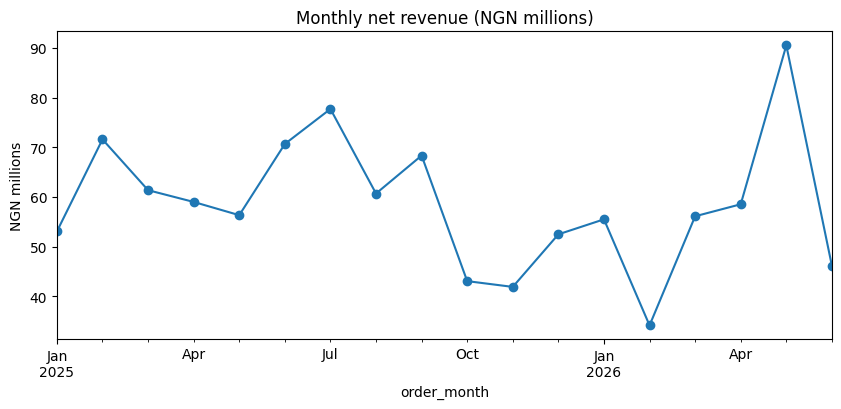

In [442]:
kpi = {                                                                  # headline numbers in a dictionary
    "Net revenue (NGN)": orders["net_revenue"].sum(),                    # total revenue after discounts
    "Orders": orders["order_id"].nunique(),                              # distinct orders
    "Order lines": len(orders),                                          # rows in the table
    "Customers": orders["customer_id"].nunique(),                        # distinct buyers
    "Units sold": orders["quantity"].sum(),                              # total quantity
    "Discounts given (NGN)": orders["discount_amount"].sum(),            # revenue sacrificed to discounts
}
order_value = orders.groupby("order_id")["net_revenue"].sum()            # revenue per order (sum its lines)
kpi["Average order value (NGN)"] = order_value.mean()                    # the true average order value
kpi["Median order value (NGN)"] = order_value.median()                   # the median is less affected by very large orders
print(pd.Series(kpi).map("{:,.0f}".format).to_string())                  # print the KPIs with thousands separators

monthly = orders.groupby("order_month")["net_revenue"].sum()             # revenue per month
growth = monthly.pct_change() * 100                                      # month over month growth
trend = monthly.rolling(3).mean()                                        # a 3 month rolling average to smooth the noise
summary = pd.DataFrame({"revenue_m": monthly / 1e6, "mom_pct": growth, "trend_3m": trend / 1e6}).round(1)   # tidy table in millions
print(summary.tail(8))                                                   # the latest months

best_month = monthly.idxmax()                                            # month with the highest revenue
print(f"\nBest month: {best_month} with NGN {monthly.max() / 1e6:,.1f}m")   # report it
ax = (monthly / 1e6).plot(kind="line", marker="o", figsize=(10, 4), title="Monthly net revenue (NGN millions)")   # pandas line chart
ax.set_ylabel("NGN millions")                                            # axis label

### Question 2: Categories and regions

                  revenue_m  share_pct
product_category                      
Electronics          536.20      50.70
Home & Kitchen       220.30      20.80
Groceries            129.70      12.30
Fashion              109.80      10.40
Beauty                35.50       3.40
Books                 25.40       2.40
product_category  Beauty  Books  Electronics  Fashion  Groceries  Home & Kitchen
region                                                                          
Abuja               4.40   5.40        72.00    18.60      21.00           30.40
Enugu               6.20   3.40        88.70    14.50      22.30           42.30
Ibadan              7.00   4.50        76.10    18.80      22.80           35.70
Kano                6.20   4.40        76.00    20.20      22.10           36.80
Lagos               4.50   4.20       103.80    15.90      18.70           40.40
Port Harcourt       7.20   3.60       119.70    21.80      22.80           34.60
strongest region-category pair: ('Port H

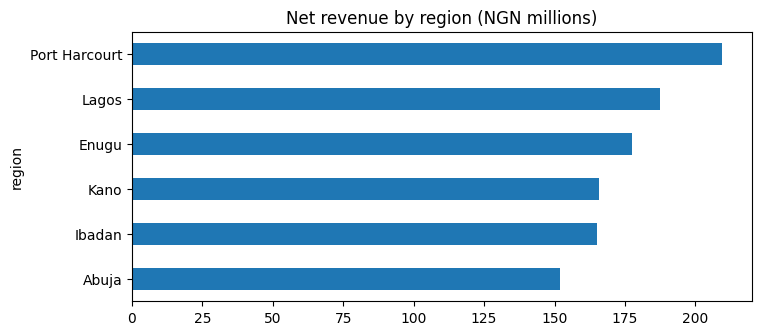

In [443]:
by_cat = orders.groupby("product_category", observed=True)["net_revenue"].sum().sort_values(ascending=False)   # revenue per category
share = (by_cat / by_cat.sum() * 100).round(1)                           # percentage share
print(pd.DataFrame({"revenue_m": (by_cat / 1e6).round(1), "share_pct": share}))   # category league table

heat = pd.pivot_table(orders, values="net_revenue", index="region", columns="product_category", aggfunc="sum", observed=True) / 1e6   # region by category grid
print(heat.round(1))                                                     # in NGN millions
print("strongest region-category pair:", heat.stack().idxmax(), round(heat.stack().max(), 1), "m")   # stack then idxmax finds the best cell

region_share = orders.groupby("region")["net_revenue"].sum().sort_values()   # revenue by region, smallest first
ax = (region_share / 1e6).plot(kind="barh", figsize=(8, 3.5), title="Net revenue by region (NGN millions)")   # horizontal bars

### Question 3: Customer concentration (Pareto)

In [444]:
cust_rev = orders.groupby("customer_id")["net_revenue"].sum().sort_values(ascending=False)   # revenue per customer, biggest first
cum_share = cust_rev.cumsum() / cust_rev.sum()                           # cumulative share of revenue as we move down the list
n_for_80 = int((cum_share <= 0.80).sum()) + 1                            # customers needed to reach 80 percent of revenue
print(f"{n_for_80} of {len(cust_rev)} customers ({n_for_80 / len(cust_rev):.0%}) generate 80% of revenue")   # the Pareto result
print(cust_rev.head(10).map("{:,.0f}".format).to_string())               # the ten most valuable customers

top10 = cust_rev.head(10).reset_index().merge(customers[["customer_id", "customer_name", "segment", "city"]], on="customer_id")   # enrich with names
print(top10[["customer_id", "customer_name", "segment", "city", "net_revenue"]].round(0))   # a named top-10 list

163 of 684 customers (24%) generate 80% of revenue
customer_id
C0666    122,320,080
C0211     29,177,180
C0778     27,132,490
C0295     21,777,380
C0831     16,325,200
C0372     16,288,640
C0707     15,775,600
C0516     15,164,360
C0441     14,748,320
C0110     13,555,300
  customer_id   customer_name    segment           city    net_revenue
0       C0666   Kunle Afolabi  Corporate          Enugu 122,320,080.00
1       C0211     Ebere Okeke  Corporate          Lagos  29,177,180.00
2       C0778   Kunle Oladipo        SME           Kano  27,132,490.00
3       C0295     Bayo Salami  Corporate  Port Harcourt  21,777,380.00
4       C0831    Emeka Nnamdi  Corporate         Ibadan  16,325,200.00
5       C0372      Tobi Lawal  Corporate          Abuja  16,288,640.00
6       C0707      Tobi Idowu  Corporate  Port Harcourt  15,775,600.00
7       C0516  Aisha Ogunleye  Corporate          Enugu  15,164,360.00
8       C0441    Ibrahim Ezeh  Corporate         Ibadan  14,748,320.00
9       C0110    

### Question 4: Segment value

In [445]:
seg = orders.groupby("segment").agg(                                     # compare customer segments
    customers=("customer_id", "nunique"),                                # distinct customers
    orders=("order_id", "nunique"),                                      # distinct orders
    revenue=("net_revenue", "sum"),                                      # revenue
).assign(                                                                # add derived measures
    revenue_per_customer=lambda d: d["revenue"] / d["customers"],        # average value of one customer
    orders_per_customer=lambda d: d["orders"] / d["customers"],          # purchase frequency
    revenue_share_pct=lambda d: d["revenue"] / d["revenue"].sum() * 100, # share of total revenue
).round(1)
print(seg.sort_values("revenue_per_customer", ascending=False))          # which segment is worth the most per customer

orders["signup_quarter"] = orders["signup_date"].dt.to_period("Q")       # cohort label: the quarter the customer signed up
cohort = orders.groupby("signup_quarter").agg(customers=("customer_id", "nunique"), revenue=("net_revenue", "sum"))   # cohort table
cohort["revenue_per_customer"] = (cohort["revenue"] / cohort["customers"]).round(0)   # value per customer in each cohort
print(cohort.tail(6))                                                    # do newer cohorts spend less? they have had less time

           customers  orders        revenue  revenue_per_customer  orders_per_customer  revenue_share_pct
segment                                                                                                  
Corporate         71     320 417,889,980.00          5,885,774.40                 4.50              39.50
SME              161     543 269,690,040.00          1,675,093.40                 3.40              25.50
Retail           452    1421 369,293,645.00            817,021.30                 3.10              34.90
                customers        revenue  revenue_per_customer
signup_quarter                                                
2024Q2                 76  99,809,120.00          1,313,278.00
2024Q3                 66  70,869,695.00          1,073,783.00
2024Q4                 68 120,853,135.00          1,777,252.00
2025Q1                 68 238,184,685.00          3,502,716.00
2025Q2                 57  93,073,440.00          1,632,867.00
2025Q3                 64  75

### Question 5: Do customers come back?

count   684.00
mean      3.30
std       5.40
min       1.00
25%       1.00
50%       2.00
75%       3.00
max      86.00
Name: order_id, dtype: float64
repeat customers: 66%
order_id
1    232
2    194
3    112
4     39
5     28
6     15
7     12
8      5
Name: count, dtype: int64
mean   184.00
50%    156.00
max    543.00
Name: active_days, dtype: float64


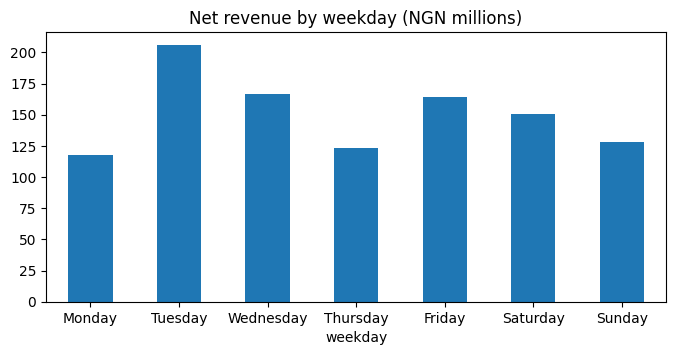

In [446]:
orders_per_customer = orders.groupby("customer_id")["order_id"].nunique()   # how many distinct orders each customer placed
print(orders_per_customer.describe().round(1))                           # distribution summary
repeat_rate = (orders_per_customer > 1).mean()                           # share of customers with more than one order
print(f"repeat customers: {repeat_rate:.0%}")                            # the repeat rate
print(orders_per_customer.value_counts().sort_index().head(8))           # how many customers placed 1, 2, 3... orders

first_last = orders.groupby("customer_id")["order_date"].agg(["min", "max"])   # first and last purchase date per customer
first_last["active_days"] = (first_last["max"] - first_last["min"]).dt.days    # time between first and last purchase
print(first_last["active_days"].describe().round(0)[["mean", "50%", "max"]])   # typical customer lifespan in days

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]   # logical order of weekdays
wk = orders.groupby("weekday")["net_revenue"].sum().reindex(weekday_order) / 1e6   # revenue per weekday in the right order
ax = wk.plot(kind="bar", figsize=(8, 3.5), title="Net revenue by weekday (NGN millions)", rot=0)   # bar chart

### Question 6: Is payroll in line with department budgets?

In [447]:
payroll = emp.groupby("department").agg(headcount=("employee_id", "count"), monthly_payroll=("salary", "sum")).reset_index()   # payroll per department
payroll["annual_payroll"] = payroll["monthly_payroll"] * 12              # twelve months of salaries
check = pd.merge(payroll, depts, on="department", how="left")            # attach the budgets (Unassigned has none)
check["payroll_pct_of_budget"] = (check["annual_payroll"] / check["annual_budget_ngn"] * 100).round(1)   # how much of the budget salaries consume
check["status"] = np.select(                                             # traffic light classification (first matching condition wins)
    [check["annual_budget_ngn"].isna(), check["payroll_pct_of_budget"] > 100, check["payroll_pct_of_budget"] > 85],   # no budget, over budget, close to budget
    ["No budget", "Over budget", "Watch"], default="OK")                 # everything else is fine
print(check[["department", "headcount", "annual_payroll", "annual_budget_ngn", "payroll_pct_of_budget", "status"]].round(0))   # the review table

    department  headcount  annual_payroll  annual_budget_ngn  payroll_pct_of_budget       status
0  Engineering        111  192,267,000.00     215,000,000.00                  89.00        Watch
1      Finance         76  111,843,000.00     125,000,000.00                  90.00        Watch
2           HR         49   52,962,000.00      90,000,000.00                  59.00           OK
3    Marketing         60   73,209,600.00      85,000,000.00                  86.00        Watch
4   Operations         91   99,887,400.00      98,000,000.00                 102.00  Over budget
5        Sales        113  143,896,200.00     135,000,000.00                 107.00  Over budget
6      Support         82   75,296,400.00     100,000,000.00                  75.00           OK
7   Unassigned         18   24,018,000.00                NaN                    NaN    No budget


### Capstone deliverable: one Excel workbook for management

In [448]:
with pd.ExcelWriter(f"{OUT_DIR}/Prodigy_Mart_Business_Review.xlsx", engine="openpyxl") as writer:   # one workbook, many sheets
    pd.Series(kpi, name="value").rename_axis("KPI").reset_index().to_excel(writer, sheet_name="KPIs", index=False)   # headline numbers
    summary.reset_index().astype({"order_month": str}).to_excel(writer, sheet_name="Monthly trend", index=False)    # monthly table (period converted to text)
    heat.round(2).to_excel(writer, sheet_name="Region x Category")       # the heat grid
    seg.reset_index().to_excel(writer, sheet_name="Segments", index=False)           # segment comparison
    top10.round(0).to_excel(writer, sheet_name="Top 10 customers", index=False)      # best customers
    check.to_excel(writer, sheet_name="Payroll vs budget", index=False)              # payroll review
print(pd.ExcelFile(f"{OUT_DIR}/Prodigy_Mart_Business_Review.xlsx").sheet_names)      # confirm the sheets

['KPIs', 'Monthly trend', 'Region x Category', 'Segments', 'Top 10 customers', 'Payroll vs budget']


---
# SOLUTIONS TO THE "YOUR TURN" CHALLENGES

Try each challenge before opening its solution. Every solution is runnable and commented.

### Solutions: Sections 3 to 5

In [449]:
# ---- Section 3, challenge 1
top_cities = pd.Series({"Lagos": 15_000_000, "Kano": 4_100_000, "Ibadan": 3_600_000, "Abuja": 3_500_000, "Port Harcourt": 3_200_000})   # dict gives labels
print(top_cities)                                                        # a Series built from a dictionary
# ---- Section 3, challenge 2
print(emp.size, emp.ndim)                                                # number of elements and dimensions
# ---- Section 4, challenge 1
banks_a = pd.DataFrame({"bank": ["UBA", "GTBank", "Zenith", "Access"], "founded": [1949, 1990, 1990, 1989], "hq_city": ["Lagos"] * 4})   # dict of lists
banks_b = pd.DataFrame([["UBA", 1949, "Lagos"], ["GTBank", 1990, "Lagos"], ["Zenith", 1990, "Lagos"], ["Access", 1989, "Lagos"]], columns=["bank", "founded", "hq_city"])   # list of lists
banks_c = pd.DataFrame([{"bank": "UBA", "founded": 1949, "hq_city": "Lagos"}, {"bank": "GTBank", "founded": 1990, "hq_city": "Lagos"},
                        {"bank": "Zenith", "founded": 1990, "hq_city": "Lagos"}, {"bank": "Access", "founded": 1989, "hq_city": "Lagos"}])   # list of dicts
print(banks_a.equals(banks_b), banks_b.equals(banks_c))                  # True True
# ---- Section 4, challenge 2
template = pd.DataFrame(columns=["date", "store", "sales"])              # empty frame with column names
template.loc[0] = ["2026-01-01", "Lagos", 1000]                          # add the first row with loc
template.loc[1] = ["2026-01-02", "Abuja", 850]                           # add a second row
print(template)                                                          # the filled template
# ---- Section 5, challenge 1
part = pd.read_csv(f"{DATA}/transactions_large.csv", usecols=["store", "amount", "channel"], nrows=5000)   # only 3 columns, 5000 rows
print(part.shape)                                                        # (5000, 3)
# ---- Section 5, challenge 2
q1_sheet = pd.read_excel(f"{DATA}/report.xlsx", sheet_name="Q1", skiprows=2)   # read the Q1 sheet
print(f"{q1_sheet['sales'].sum():,}")                                    # total Q1 sales
# ---- Section 5, challenge 3
print(pd.read_sql("SELECT COUNT(*) AS n_orders FROM orders", con=engine))   # count rows in the SQL orders table

Lagos            15000000
Kano              4100000
Ibadan            3600000
Abuja             3500000
Port Harcourt     3200000
dtype: int64
32400 2
True True
         date  store  sales
0  2026-01-01  Lagos   1000
1  2026-01-02  Abuja    850
(5000, 3)
90,195,000
   n_orders
0      1500


### Solutions: Sections 6 to 8

In [450]:
# ---- Section 6, challenge 2
print(orders_raw["payment_method"].value_counts().head(1))               # the most common payment method
print(orders_raw["region"].value_counts().head(15))                      # inconsistent spellings: lagos, LAGOS, ' Lagos '
# ---- Section 7, challenge 1
print(emp.iloc[10:15][["name", "city", "salary"]])                       # rows at positions 10 to 14, three columns
# ---- Section 7, challenge 2
copy_emp = emp.copy()                                                    # protect the real data
copy_emp.loc[copy_emp["age"] > 55, "status"] = "inactive"                # single loc assignment
print((copy_emp["age"] > 55).sum(), "employees older than 55 were set to inactive")
# ---- Section 7, challenge 3
print(emp.at[20, "department"])                                          # read one value by label
# ---- Section 8, challenge 1
print(emp[(emp["is_manager"]) & (emp["city"] == "Lagos") & (emp["salary"] > 120000)][["name", "salary"]])   # managers in Lagos earning above 120,000
# ---- Section 8, challenge 2
print(emp.query("age >= 25 and age <= 30 and department != 'Engineering'")[["name", "age", "department"]].head())   # query with inclusive age range
# ---- Section 8, challenge 3
region_clean = orders_raw["region"].str.strip().str.title()              # clean the messy spelling first
print(orders_raw[(orders_raw["quantity"] >= 4) & (region_clean == "Lagos")].shape[0], "large-quantity Lagos order lines")

payment_method
Transfer    1206
Name: count, dtype: int64
region
Ibadan             450
Port Harcourt      433
Enugu              425
Kano               425
Lagos              395
Abuja              395
 port harcourt      63
 enugu              58
 kano               56
IBADAN              52
KANO                48
 abuja              47
LAGOS               43
 ibadan             43
ABUJA               43
Name: count, dtype: int64
               name           city     salary
10    Ngozi Adebayo  Port Harcourt 141,900.00
11     Rotimi Idowu          Abuja 190,000.00
12    Aisha Balogun          Abuja  80,500.00
13       Adaeze Eze          Abuja 109,300.00
14  Adaeze Mohammed          Abuja  88,800.00


0 employees older than 55 were set to inactive
Finance
                 name     salary
42       Bisi Afolabi 125,300.00
60       Nneka Salami 141,500.00
99    Yetunde Balogun 166,000.00
101        Femi Yusuf 147,150.00
108  Yetunde Mohammed 135,000.00
110    Tunde Ogunleye 175,500.00
119       Gift Okafor 190,000.00
127      Musa Fashola 150,200.00
211      Mariam Ajayi 127,800.00
218        Dayo Sanni 145,900.00
223     Ebere Adewale 183,100.00
231      Adaeze Okeke 140,600.00
276     Ebere Danjuma 190,000.00
311      Femi Anyanwu 135,600.00
328   Yetunde Danjuma 122,000.00
329      Kunle Nnamdi 134,900.00
331    Abdul Abubakar 148,600.00
384   Halima Suleiman 124,800.00
407      Musa Akinola 180,000.00
418     Emeka Balogun 189,500.00
424      Halima Yusuf 152,400.00
428          Kemi Obi 137,000.00
451     Gift Ogunleye 166,300.00
457    Hauwa Suleiman 131,100.00
515      Halima Okeke 137,600.00
548        Dayo Lawal 145,700.00
553     Mariam Chukwu 128,500.00
561     Temitope Umar

### Solutions: Sections 9 to 12

In [451]:
# ---- Section 9, challenge 1
print(orders_raw["customer_id"].isna().sum(), "missing customer ids")    # dropping them loses revenue we could still attribute by region and product
# ---- Section 9, challenge 2
sol = orders_raw.copy()                                                  # work on a copy
sol["unit_price"] = pd.to_numeric(sol["unit_price"], errors="coerce")    # text placeholders become NaN
sol["unit_price"] = sol["unit_price"].fillna(sol.groupby("product")["unit_price"].transform("median"))   # median per PRODUCT
print(sol["unit_price"].isna().sum(), "prices still missing")            # 0 or nearly 0
# ---- Section 9, challenge 3
abuja = ds[ds["store"] == "Abuja-Wuse"]["sales"]                         # the Abuja store series
repaired = abuja.interpolate(method="time")                              # time-aware repair
gaps = abuja[abuja.isna()].index[:3]                                     # first three missing dates
print(repaired.loc[gaps].round(0))                                       # the repaired values
# ---- Section 10, challenge 1
d = orders_raw.duplicated().sum()                                        # exact duplicate order lines
print(d, f"({d / len(orders_raw):.1%} of rows)")                         # count and percentage
# ---- Section 10, challenge 2
rows_per_order = orders_raw.groupby("order_id").size()                   # lines per order id
print((rows_per_order > 1).sum(), "orders have several lines; a TRUE duplicate repeats the whole row, a legitimate repeat has a different product/quantity")
# ---- Section 11, challenge 1
bad_prices = orders_raw["unit_price"][pd.to_numeric(orders_raw["unit_price"], errors="coerce").isna() & orders_raw["unit_price"].notna()]   # non-numeric entries
print(bad_prices.value_counts())                                         # the offending texts
# ---- Section 11, challenge 2
dates = pd.to_datetime(orders_raw["order_date"], format="%Y-%m-%d", errors="coerce")   # explicit format
print(dates.min().date(), "to", dates.max().date())                      # first and last order date
# ---- Section 11, challenge 3
q = orders_raw["quantity"]                                               # quantity as int64
print(q.memory_usage() , "->", pd.to_numeric(q, downcast="integer").memory_usage(), "bytes")   # int8 is eight times smaller

25 missing customer ids
0 prices still missing
date
2025-01-20   775,303.00
2025-02-27   723,933.00
2025-11-02   947,348.00
Name: sales, dtype: float64
40 (1.2% of rows)
706 orders have several lines; a TRUE duplicate repeats the whole row, a legitimate repeat has a different product/quantity
unit_price
unknown    20
Name: count, dtype: int64
2025-01-01 to 2026-06-30
25780 -> 3338 bytes


In [452]:
# ---- Section 12, challenge 1
before = orders_raw["region"].nunique()                                  # distinct spellings before cleaning
after = orders_raw["region"].str.strip().str.title().nunique()           # distinct values after cleaning
print(before, "->", after)                                               # many spellings collapse into six regions
# ---- Section 12, challenge 2
names = customers["customer_name"].str.split(" ", n=1, expand=True)      # split on the first space
customers_tmp = customers.assign(first_name=names[0], last_name=names[1])   # add the two columns
print(customers_tmp[["customer_name", "first_name", "last_name"]].head(3))
# ---- Section 12, challenge 3
personal = ["gmail.com", "yahoo.com", "outlook.com"]                     # personal email providers
print(emp[~emp["email_domain"].isin(personal) & emp["email_domain"].notna()]["email_domain"].value_counts())   # company addresses

24 -> 6
   customer_name first_name last_name
0  Rotimi Chukwu     Rotimi    Chukwu
1  Ifeanyi Aliyu    Ifeanyi     Aliyu
2      Emeka Obi      Emeka       Obi
email_domain
prodigy.ng    167
Name: count, dtype: int64


### Solutions: Sections 13 to 16

In [453]:
# ---- Section 13, challenge 1
o = orders_raw.copy()                                                    # fresh copy of the raw orders
o["unit_price"] = pd.to_numeric(o["unit_price"], errors="coerce")        # numeric price
o["revenue"] = o["unit_price"] * o["quantity"] * (1 - o["discount_pct"] / 100)   # the revenue formula
# ---- Section 13, challenge 2
o["order_size"] = np.select([o["revenue"] > 300_000, o["revenue"] > 100_000], ["Large", "Medium"], default="Small")   # NaN revenue falls to Small
print(o["order_size"].value_counts())
# ---- Section 13, challenge 3
o["pay_code"] = o["payment_method"].map({"Card": "CARD", "Transfer": "TRF", "Cash on Delivery": "COD", "USSD": "USSD"})   # short codes
print(o["pay_code"].value_counts())
# ---- Section 14, challenge 1
print(emp.sort_values(["city", "hire_date"], ascending=[True, False])[["city", "name", "hire_date"]].head(10))   # city A-Z, newest hire first
# ---- Section 14, challenge 2
print(emp.sort_values("hire_date").groupby("department").head(3)[["department", "name", "hire_date"]].sort_values(["department", "hire_date"]).head(9))   # 3 longest serving each
# ---- Section 14, challenge 3
print(o.nlargest(5, "unit_price")[["order_id", "product", "unit_price"]])  # the five most expensive order lines

order_size
Small     1636
Medium     837
Large      733
Name: count, dtype: int64
pay_code
TRF     1206
CARD    1051
COD      643
USSD     306
Name: count, dtype: int64
      city            name  hire_date
455  Abuja    Bayo Oladipo 2026-05-20
367  Abuja    Bayo Olawale 2026-03-29
203  Abuja     Gift Onuoha 2026-02-09
461  Abuja      Uche Idowu 2025-12-03
593  Abuja  Hauwa Abubakar 2025-11-25
551  Abuja    Sadiq Onuoha 2025-10-05
7    Abuja     Chika Lawal 2025-09-25
527  Abuja     Ibrahim Obi 2025-08-14
292  Abuja  Yetunde Chukwu 2025-07-21
494  Abuja  Ngozi Mohammed 2025-06-28
      department             name  hire_date
499  Engineering     Ruth Fashola 2014-02-27
154  Engineering        Musa Umar 2014-04-09
90   Engineering    Kelechi Sanni 2014-04-11
587      Finance    Aisha Okonkwo 2014-02-22
464      Finance     Musa Okonkwo 2014-03-13
404      Finance  Folake Abubakar 2014-08-03
421           HR    Halima Okafor 2014-02-10
473           HR     Nneka Onuoha 2014-05-16
270     

In [454]:
# ---- Section 15, challenge 1
print(emp.groupby("city").agg(staff=("employee_id", "count"), avg_salary=("salary", "mean"), manager_share=("is_manager", "mean")).round(2))   # mean of booleans is a share
# ---- Section 15, challenge 2
emp["pct_of_city_max"] = emp["salary"] / emp.groupby("city")["salary"].transform("max") * 100   # relative to the best paid in the same city
print(emp[["name", "city", "salary", "pct_of_city_max"]].head(3).round(1))
# ---- Section 15, challenge 3
print(emp.groupby("department")[quarter_cols].mean().mean(axis=1).sort_values(ascending=False).round(1).head(3))   # average of four quarterly means per department
# ---- Section 15, challenge 4
python_by_city = emp.groupby("city").filter(lambda g: g["skill_python"].sum() >= 20)   # keep cities with at least 20 Python users
print(python_by_city["city"].unique())
# ---- Section 16, challenge 1
tmp = pd.merge(orders_raw, customers, on="customer_id", how="left", validate="many_to_one", indicator=True)   # each order has one customer
print((tmp["_merge"] == "left_only").sum(), "orders without a matching customer (missing customer_id)")
# ---- Section 16, challenge 2
hist = sh.pivot(index="emp_id", columns="year", values="monthly_salary")   # one row per employee, one column per year
hist["growth_pct"] = (hist[2026] / hist[2024] - 1) * 100                 # growth from 2024 to 2026
print(hist.head(3).round(1))
# ---- Section 16, challenge 3
two_cities = pd.concat([customers[customers["city"] == "Lagos"], customers[customers["city"] == "Abuja"]], keys=["Lagos", "Abuja"])   # keys label each block
print(two_cities.index.levels[0].tolist(), two_cities.shape)

               staff  avg_salary  manager_share
city                                           
Abuja            126  111,406.75           0.16
Enugu             46  106,126.09           0.20
Ibadan            70  106,602.14           0.16
Kano              67  105,039.55           0.13
Lagos            219  107,047.03           0.18
Port Harcourt     72  105,363.19           0.10
            name    city     salary  pct_of_city_max
0     Emeka Igwe   Lagos  96,600.00            50.80
1  Amaka Ibrahim    Kano 137,100.00            72.20
2    Aisha Bello  Ibadan 140,600.00            74.00
department
Unassigned   73.30
HR           73.20
Support      72.20
dtype: float32
['Lagos' 'Kano' 'Port Harcourt' 'Abuja']
25 orders without a matching customer (missing customer_id)
year         2024       2025       2026  growth_pct
emp_id                                             
00001  118,800.00 127,100.00 136,000.00       14.50
00002  122,700.00 131,300.00 140,400.00       14.40
00004   68,4

### Solutions: Sections 17 to 21

In [455]:
# ---- Section 17, challenge 1
print(pd.pivot_table(emp, values="salary", index="department", columns="city", aggfunc="mean", margins=True).round(0).head(4))   # average salary grid with totals
# ---- Section 17, challenge 2
scores_long = pd.melt(emp[["employee_id", "q1", "q2", "q3", "q4"]], id_vars="employee_id", var_name="quarter", value_name="score")   # long format
print(scores_long.groupby("quarter")["score"].mean().round(1))
# ---- Section 17, challenge 3
print(pd.crosstab(emp["salary_band"], emp["city"], normalize="index").round(2).head(3))   # share of each band that sits in each city (row percentages)
# ---- Section 18, challenge 1
ec = emp.set_index(["city", "department"]).sort_index()                 # two-level index
print(ec.xs(("Ibadan", "Support"))[["name"]].head(3))                    # a full key as a tuple via xs
print(ec.loc[("Ibadan", "Support"), ["name"]].head(3))                   # the same with loc and a tuple
# ---- Section 18, challenge 2
grid = emp.groupby(["city", "department"])["salary"].mean().unstack()    # city by department grid
print(grid.idxmax(axis=1))                                               # best-paying department in each city

city             Abuja      Enugu     Ibadan       Kano      Lagos  Port Harcourt        All
department                                                                                  
Engineering 146,852.00 138,422.00 149,150.00 146,656.00 148,007.00     129,916.00 144,345.00
Finance     131,227.00 137,040.00 126,160.00 116,225.00 120,673.00     116,267.00 122,635.00
HR           95,725.00  88,167.00  84,180.00 116,500.00  89,637.00      84,725.00  90,071.00
Marketing   107,264.00  88,600.00 109,888.00 105,578.00  98,756.00      89,100.00 101,680.00
quarter
q1   72.00
q2   71.70
q3   71.40
q4   72.80
Name: score, dtype: float32
city         Abuja  Enugu  Ibadan  Kano  Lagos  Port Harcourt
salary_band                                                  
Entry         0.08   0.08    0.15  0.00   0.54           0.15
High          0.22   0.07    0.12  0.11   0.36           0.13
Standard      0.20   0.08    0.12  0.12   0.37           0.11
                            name
city   department  

In [456]:
# ---- Section 19, challenge 1
print(ds["sales"].resample("ME").sum().idxmax().strftime("%B %Y"), "had the highest total sales")   # best month
print(ds[ds["store"] == "Abuja-Wuse"].groupby("day_name")["sales"].mean().idxmax(), "is the best weekday for Abuja-Wuse")
# ---- Section 19, challenge 2
tx7 = ds.groupby("store")["transactions"].rolling(7).mean()              # 7 day average per store (a MultiIndex result)
print(tx7.groupby(level="store").tail(1).round(1))                       # latest value for each store
# ---- Section 19, challenge 3
monthly_orders = orders.groupby("order_month")["order_id"].nunique()     # distinct orders per month
print(monthly_orders.idxmax(), monthly_orders.max())                     # busiest month
# ---- Section 19, challenge 4
print(web_lagos.groupby(web_lagos.index.hour)["visitors"].mean().idxmin(), "is the quietest hour (Lagos time)")
# ---- Section 20, challenge 1
ab = ds[ds["store"] == "Abuja-Wuse"]["sales"].interpolate(method="time")  # repaired Abuja series
ab14 = ab.rolling(14).mean()                                             # 14 day rolling average
print(ab14.idxmax().date(), round(ab14.max()))                           # date and value of the peak
# ---- Section 20, challenge 2
lg = lagos.to_frame("sales")                                             # Lagos series as a frame
lg["mtd"] = lg.groupby([lg.index.year, lg.index.month])["sales"].cumsum()   # cumulative within each year-month
print(lg.loc["2026-03-01":"2026-03-03"].round(0))                        # restarts at the first of each month
# ---- Section 20, challenge 3
print(w[["sales", "avg_7d", "ewm_7"]].diff().abs().mean().round(0).to_dict())   # lower is smoother

December 2025 had the highest total sales
Sunday is the best weekday for Abuja-Wuse
store              date      
Abuja-Wuse         2026-06-30   49.90
Lagos-Ikeja        2026-06-30   71.40
Port Harcourt-GRA  2026-06-30   38.30
Name: transactions, dtype: float64
2025-07 153
6 is the quietest hour (Lagos time)
2025-12-13 1001747
                  sales          mtd
date                                
2026-03-01 1,374,318.00 1,374,318.00
2026-03-02 1,105,135.00 2,479,453.00
2026-03-03 1,156,396.00 3,635,849.00
{'sales': 113413.0, 'avg_7d': 13397.0, 'ewm_7': 23651.0}


In [457]:
# ---- Section 21, challenge 1
for col in ["city", "status"]:                                           # two low-cardinality columns
    b = emp[col].memory_usage(deep=True)                                 # bytes as text
    a = emp[col].astype("category").memory_usage(deep=True)              # bytes as category
    print(col, b, "->", a)
# ---- Section 21, challenge 2
band_type = pd.CategoricalDtype(["Entry", "Standard", "High"], ordered=True)   # ordered band type
emp["salary_band"] = emp["salary_band"].astype(band_type)                # apply it
print(emp.groupby("salary_band", observed=True)["age"].mean().round(1))  # Entry, Standard, High in that order
# ---- Section 21, challenge 3
_ = reduce_memory(pd.read_csv(f"{DATA}/transactions_large.csv", nrows=100_000))   # prints the saving

city 33111 -> 1236
status 33282 -> 952
salary_band
Entry      35.00
Standard   34.10
High       34.10
Name: age, dtype: float64
memory: 30,026 KB -> 8,204 KB (73% smaller)


### Solutions: Sections 22 and 23

In [458]:
# ---- Section 22, challenge 1
with pd.ExcelWriter(f"{OUT_DIR}/pivot_and_long.xlsx", engine="openpyxl") as writer:         # one workbook
    pivot.to_excel(writer, sheet_name="Pivot")                           # the pivot table sheet
    long.to_excel(writer, sheet_name="Long", index=False)                # the long format sheet
print(pd.ExcelFile(f"{OUT_DIR}/pivot_and_long.xlsx").sheet_names)
# ---- Section 22, challenge 2
t0 = time.perf_counter(); pd.read_csv(f"{DATA}/orders.csv"); t_c = time.perf_counter() - t0   # time the CSV read
orders_raw.to_parquet(f"{OUT_DIR}/orders_raw.parquet", index=False)      # save as Parquet
t0 = time.perf_counter(); pd.read_parquet(f"{OUT_DIR}/orders_raw.parquet"); t_p = time.perf_counter() - t0   # time the Parquet read
print(f"CSV {t_c * 1000:.1f} ms ({os.path.getsize(f'{DATA}/orders.csv') / 1024:.0f} KB) | Parquet {t_p * 1000:.1f} ms ({os.path.getsize(f'{OUT_DIR}/orders_raw.parquet') / 1024:.0f} KB)")
# ---- Section 22, challenge 3
by_store_month.reset_index().assign(month=lambda d: d["date"].dt.strftime("%Y-%m")).drop(columns="date").to_sql("store_month", con=out_engine, if_exists="replace", index=False)   # write the table
print(pd.read_sql('SELECT month, "Lagos-Ikeja" AS lagos FROM store_month ORDER BY lagos DESC LIMIT 1', con=out_engine))   # best month for Lagos via SQL
# ---- Section 23, challenge 1
sub = o.head(10_000)                                                     # 10,000 rows
t0 = time.perf_counter(); r = [row["unit_price"] * row["quantity"] for _, row in sub.iterrows()]; t_i = time.perf_counter() - t0   # iterrows
t0 = time.perf_counter(); r2 = sub["unit_price"] * sub["quantity"]; t_v = time.perf_counter() - t0   # vectorised
print(f"iterrows {t_i:.3f}s vs vectorised {t_v * 1000:.2f} ms: {t_i / t_v:,.0f}x faster")
# ---- Section 23, challenge 2
totals = pd.Series(dtype="float64")                                      # running totals per store
for chunk in pd.read_csv(f"{DATA}/transactions_large.csv", chunksize=30_000):   # never hold the whole file
    part = chunk[chunk["status"] == "success"].groupby("store")["amount"].sum()   # aggregate this chunk
    totals = totals.add(part, fill_value=0)                              # add to the running totals
print(totals.round(0))
# ---- Section 23, challenge 3
mem = tx_csv.memory_usage(deep=True).drop("Index")                       # memory per column
print(mem.idxmax(), "uses the most memory:", f"{mem.max() / 1e6:.1f} MB")   # usually a text column
print(f"after category: {tx_csv[mem.idxmax()].astype('category').memory_usage(deep=True) / 1e6:.2f} MB")   # shrink it

['Pivot', 'Long']
CSV 21.2 ms (249 KB) | Parquet 32.1 ms (53 KB)
     month         lagos
0  2025-12 42,637,855.00
iterrows 1.156s vs vectorised 299.46 ms: 4x faster
store
Abuja-Wuse          803,571,250.00
Lagos-Ikeja         801,774,673.00
Port Harcourt-GRA   805,140,610.00
dtype: float64
store uses the most memory: 9.3 MB
after category: 0.15 MB


---
# WHERE TO GO NEXT

1. **Visualisation:** Matplotlib, Seaborn and Plotly for richer charts.
2. **Statistics and Exploratory Data Analysis:** distributions, correlation, hypothesis tests (SciPy and statsmodels).
3. **Machine learning:** scikit-learn pipelines take your clean DataFrames directly.
4. **Scale:** when data outgrows memory, move to Polars, DuckDB or PySpark. The mental model you built here transfers directly.

> *"Clean data and a clear question beat a clever model every time."*

---

**Kajola Gbenga**
**Data Scientist & AI Engineer**